### Test Harness - Joe
Run the following only instead of whole notebook if you don't want to wait 2+ hrs, then select cells you want

In [125]:
### Libaries - Joe
import sklearn
import time
import math
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.table as tb
from sklearn.datasets import fetch_california_housing, fetch_openml
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier, GradientBoostingRegressor, VotingClassifier, StackingClassifier
from sklearn.ensemble import BaggingRegressor, ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import accuracy_score, root_mean_squared_error, mean_absolute_error, mean_squared_error, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.utils import resample
from scipy.stats import mode
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix

In [2]:
### Random Seeds - Joe
RANDOM_SEEDS = [1,2,3,4,5]

In [3]:
### Data - Joe
fashionMNIST = fetch_openml('Fashion-MNIST')
californiaHousing = fetch_california_housing()

In [4]:
### Helper stratified split from last hw iris_utils - Joe
def stratified_split(X, y, test_fraction=0.3, seed=0):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [5]:
### Classification - split data - Joe
xtrs = []
xvals = []
ytrs = []
yvals = []
xtes = []
ytes = []

for seed in RANDOM_SEEDS:
    # take 15k needed ~ 1/4 of dataset
    X = fashionMNIST.data[:15000].to_numpy()
    y = fashionMNIST.target[:15000].to_numpy()

    # split into 10,000 train, 5,000 val
    xtr, xval, ytr, yval = stratified_split(X, y, test_fraction=1/3, seed=seed)

    # take test
    xte = fashionMNIST.data[60000:].to_numpy()
    yte = fashionMNIST.target[60000:].to_numpy()

    xtrs.append(xtr)
    xvals.append(xval)
    ytrs.append(ytr)
    yvals.append(yval)
    xtes.append(xte)
    ytes.append(yte)

In [6]:
### Regression - split data - Joe
regX = californiaHousing.data
regy = californiaHousing.target

regxtrs,regxvals,regytrs,regyvals,regxtes,regytes = [],[],[],[],[],[]

for l in RANDOM_SEEDS:
    regxtr, regxte, regytr, regyte = train_test_split(regX,regy, test_size=0.2, random_state=l)
    regxtr,regxval, regytr,regyval = train_test_split(regxtr,regytr, test_size=0.2, random_state=l)
    regxtrs.append(regxtr)
    regytrs.append(regytr)
    regxvals.append(regxval)
    regyvals.append(regyval)
    regxtes.append(regxte)
    regytes.append(regyte)

In [7]:
### Helper functions for metrics - Joe
# return the mean and standard deviation of a list of values
def mean_std(vals):
    n = len(vals)
    mu = sum(vals) / n

    s = 0
    for val in vals:
        s += (val-mu)**2
    std = (s / (n - 1))**0.5
    return (mu,std)

# given a list with [seeds][depth / other]
# return a list that has the (mean,std) tuples for the values
def calcStats(vals, sweep):
    stats = []
    # not a defined list, just get the length of the columns
    if sweep is None:
        sweep = range(len(vals[0]))
    # iterate by columns
    for i in range(len(sweep)):
        valuesAcrossDepth = []
        # iterate through seeds and calculate mean,std
        for l in range(len(RANDOM_SEEDS)):
            valuesAcrossDepth.append(vals[l][i])
        stats.append(mean_std(valuesAcrossDepth))
    return stats
# Just formatting the mean, std
def combine(stats):
    return ["{:.3f} ± {:.3f} ".format(mu, std) for mu, std in stats]

### PART 1 - JOE

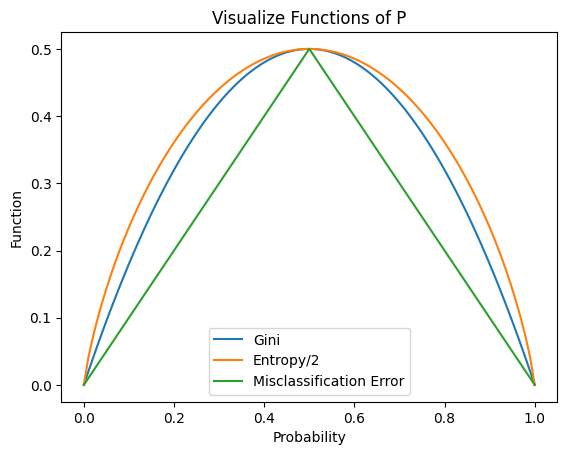

In [8]:
### part 1a - visualize the functions - Joe
# grab values 0 to 1 stepping 0.01
p = np.arange(0,1.01,0.01)
ginis = []
ents = []
misses = []
# functions
def gini(p):
    return 1 - p**2 - (1-p)**2
def ent(p):
    if p ==0 or p==1:
        return 0
    return -0.5*((p*np.log2(p)) + (1-p)*np.log2(1-p))
def mis(p):
    return 1 - max(p,1-p)

# calculate the functions
for val in p:
    ginis.append(gini(val))
    ents.append(ent(val))
    misses.append(mis(val))

# plot the results
plt.plot(p, ginis, label="Gini")
plt.plot(p, ents, label="Entropy/2")
plt.plot(p,misses, label="Misclassification Error")
plt.xlabel("Probability")
plt.ylabel("Function")
plt.title("Visualize Functions of P")
plt.legend(loc='lower center')

In [9]:
### part 1b - how often the two criteria choose the same feature at the root and at depth 1–2 - Joe
def getFeaturesAtDepth1_2(model):
    tree = model.tree_
    features = {}

    # root
    if tree.feature[0] != -2:
        features[""] = tree.feature[0]

    # depth 1
    left = tree.children_left[0]
    right = tree.children_right[0]

    # make sure it exists
    if left != -1 and tree.feature[left] != -2:
        features["L"] = tree.feature[left]
    if right != -1 and tree.feature[right] != -2:
        features["R"] = tree.feature[right]

    # depth 2
    for node, path in [(left, "L"), (right, "R")]: # iterate to L, R, RR, RL, LL, LR
        if node == -1:
            continue

        left2 = tree.children_left[node]
        right2 = tree.children_right[node]

        # make sure exists
        if left2 != -1 and tree.feature[left2] != -2:
            features[path + "L"] = tree.feature[left2]
        if right2 != -1 and tree.feature[right2] != -2:
            features[path + "R"] = tree.feature[right2]

    return features

In [10]:
### Part 1b - running models - Joe
entropyTrees = []
entropyTrainAccuracies = []
entropyValidationAccuracies = []
entropyTimes = []
entropyLeaves = []
entropyActualDepths = []
giniTrees = []
giniTrainAccuracies = []
giniValidationAccuracies = []
giniTimes = []
giniLeaves = []
giniActualDepths = []

for l in range(len(RANDOM_SEEDS)):
    print(seed)
    depths = [2,4,6,8,10,12,15,20,None]
    currEntropyTrees = []
    currEntropyTrainAccuracies = []
    currEntropyValidationAccuracies = []
    currEntropyTimes = []
    currEntropyLeaves = []
    currEntropyActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        entropyTree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_SEEDS[l], max_depth=depth)
        entropyTree.fit(xtrs[l], ytrs[l])

        # training accuracy
        entropyTreePredictions = entropyTree.predict(xtrs[l])
        entropyTrainAccuracy = accuracy_score(ytrs[l], entropyTreePredictions)

        # validation accuracy
        entropyTreePredictions = entropyTree.predict(xvals[l])
        entropyValidationAccuracy = accuracy_score(yvals[l], entropyTreePredictions)

        # update lists
        end = time.time()
        currEntropyTimes.append(end-start)
        currEntropyTrainAccuracies.append(entropyTrainAccuracy)
        currEntropyValidationAccuracies.append(entropyValidationAccuracy)
        currEntropyLeaves.append(entropyTree.get_n_leaves())
        currEntropyTrees.append(entropyTree)
        currEntropyActualDepths.append(entropyTree.get_depth())

    print("Entropy Done")
    currGiniTrees = []
    currGiniTrainAccuracies = []
    currGiniValidationAccuracies = []
    currGiniTimes = []
    currGiniLeaves = []
    currGiniActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        giniTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], max_depth=depth)
        giniTree.fit(xtrs[l], ytrs[l])
        
        # training accuracy
        giniTreePredictions = giniTree.predict(xtrs[l])
        giniTrainError = accuracy_score(ytrs[l], giniTreePredictions)

        # validation accuracy
        giniTreePredictions = giniTree.predict(xvals[l])
        giniValidationError = accuracy_score(yvals[l], giniTreePredictions)

        # update lists
        end = time.time()
        currGiniTimes.append(end-start)
        currGiniTrainAccuracies.append(giniTrainError)
        currGiniValidationAccuracies.append(giniValidationError)
        currGiniLeaves.append(giniTree.get_n_leaves())
        currGiniActualDepths.append(giniTree.get_depth())
        currGiniTrees.append(giniTree)

    print("Gini Done")
    # append final values obtained
    entropyTrees.append(currEntropyTrees)
    entropyTrainAccuracies.append(currEntropyTrainAccuracies)
    entropyValidationAccuracies.append(currEntropyValidationAccuracies)
    entropyTimes.append(currEntropyTimes)
    entropyLeaves.append(currEntropyLeaves)
    entropyActualDepths.append(currEntropyActualDepths)
    giniTrees.append(currGiniTrees)
    giniTrainAccuracies.append(currGiniTrainAccuracies)
    giniValidationAccuracies.append(currGiniValidationAccuracies)
    giniTimes.append(currGiniTimes)
    giniLeaves.append(currGiniLeaves)
    giniActualDepths.append(currGiniActualDepths)


5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done


In [11]:
### part 1b - compile results - Joe
entropyTrainAccStats = calcStats(entropyTrainAccuracies, sweep=depths)
entropyValidationAccStats = calcStats(entropyValidationAccuracies, sweep=depths)
entropyTimeStats = calcStats(entropyTimes, sweep=depths)
entropyLeaveStats= calcStats(entropyLeaves, sweep=depths)
entropyAcDepthStats = calcStats(entropyActualDepths, sweep=depths)
giniTrainAccStats = calcStats(giniTrainAccuracies, sweep=depths)
giniValidationAccStats = calcStats(giniValidationAccuracies, sweep=depths)
giniTimeStats = calcStats(giniTimes, sweep=depths)
giniLeaveStats = calcStats(giniLeaves, sweep=depths)
giniAcDepthStats = calcStats(giniActualDepths, sweep=depths)

In [12]:
# Part 1b - matches at depth - Joe
# compare features located on both trees, at root, depth1, depth 2
rootList = []
depth1List = []
depth2list = []

for l in range(len(RANDOM_SEEDS)):
    matches = [0, 0, 0]
    totals = [0, 0, 0]

    for entropyTree, giniTree in zip(entropyTrees[l], giniTrees[l]):
        entropyFeatures = getFeaturesAtDepth1_2(entropyTree)
        giniFeatures = getFeaturesAtDepth1_2(giniTree)

        # total positions for both trees via union
        paths = entropyFeatures.keys() | giniFeatures.keys()

        for path in paths:
            depth = len(path)
            totals[depth] += 1

            # make sure path exists for both
            if path in entropyFeatures and path in giniFeatures:
                # if match increment matches at depth counter
                if entropyFeatures[path] == giniFeatures[path]:
                    matches[depth] += 1
                    
    # division by zero check
    if totals[0] > 0:
        rootList.append(matches[0] / totals[0])
    if totals[1] > 0:
        depth1List.append(matches[1] / totals[1])
    if totals[2] > 0:
        depth2list.append(matches[2] / totals[2])

#calculate estimates
rootMean, rootStd = mean_std(rootList)
depth1Mean, depth1Std = mean_std(depth1List)
depth2Mean, depth2Std = mean_std(depth2list)
totalmean, totalstd = mean_std(rootList + depth1List + depth2list)

print("Root agreement: {:.3f} ± {:.3f}".format(rootMean, rootStd))
print("Depth 1 agreement: {:.3f} ± {:.3f}".format(depth1Mean, depth1Std))
print("Depth 2 agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))
print("Total agreement: {:.3f} ± {:.3f}".format(totalmean, totalstd))

Root agreement: 0.000 ± 0.000
Depth 1 agreement: 0.000 ± 0.000
Depth 2 agreement: 0.050 ± 0.112
Total agreement: 0.017 ± 0.065


Text(0.5, 1.0, 'Train Accuracy vs Depth')

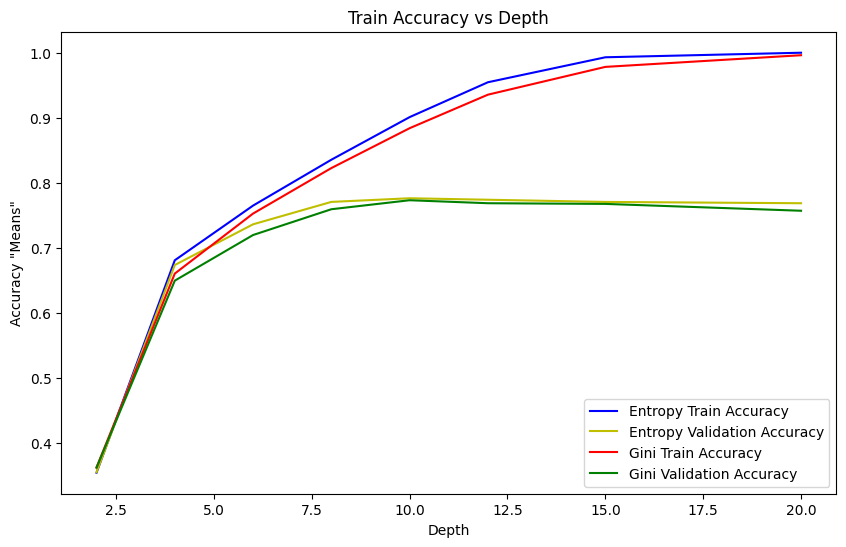

In [13]:
### part 1b - train and validation accuracy vs. depth (one plot, both criteria) - Joe
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in entropyTrainAccStats], label='Entropy Train Accuracy', color='b')
ax.plot(depths, [i[0] for i in entropyValidationAccStats], label='Entropy Validation Accuracy', color='y')
ax.set_xlabel('Depth')
ax.set_ylabel('Accuracy "Means"')
ax.plot(depths, [i[0] for i in giniTrainAccStats], label='Gini Train Accuracy', color='r')
ax.plot(depths, [i[0] for i in giniValidationAccStats], label='Gini Validation Accuracy', color='g')
ax.legend(loc='lower right')
ax.set_title("Train Accuracy vs Depth")

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\3157024092.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


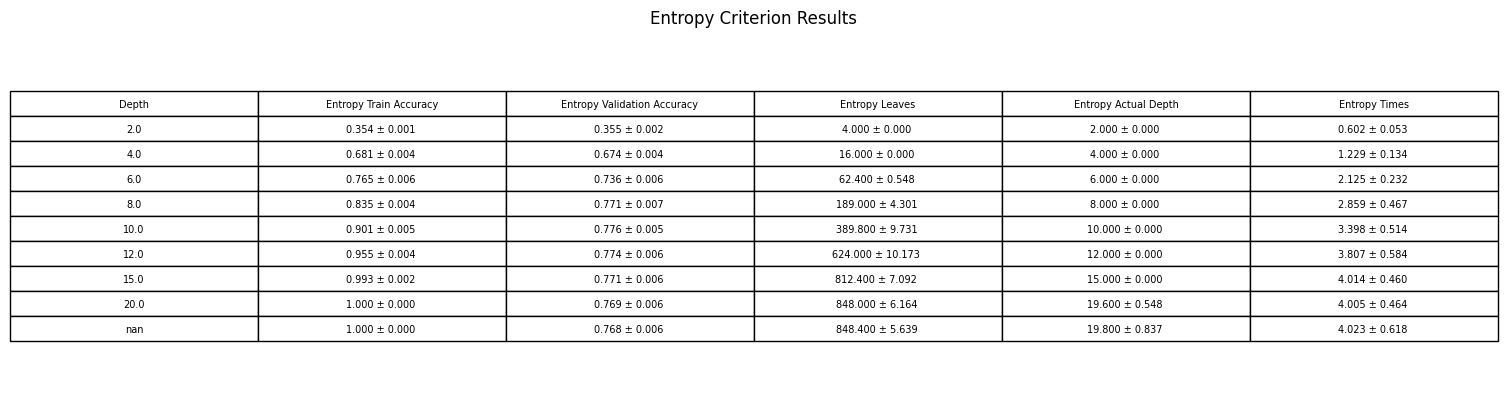

In [14]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples - Joe
table = pd.DataFrame({
    'Depth': depths,
    'Entropy Train Accuracy': combine(entropyTrainAccStats),
    'Entropy Validation Accuracy': combine(entropyValidationAccStats),
    'Entropy Leaves': combine(entropyLeaveStats),
    'Entropy Actual Depth': combine(entropyAcDepthStats),
    'Entropy Times': combine(entropyTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.title("Entropy Criterion Results")
plt.tight_layout()
plt.show()


C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\4572949.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


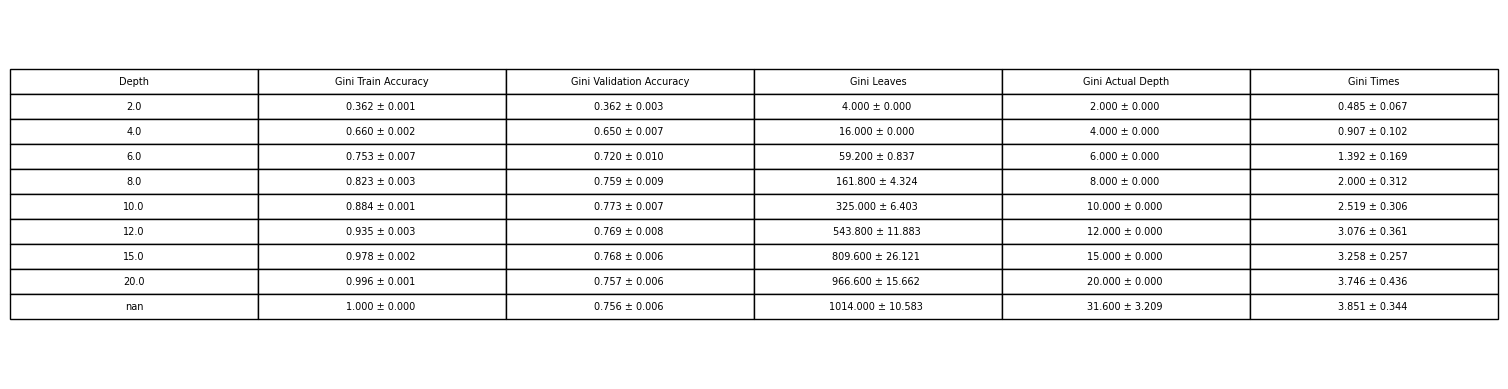

Text(0.5, 1.0, 'Gini Criterion Results')

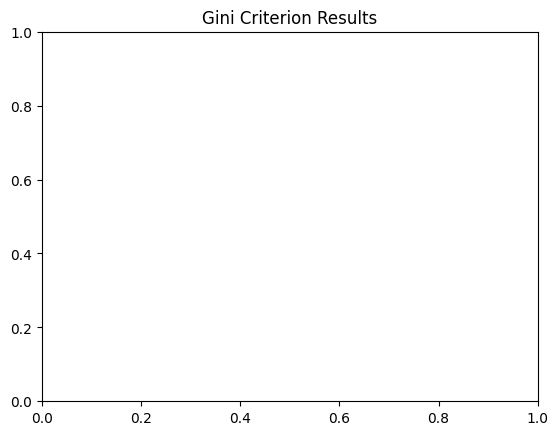

In [15]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples - Joe
table = pd.DataFrame({
    'Depth': depths,
    'Gini Train Accuracy': combine(giniTrainAccStats),
    'Gini Validation Accuracy': combine(giniValidationAccStats),
    'Gini Leaves': combine(giniLeaveStats),
    'Gini Actual Depth': combine(giniAcDepthStats),
    'Gini Times': combine(giniTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.tight_layout()
plt.show()
plt.title("Gini Criterion Results")

In [16]:
### part 1c pruning - Joe
import random

validationAccuracies = []
leafCounts = []
selectedAlphas = []
useAlphas = []

# compute the cost complexity path
for l in range(len(RANDOM_SEEDS)):
    tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l])
    path = tree.cost_complexity_pruning_path(xtrs[l], ytrs[l])
    selectedAlphas.extend(path.ccp_alphas)

# select say 20 values
# https://numpy.org/doc/stable/user/how-to-partition.html
indices = np.linspace(0, len(selectedAlphas) - 1, 20, dtype=int)
for i in indices:
    useAlphas.append(selectedAlphas[i])

# these will be the actual alpha values we use
useAlphas.sort()

# iterate through and calculate train and validationa accuracies
for l in range(len(RANDOM_SEEDS)):
    print(l)
    currValidationAccuracies = []
    currLeafCounts = []

    # try each alpha
    for i,alpha in enumerate(useAlphas):
        ccpTree = DecisionTreeClassifier(criterion='gini', ccp_alpha = alpha, random_state=RANDOM_SEEDS[l])
        ccpTree.fit(xtrs[l],ytrs[l])
        predict = ccpTree.predict(xvals[l])
        currValidationAccuracies.append(accuracy_score(predict, yvals[l]))
        currLeafCounts.append(ccpTree.get_n_leaves())
    validationAccuracies.append(currValidationAccuracies)
    leafCounts.append(currLeafCounts)

0
1
2
3
4


In [17]:
### part 1c - get mean and std estimate, mean_std isn't necessary here - Joe
validationAccuracyMeans = np.mean(validationAccuracies, axis=0)
validationAccuracyStds = np.std(validationAccuracies, axis=0)
leafCountMeans = np.mean(leafCounts, axis=0)
leafCountStds = np.std(leafCounts, axis=0)

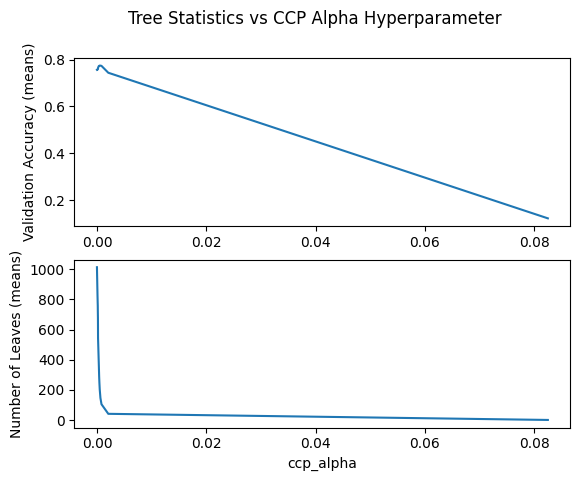

In [18]:
### p1c  - plot validation accuracy and leaft count vs alpha - Joe
fig, ax = plt.subplots(2, 1)

fig.suptitle("Tree Statistics vs CCP Alpha Hyperparameter")
ax[0].plot(useAlphas,validationAccuracyMeans)
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(useAlphas, leafCountMeans)
ax[1].set_xlabel('ccp_alpha')
ax[1].set_ylabel('Number of Leaves (means)')

plt.show()

In [19]:
### part 1c - get optimal alpha - Joe
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'ccp_alpha': useAlphas},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["ccp_alpha"]

print("Optimal Alpha: {:.4f}".format(best))
print("Best Pruning Validation Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal Alpha: 0.0006
Best Pruning Validation Accuracy 0.7672


In [20]:
### part 1c - compare with best depth - limited - Joe
tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[0], max_depth=20)
tree.fit(xtr,ytr)
print("Best Depth-Limited Tree Validation Accuracy : {:.4f}".format(tree.score(xval, yval)))

Best Depth-Limited Tree Validation Accuracy : 0.7548


In [21]:
### part 1c, trying min_samples_leaf - Joe
mslTrees = []
mslValidationAccuracies = []
mslLeafCounts = []
minSamplesLeaf = [1,5,20,50]

# iterate through and calculate validation accuracies and leaf counts
for l in range(len(RANDOM_SEEDS)):
    print(l)
    currValidationAccuracies = []
    currLeafCounts = []
    currMslTrees = []
    for msl in minSamplesLeaf:
        mslTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], min_samples_leaf=msl)
        mslTree.fit(xtrs[l], ytrs[l])

        validationPredictions = mslTree.predict(xvals[l])
        currValidationAccuracies.append(accuracy_score(yvals[l], validationPredictions))

        currLeafCounts.append(mslTree.get_n_leaves())
        currMslTrees.append(mslTree)
    mslValidationAccuracies.append(currValidationAccuracies)
    mslLeafCounts.append(currLeafCounts)
    mslTrees.append(currMslTrees)

0
1
2
3
4


In [22]:
### part 1c - min samples leaf statistics - Joe
mslValidationAccuracyStats = calcStats(mslValidationAccuracies, sweep=minSamplesLeaf)
mslLeafStats = calcStats(mslLeafCounts, sweep=minSamplesLeaf)

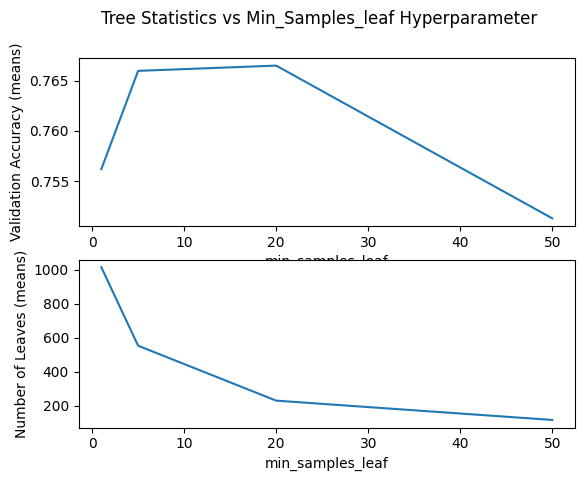

In [23]:
### P1c plot validation accuracy and leaft count vs min_samples_Leaf - Joe
fig, ax = plt.subplots(2, 1)
fig.suptitle("Tree Statistics vs Min_Samples_leaf Hyperparameter")
ax[0].plot(minSamplesLeaf,[i[0] for i in mslValidationAccuracyStats])
ax[0].set_xlabel('min_samples_leaf')
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(minSamplesLeaf, [i[0] for i in mslLeafStats])
ax[1].set_xlabel('min_samples_leaf')
ax[1].set_ylabel('Number of Leaves (means)')

plt.show()

In [24]:
### part 1c we can see the best one clearly, but use this anyway to grab score easier - Joe
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'min_samples_leaf': minSamplesLeaf},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["min_samples_leaf"]

print("Optimal min_samples_leaf: {:.4f}".format(best))
print("Best min_samples_leaf Validation Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal min_samples_leaf: 5.0000
Best min_samples_leaf Validation Accuracy 0.7636


In [25]:
### Part 1d regression - run models - Joe
# done in a similar way to 1b
# i know the variables should be called error/errors not accuracy, but it would take a while to rename all
rmseTrees = []

rmseTrainMSEAccuracies = []
rmseTrainRMSEAccuracies = []
rmseTrainMAEAccuracies = []

rmseValidationMSEAccuracies = []
rmseValidationRMSEAccuracies = []
rmseValidationMAEAccuracies = []

maeTrees = []

maeTrainMSEAccuracies = []
maeTrainRMSEAccuracies = []
maeTrainMAEAccuracies = []

maeValidationMSEAccuracies = []
maeValidationRMSEAccuracies = []
maeValidationMAEAccuracies = []

friedTrees = []

friedTrainMSEAccuracies = []
friedTrainRMSEAccuracies = []
friedTrainMAEAccuracies = []

friedValidationMSEAccuracies = []
friedValidationRMSEAccuracies = []
friedValidationMAEAccuracies = []

depths = [2,4,6,8,10]

for l in range(len(RANDOM_SEEDS)):
    print(l)
    currRmseTrees = []

    currRmseTrainMSEAccuracies = []
    currRmseTrainRMSEAccuracies = []
    currRmseTrainMAEAccuracies = []

    currRmseValidationMSEAccuracies = []
    currRmseValidationRMSEAccuracies = []
    currRmseValidationMAEAccuracies = []

    currMaeTrees = []

    currMaeTrainMSEAccuracies = []
    currMaeTrainRMSEAccuracies = []
    currMaeTrainMAEAccuracies = []

    currMaeValidationMSEAccuracies = []
    currMaeValidationRMSEAccuracies = []
    currMaeValidationMAEAccuracies = []

    currFriedTrees = []

    currFriedTrainMSEAccuracies = []
    currFriedTrainRMSEAccuracies = []
    currFriedTrainMAEAccuracies = []

    currFriedValidationMSEAccuracies = []
    currFriedValidationRMSEAccuracies = []
    currFriedValidationMAEAccuracies = []

    for depth in depths:
        print(depth)
        # create and fit tree
        rmseTree = DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        rmseTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        rmseTreePredictions = rmseTree.predict(regxtrs[l])
        rmseTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], rmseTreePredictions)

        # validation accuracy
        rmseTreePredictions = rmseTree.predict(regxvals[l])
        rmseTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], rmseTreePredictions)

        # update lists
        currRmseTrees.append(rmseTree)

        currRmseTrainMSEAccuracies.append(rmseTreeTrainMSEAccuracy)
        currRmseTrainRMSEAccuracies.append(rmseTreeTrainRMSEAccuracy)
        currRmseTrainMAEAccuracies.append(rmseTreeTrainMAEAccuracy)

        currRmseValidationMSEAccuracies.append(rmseTreeValidationMSEAccuracy)
        currRmseValidationRMSEAccuracies.append(rmseTreeValidationRMSEAccuracy)
        currRmseValidationMAEAccuracies.append(rmseTreeValidationMAEAccuracy)

    print("RMSE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        maeTree = DecisionTreeRegressor(criterion='absolute_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        maeTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        maeTreePredictions = maeTree.predict(regxtrs[l])
        maeTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], maeTreePredictions)

        # validation accuracy
        maeTreePredictions = maeTree.predict(regxvals[l])
        maeTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], maeTreePredictions)

        # update lists
        currMaeTrees.append(maeTree)

        currMaeTrainMSEAccuracies.append(maeTreeTrainMSEAccuracy)
        currMaeTrainRMSEAccuracies.append(maeTreeTrainRMSEAccuracy)
        currMaeTrainMAEAccuracies.append(maeTreeTrainMAEAccuracy)

        currMaeValidationMSEAccuracies.append(maeTreeValidationMSEAccuracy)
        currMaeValidationRMSEAccuracies.append(maeTreeValidationRMSEAccuracy)
        currMaeValidationMAEAccuracies.append(maeTreeValidationMAEAccuracy)

    print("MAE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        friedTree = DecisionTreeRegressor(criterion='friedman_mse', random_state=RANDOM_SEEDS[l], max_depth=depth)
        friedTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        friedTreePredictions = friedTree.predict(regxtrs[l])
        friedTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], friedTreePredictions)

        # validation accuracy
        friedTreePredictions = friedTree.predict(regxvals[l])
        friedTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], friedTreePredictions)

        # update lists
        currFriedTrees.append(friedTree)

        currFriedTrainMSEAccuracies.append(friedTreeTrainMSEAccuracy)
        currFriedTrainRMSEAccuracies.append(friedTreeTrainRMSEAccuracy)
        currFriedTrainMAEAccuracies.append(friedTreeTrainMAEAccuracy)

        currFriedValidationMSEAccuracies.append(friedTreeValidationMSEAccuracy)
        currFriedValidationRMSEAccuracies.append(friedTreeValidationRMSEAccuracy)
        currFriedValidationMAEAccuracies.append(friedTreeValidationMAEAccuracy)

    print("Fried Done")

    rmseTrees.append(currRmseTrees)

    rmseTrainMSEAccuracies.append(currRmseTrainMSEAccuracies)
    rmseTrainRMSEAccuracies.append(currRmseTrainRMSEAccuracies)
    rmseTrainMAEAccuracies.append(currRmseTrainMAEAccuracies)

    rmseValidationMSEAccuracies.append(currRmseValidationMSEAccuracies)
    rmseValidationRMSEAccuracies.append(currRmseValidationRMSEAccuracies)
    rmseValidationMAEAccuracies.append(currRmseValidationMAEAccuracies)

    maeTrees.append(currMaeTrees)

    maeTrainMSEAccuracies.append(currMaeTrainMSEAccuracies)
    maeTrainRMSEAccuracies.append(currMaeTrainRMSEAccuracies)
    maeTrainMAEAccuracies.append(currMaeTrainMAEAccuracies)

    maeValidationMSEAccuracies.append(currMaeValidationMSEAccuracies)
    maeValidationRMSEAccuracies.append(currMaeValidationRMSEAccuracies)
    maeValidationMAEAccuracies.append(currMaeValidationMAEAccuracies)

    friedTrees.append(currFriedTrees)

    friedTrainMSEAccuracies.append(currFriedTrainMSEAccuracies)
    friedTrainRMSEAccuracies.append(currFriedTrainRMSEAccuracies)
    friedTrainMAEAccuracies.append(currFriedTrainMAEAccuracies)

    friedValidationMSEAccuracies.append(currFriedValidationMSEAccuracies)
    friedValidationRMSEAccuracies.append(currFriedValidationRMSEAccuracies)
    friedValidationMAEAccuracies.append(currFriedValidationMAEAccuracies)

0
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
1
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
2
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
3
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
4
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done


In [26]:
### part 1d - calc stats similarly again - Joe
rmseTrainMSEAccuracyStats = calcStats(rmseTrainMSEAccuracies, sweep=depths)
rmseTrainRMSEAccuracyStats = calcStats(rmseTrainRMSEAccuracies, sweep=depths)
rmseTrainMAEAccuracyStats = calcStats(rmseTrainMAEAccuracies, sweep=depths)

rmseValidationMSEAccuracyStats = calcStats(rmseValidationMSEAccuracies, sweep=depths)
rmseValidationRMSEAccuracyStats = calcStats(rmseValidationRMSEAccuracies, sweep=depths)
rmseValidationMAEAccuracyStats = calcStats(rmseValidationMAEAccuracies, sweep=depths)

maeTrainMSEAccuracyStats = calcStats(maeTrainMSEAccuracies, sweep=depths)
maeTrainRMSEAccuracyStats = calcStats(maeTrainRMSEAccuracies, sweep=depths)
maeTrainMAEAccuracyStats = calcStats(maeTrainMAEAccuracies, sweep=depths)

maeValidationMSEAccuracyStats = calcStats(maeValidationMSEAccuracies, sweep=depths)
maeValidationRMSEAccuracyStats = calcStats(maeValidationRMSEAccuracies, sweep=depths)
maeValidationMAEAccuracyStats = calcStats(maeValidationMAEAccuracies, sweep=depths)

friedTrainMSEAccuracyStats = calcStats(friedTrainMSEAccuracies, sweep=depths)
friedTrainRMSEAccuracyStats = calcStats(friedTrainRMSEAccuracies, sweep=depths)
friedTrainMAEAccuracyStats = calcStats(friedTrainMAEAccuracies, sweep=depths)

friedValidationMSEAccuracyStats = calcStats(friedValidationMSEAccuracies, sweep=depths)
friedValidationRMSEAccuracyStats = calcStats(friedValidationRMSEAccuracies, sweep=depths)
friedValidationMAEAccuracyStats = calcStats(friedValidationMAEAccuracies, sweep=depths)

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\582287936.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


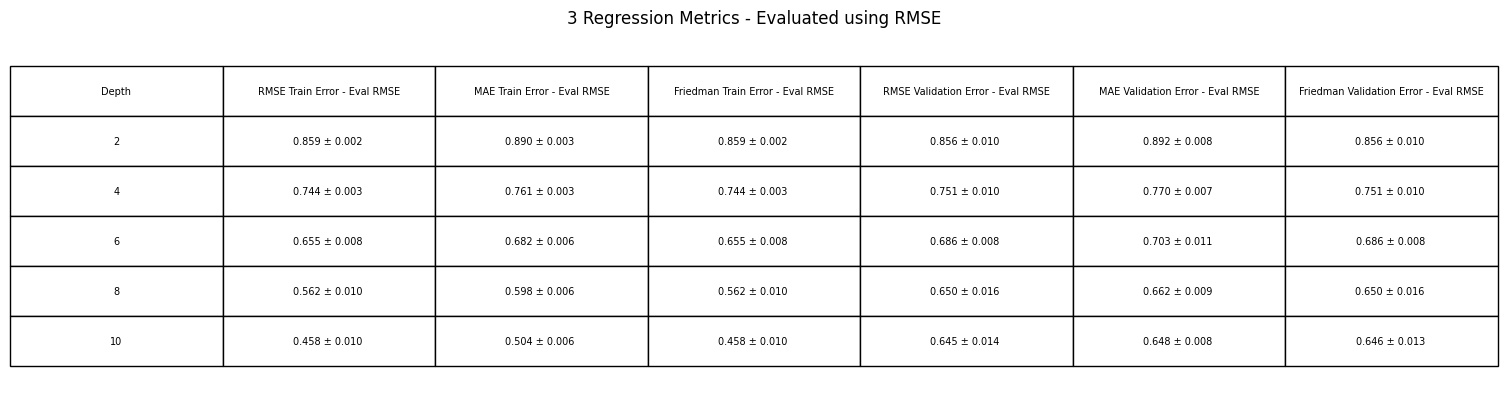

In [27]:
### part 1d  - plot rmse eval - Joe
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval RMSE' : combine(rmseTrainRMSEAccuracyStats),
    'MAE Train Error - Eval RMSE': combine(maeTrainRMSEAccuracyStats),
    'Friedman Train Error - Eval RMSE' : combine(friedTrainRMSEAccuracyStats),
    'RMSE Validation Error - Eval RMSE' : combine(rmseValidationRMSEAccuracyStats),
    'MAE Validation Error - Eval RMSE': combine(maeValidationRMSEAccuracyStats),
    'Friedman Validation Error - Eval RMSE' : combine(friedValidationRMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using RMSE")
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\1436798108.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


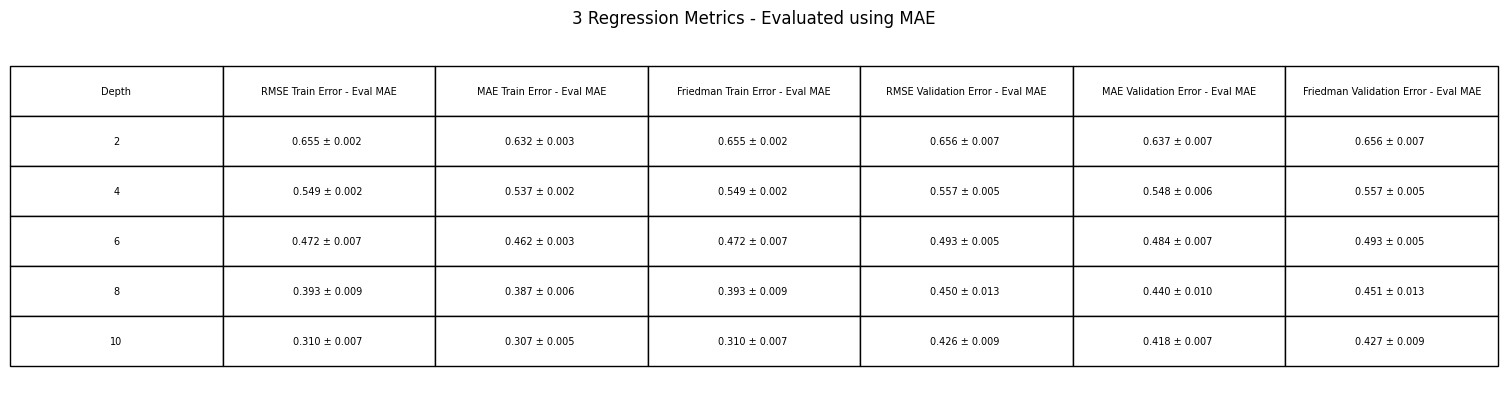

In [28]:
### part 1d - plot mae eval - Joe
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MAE' : combine(rmseTrainMAEAccuracyStats),
    'MAE Train Error - Eval MAE': combine(maeTrainMAEAccuracyStats),
    'Friedman Train Error - Eval MAE' : combine(friedTrainMAEAccuracyStats),
    'RMSE Validation Error - Eval MAE' : combine(rmseValidationMAEAccuracyStats),
    'MAE Validation Error - Eval MAE': combine(maeValidationMAEAccuracyStats),
    'Friedman Validation Error - Eval MAE' : combine(friedValidationMAEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using MAE")
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2321731204.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


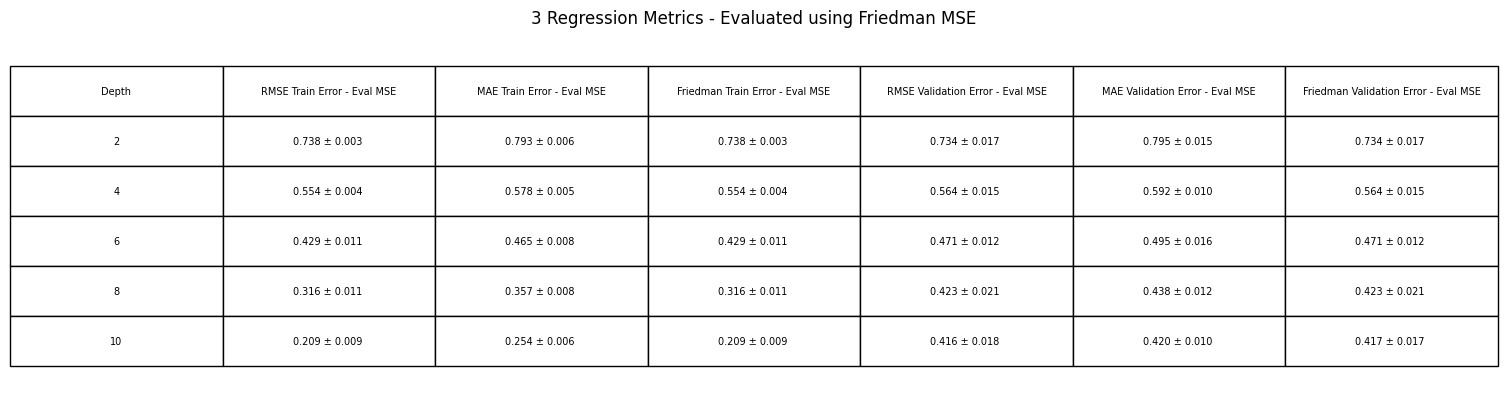

In [29]:
### part 1d - plot fried eval - Joe
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MSE' : combine(rmseTrainMSEAccuracyStats),
    'MAE Train Error - Eval MSE': combine(maeTrainMSEAccuracyStats),
    'Friedman Train Error - Eval MSE' : combine(friedTrainMSEAccuracyStats),
    'RMSE Validation Error - Eval MSE' : combine(rmseValidationMSEAccuracyStats),
    'MAE Validation Error - Eval MSE': combine(maeValidationMSEAccuracyStats),
    'Friedman Validation Error - Eval MSE' : combine(friedValidationMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using Friedman MSE")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, '3 Regression metrics - Evaluated using RMSE')

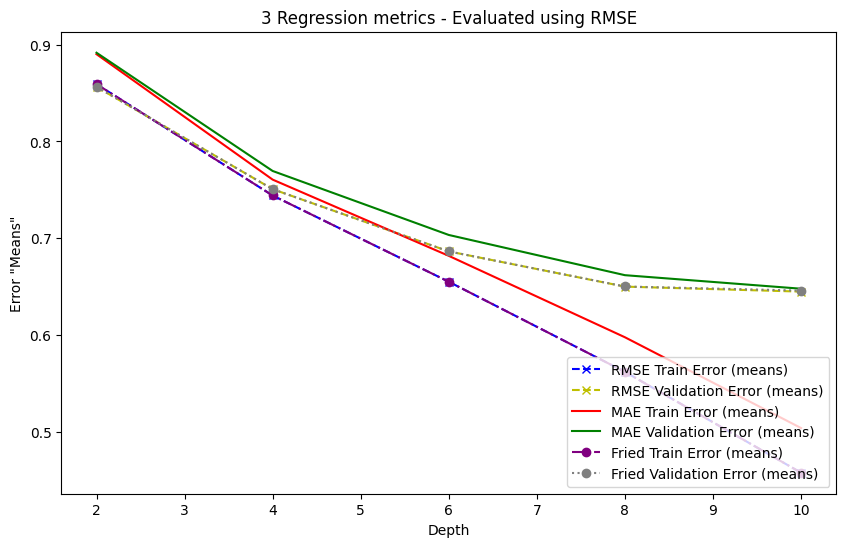

In [30]:
### part 1d - visualize it all on RMSE - Joe
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainRMSEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationRMSEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainRMSEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationRMSEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainRMSEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationRMSEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using RMSE")

Text(0.5, 1.0, '3 Regression metrics - Evaluated using MAE')

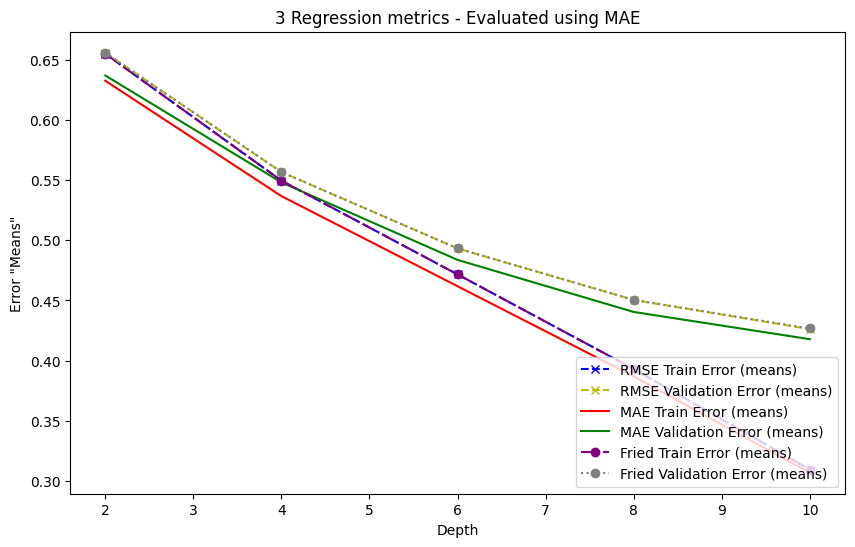

In [31]:
### part 1d - visualize it all on MAE - Joe
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainMAEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationMAEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainMAEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationMAEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainMAEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationMAEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using MAE")

In [32]:
### part 1d get best tree - Joe
bestTree = None
bestRMSE = float('inf')
seed = None

for trees in [rmseTrees, maeTrees, friedTrees]:
    for l in range(len(RANDOM_SEEDS)):
        for tree in trees[l]:
            preds = tree.predict(regxvals[l])
            score = root_mean_squared_error(regyvals[l], preds)

            if score <bestRMSE:
                bestRMSE = score
                bestTree = tree
                seed = l

print("Best Validation RMSE: {:.3f}".format(bestRMSE))

Best Validation RMSE: 0.624


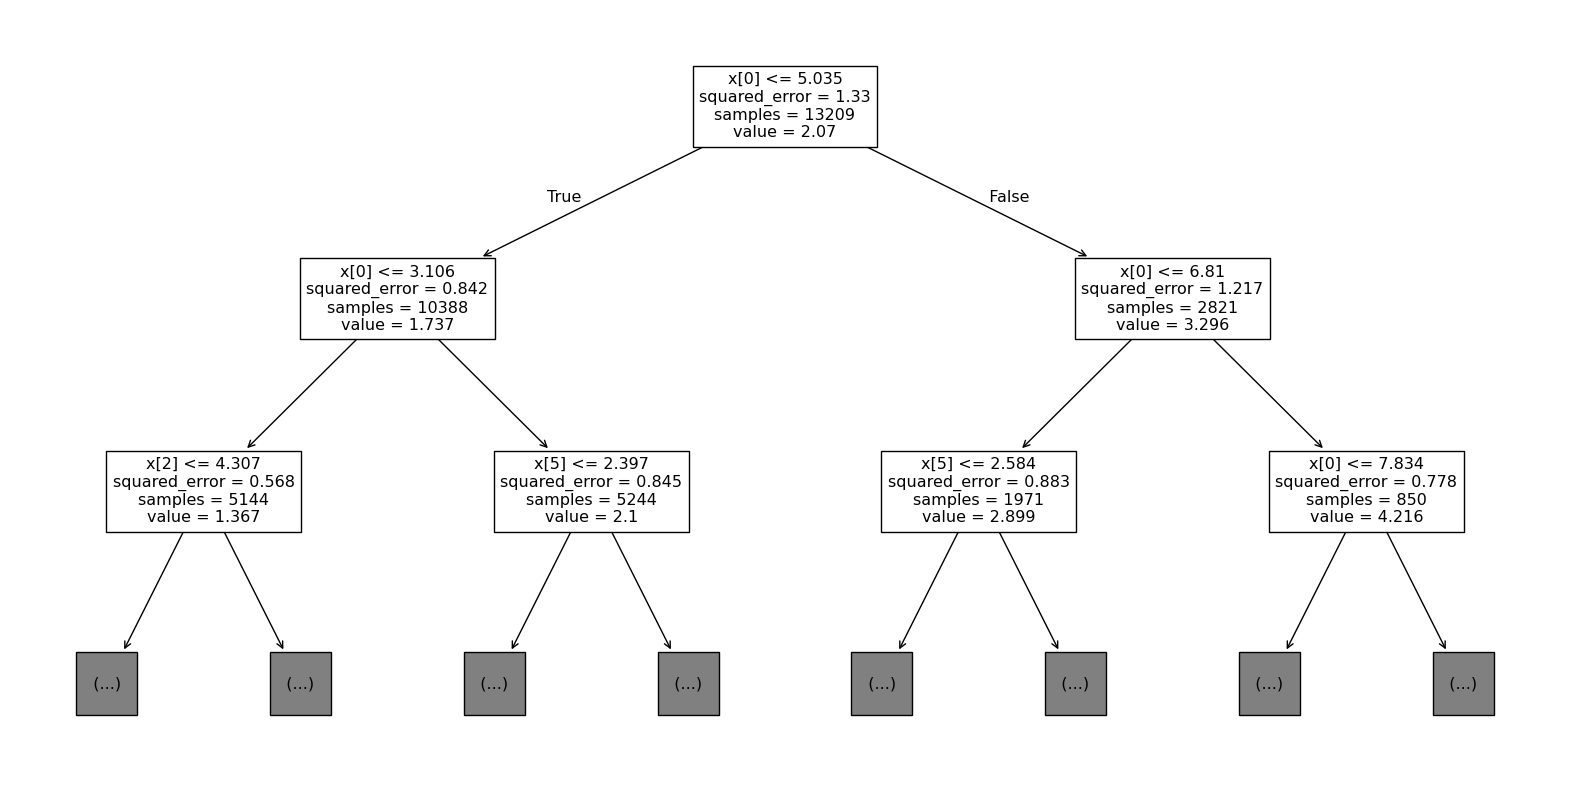

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [33]:
### part 1d look at the top three levels of the best tree - Joe
plt.figure(figsize=(20,10))

plot_tree(
    bestTree, 
    max_depth=2,
)
plt.show()

print(fetch_california_housing().feature_names)

Text(0.5, 1.0, 'Prediced Price vs Median Income - Showing Piecewise')

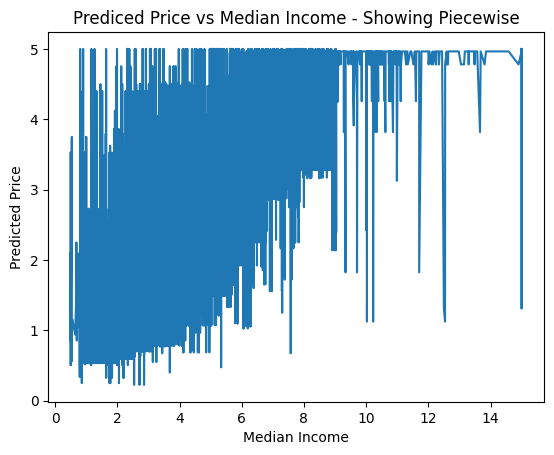

In [34]:
### part 1d visualize step function prediction - Joe
MedInc = regX[:,0]

# best tree preds
preds = bestTree.predict(regX)

# sort feature
indx = np.argsort(MedInc)

# plot
plt.figure()
plt.plot(MedInc[indx], preds[indx])
plt.xlabel("Median Income")
plt.ylabel("Predicted Price")
plt.title("Prediced Price vs Median Income - Showing Piecewise")


### PART 2 - JOE

In [ ]:
### PART 2 - run models Joe

pastingModelSizes = []

baggingModelSizes = []
ranSubModelSizes = []
ranPatchModelSizes = []

pastingTrTimes = []
baggingTrTimes = []
ranSubTrTimes = []
ranPatchTrTimes = []

pastingPrTimes = []
baggingPrTimes = []
ranSubPrTimes = []
ranPatchPrTimes = []

pastingValidationAccuracies = []
baggingValidationAccuracies = []
ranSubValidationAccuracies = []
ranPatchValidationAccuracies = []

pastingTrainAccuracies = []
baggingTrainAccuracies = []
ranSubTrainAccuracies = []
ranPatchTrainAccuracies = []

n = 15000 #total number of predictions per train and val test set

sweepRows = [0.1,0.3,0.5,0.7,1.0]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currPastingModelSizes = []
    currBaggingModelSizes = []
    currRanSubModelSizes = []
    currRanPatchModelSizes = []

    currPastingTrTimes = []
    currBaggingTrTimes = []
    currRanSubTrTimes = []
    currRanPatchTrTimes = []

    currPastingPrTimes = []
    currBaggingPrTimes = []
    currRanSubPrTimes = []
    currRanPatchPrTimes = []

    currPastingValidationAccuracies = []
    currBaggingValidationAccuracies = []
    currRanSubValidationAccuracies = []
    currRanPatchValidationAccuracies = []

    currPastingTrainAccuracies = []
    currBaggingTrainAccuracies = []
    currRanSubTrainAccuracies = []
    currRanPatchTrainAccuracies = []

    #pasting
    for frac in sweepRows:
        stTr = time.time()
        
        pasting = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        pasting.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = pasting.predict(xtrs[l])
        currPastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = pasting.predict(xvals[l])
        currPastingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currPastingTrTimes.append(endTr-stTr)
        currPastingPrTimes.append((endPr-stPr)*1000*1000/n)
        currPastingModelSizes.append(sum(tree.tree_.node_count for tree in pasting.estimators_))

    #bagging
    for frac in sweepRows:
        stTr = time.time()    
        
        bagging = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=True,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        bagging.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = bagging.predict(xtrs[l])
        currBaggingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = bagging.predict(xvals[l])
        currBaggingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currBaggingTrTimes.append(endTr-stTr)
        currBaggingPrTimes.append((endPr-stPr)*1000*1000/n)
        currBaggingModelSizes.append(sum(tree.tree_.node_count for tree in bagging.estimators_))

    #random subspaces
    for frac in sweepRows:
        stTr = time.time()
        
        ranSub = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=1.0,
            max_features=frac,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        ranSub.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = ranSub.predict(xtrs[l])
        currRanSubTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = ranSub.predict(xvals[l])
        currRanSubValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currRanSubTrTimes.append(endTr-stTr)
        currRanSubPrTimes.append((endPr-stPr)*1000*1000/n)
        currRanSubModelSizes.append(sum(tree.tree_.node_count for tree in ranSub.estimators_))

    #random patches
    for colfrac in sweepRows:
        currColTrainAccuracies = []
        currColValidationAccuracies = []
        currColTrTimes = []
        currColPrTimes = []
        currColModelSizes = []

        for rowfrac in sweepRows:
            stTr = time.time()

            ranPatch = BaggingClassifier(
                estimator=DecisionTreeClassifier(),
                n_estimators=100,
                max_samples=rowfrac,
                max_features=colfrac,
                bootstrap=False,
                bootstrap_features=False,
                random_state=RANDOM_SEEDS[l],
                n_jobs=-1
            )

            ranPatch.fit(xtrs[l], ytrs[l])
            endTr = time.time()

            stPr = time.time()
            preds = ranPatch.predict(xtrs[l])
            currColTrainAccuracies.append(accuracy_score(ytrs[l], preds))

            preds = ranPatch.predict(xvals[l])
            currColValidationAccuracies.append(accuracy_score(yvals[l], preds))
            endPr = time.time()

            currColTrTimes.append(endTr - stTr)
            currColPrTimes.append((endPr-stPr)*1000*1000/n)
            currColModelSizes.append(sum(tree.tree_.node_count for tree in ranPatch.estimators_))

        currRanPatchTrainAccuracies.append(currColTrainAccuracies)
        currRanPatchValidationAccuracies.append(currColValidationAccuracies)
        currRanPatchTrTimes.append(currColTrTimes)
        currRanPatchPrTimes.append(currColPrTimes)
        currRanPatchModelSizes.append(currColModelSizes)

    pastingModelSizes.append(currPastingModelSizes)
    baggingModelSizes.append(currBaggingModelSizes)
    ranSubModelSizes.append(currRanSubModelSizes)
    ranPatchModelSizes.append(currRanPatchModelSizes)

    pastingTrTimes.append(currPastingTrTimes)
    baggingTrTimes.append(currBaggingTrTimes)
    ranSubTrTimes.append(currRanSubTrTimes)
    ranPatchTrTimes.append(currRanPatchTrTimes)

    pastingPrTimes.append(currPastingPrTimes)
    baggingPrTimes.append(currBaggingPrTimes)
    ranSubPrTimes.append(currRanSubPrTimes)
    ranPatchPrTimes.append(currRanPatchPrTimes)

    pastingValidationAccuracies.append(currPastingValidationAccuracies)
    baggingValidationAccuracies.append(currBaggingValidationAccuracies)
    ranSubValidationAccuracies.append(currRanSubValidationAccuracies)
    ranPatchValidationAccuracies.append(currRanPatchValidationAccuracies)

    pastingTrainAccuracies.append(currPastingTrainAccuracies)
    baggingTrainAccuracies.append(currBaggingTrainAccuracies)
    ranSubTrainAccuracies.append(currRanSubTrainAccuracies)
    ranPatchTrainAccuracies.append(currRanPatchTrainAccuracies)
    

0
1
2
3
4


In [36]:
### part 2 helper - calculate the random patch stats - Joe
def calcRanPatchStats(vals):
    vals = np.array(vals)
    #[seeds][columns][rows]
    # average across columns w.r.t row fraction
    rowAverages = np.mean(vals, axis=1)
    rowStats = calcStats(rowAverages, sweep=None)

    # average across rows w.r.t column fraction
    colAverages = np.mean(vals, axis=2)
    colStats = calcStats(colAverages, sweep=None)

    return rowStats, colStats

In [37]:
### part 2a - calc stats - Joe
pastingModelSizeStats = calcStats(pastingModelSizes, sweep=sweepRows)
baggingModelSizeStats = calcStats(baggingModelSizes, sweep=sweepRows)
ranSubModelSizeStats = calcStats(ranSubModelSizes, sweep=sweepRows)
ranPatchModelSizeRowStats, ranPatchModelSizeColStats = calcRanPatchStats(ranPatchModelSizes)

pastingTrTimeStats = calcStats(pastingTrTimes, sweep=sweepRows)
baggingTrTimeStats = calcStats(baggingTrTimes, sweep=sweepRows)
ranSubTrTimeStats = calcStats(ranSubTrTimes, sweep=sweepRows)
ranPatchTrTimeRowStats, ranPatchTrTimeColStats = calcRanPatchStats(ranPatchTrTimes)

pastingPrTimeStats = calcStats(pastingPrTimes, sweep=sweepRows)
baggingPrTimeStats = calcStats(baggingPrTimes, sweep=sweepRows)
ranSubPrTimeStats = calcStats(ranSubPrTimes, sweep=sweepRows)
ranPatchPrTimeRowStats, ranPatchPrTimeColStats = calcRanPatchStats(ranPatchPrTimes)

pastingValidationAccuracyStats = calcStats(pastingValidationAccuracies, sweep=sweepRows)
baggingValidationAccuracyStats = calcStats(baggingValidationAccuracies, sweep=sweepRows)
ranSubValidationAccuracyStats = calcStats(ranSubValidationAccuracies, sweep=sweepRows)
ranPatchValidationAccuracyRowStats, ranPatchValidationAccuracyColStats = calcRanPatchStats(ranPatchValidationAccuracies)

pastingTrainAccuracyStats = calcStats(pastingTrainAccuracies, sweep=sweepRows)
baggingTrainAccuracyStats = calcStats(baggingTrainAccuracies, sweep=sweepRows)
ranSubTrainAccuracyStats = calcStats(ranSubTrainAccuracies, sweep=sweepRows)
ranPatchTrainAccuracyRowStats, ranPatchTrainAccuracyColStats = calcRanPatchStats(ranPatchTrainAccuracies)

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2597463892.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


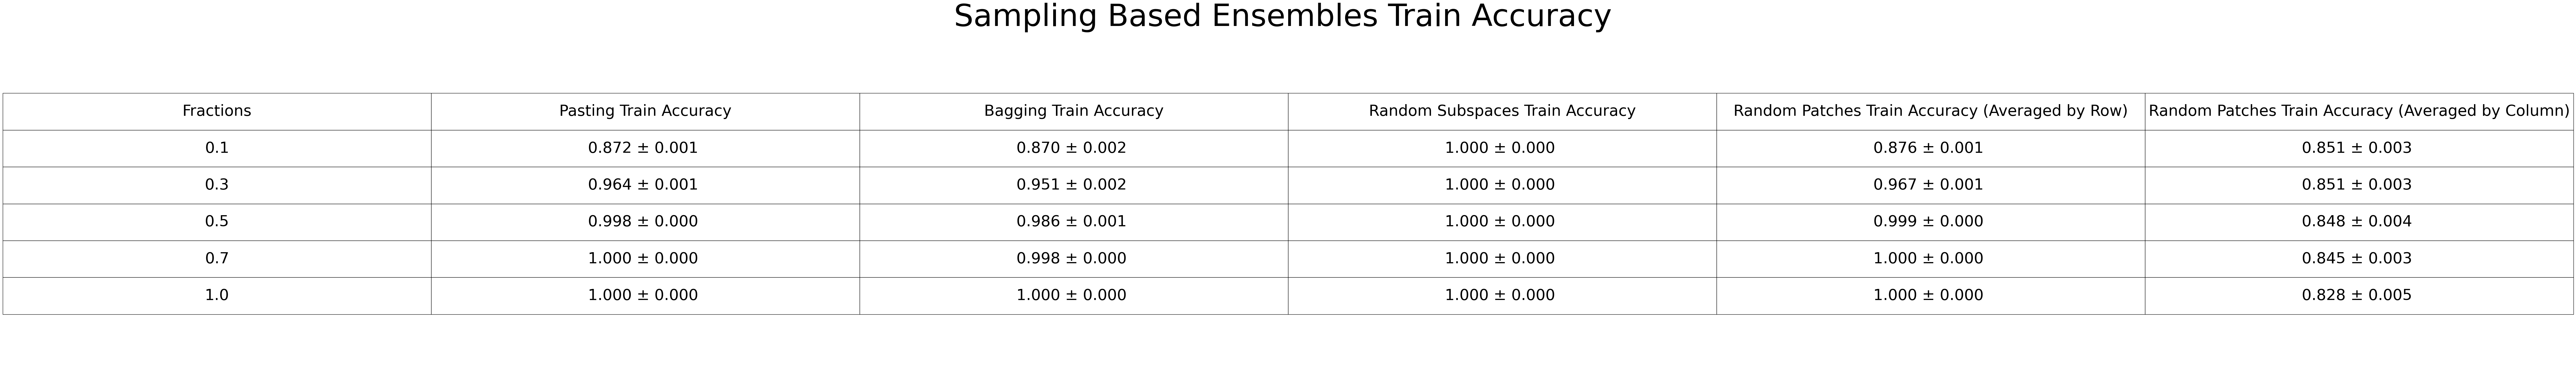

In [38]:
### part2a - show stats as table - Joe
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Train Accuracy' : combine(pastingTrainAccuracyStats),
    'Bagging Train Accuracy': combine(baggingTrainAccuracyStats),
    'Random Subspaces Train Accuracy': combine(ranSubTrainAccuracyStats),
    'Random Patches Train Accuracy (Averaged by Row)': combine(ranPatchTrainAccuracyRowStats),
    'Random Patches Train Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(15,15))
fig.suptitle("Sampling Based Ensembles Train Accuracy", fontsize=80)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(40)
axtable.scale(8,8)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2585835728.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


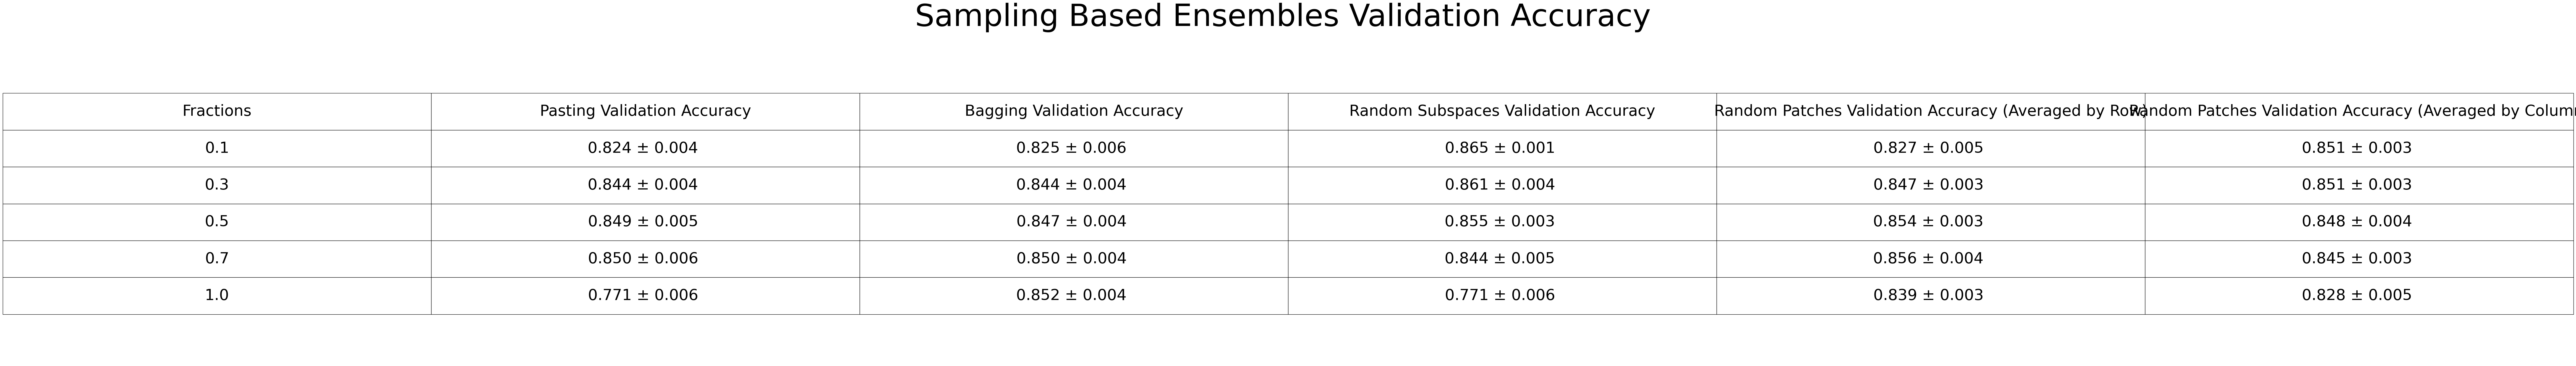

In [39]:
### part2a - show stats as table - Joe
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Validation Accuracy' : combine(pastingValidationAccuracyStats),
    'Bagging Validation Accuracy': combine(baggingValidationAccuracyStats),
    'Random Subspaces Validation Accuracy': combine(ranSubValidationAccuracyStats),
    'Random Patches Validation Accuracy (Averaged by Row)': combine(ranPatchValidationAccuracyRowStats),
    'Random Patches Validation Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(15,15))
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(40)
axtable.scale(8,8)
axtable.set
fig.suptitle("Sampling Based Ensembles Validation Accuracy", fontsize=80)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Random Patches')

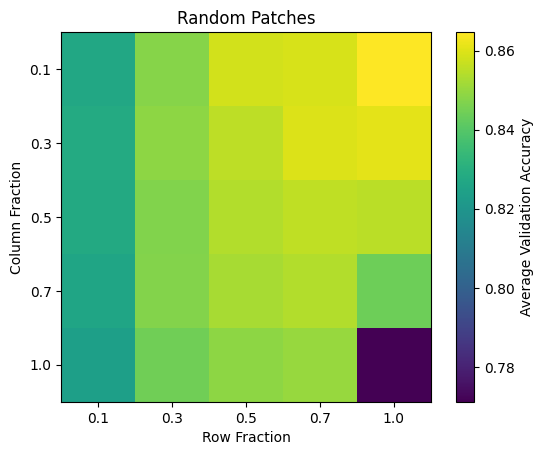

In [40]:
### part2a - show heatmap - Joe
hm = np.mean(ranPatchValidationAccuracies, axis = 0)

fig,ax = plt.subplots()
im = ax.imshow(hm, cmap="viridis")
fig.colorbar(im,ax=ax, label="Average Validation Accuracy")
ax.set_xticks(range(len(sweepRows)))
ax.set_yticks(range(len(sweepRows)))
ax.set_xticklabels(sweepRows)
ax.set_yticklabels(sweepRows)
ax.set_xlabel("Row Fraction")
ax.set_ylabel("Column Fraction")
ax.set_title("Random Patches")

In [41]:
### part 2b plot validation accuracy vs number of trees for bagging - Joe
#bagging
treeNums = [1,25,50,100,200,300]
baggingValidationAccuracies = []
oobStats = []
for tn in treeNums: 
    print(tn)       
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=tn,
        max_samples=0.5,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0],
        n_jobs=-1, # to compute faster
        oob_score=True
    )
    bagging.fit(xtrs[0], ytrs[0])
    preds = bagging.predict(xvals[0])
    baggingValidationAccuracies.append(accuracy_score(yvals[0], preds))
    oobStats.append(bagging.oob_score_)

1


C:\Users\jafer\AppData\Roaming\Python\Python313\site-packages\sklearn\ensemble\_bagging.py:917: UserWarning: Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.
  warn(
C:\Users\jafer\AppData\Roaming\Python\Python313\site-packages\sklearn\ensemble\_bagging.py:923: RuntimeWarning: invalid value encountered in divide
  oob_decision_function = predictions / predictions.sum(axis=1)[:, np.newaxis]


25
50
100
200
300


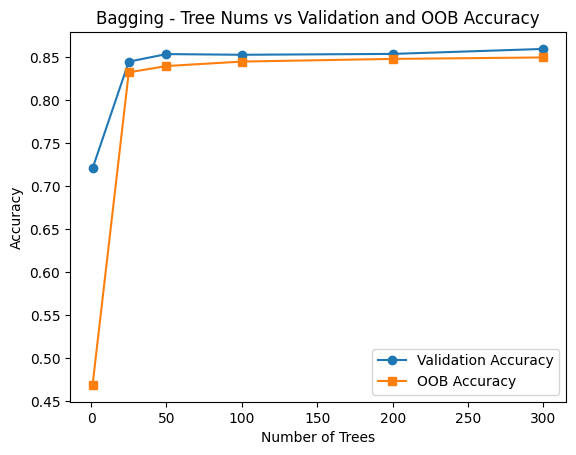

In [42]:
### part 2b - plot - Joe
fig,ax = plt.subplots()
ax.plot(treeNums, baggingValidationAccuracies, marker='o', label='Validation Accuracy')
ax.plot(treeNums, oobStats, marker='s', label="OOB Accuracy")
ax.set_xlabel("Number of Trees")
ax.set_ylabel("Accuracy")
ax.set_title("Bagging - Tree Nums vs Validation and OOB Accuracy")
plt.legend()
plt.show()

In [43]:
### part 2c - get resamples boostrap - Joe
preds = {
    "pasting": [],
    "bagging": [],
    "ransub": [],
    "ranpatch": [],
    "unpruned": [],
    "depth4": []
}
for i in range(10):
    # get different bootstrap resamples each time
    xboot,yboot = resample(xtrs[0], ytrs[0], replace=True, random_state=RANDOM_SEEDS[0]+i)

    pasting = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50, #for faster computation, results diminish past this
        max_samples=0.5,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    pasting.fit(xboot,yboot)
    preds["pasting"].append(pasting.predict(xvals[0]))

    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=0.5,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    bagging.fit(xboot,yboot)
    preds["bagging"].append(bagging.predict(xvals[0]))

    ranSub = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=1.0,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    ranSub.fit(xboot,yboot)
    preds["ransub"].append(ranSub.predict(xvals[0]))

    ranPatch = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=0.5,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1
    )
    ranPatch.fit(xboot,yboot)
    preds["ranpatch"].append(ranPatch.predict(xvals[0]))

    unpruned = DecisionTreeClassifier(
        random_state=RANDOM_SEEDS[0]+i
    )
    unpruned.fit(xboot, yboot)
    preds["unpruned"].append(unpruned.predict(xvals[0]))

    depth4 = DecisionTreeClassifier(
        max_depth=4,
        random_state=RANDOM_SEEDS[0]+i
    )
    depth4.fit(xboot, yboot)
    preds["depth4"].append(depth4.predict(xvals[0]))


In [44]:
### part 2c compute disagreement rate - Joe
disagrees = []
errs = []

# iterate through each model
for model in preds.keys():
    predictions = np.array(preds[model])

    # compute majority
    majority = []
    for j in range(predictions.shape[1]):
        # return lists of the unique labels and their counts
        labels, counts = np.unique(predictions[:, j], return_counts=True)
        # the majority is the argmax
        majority.append(labels[np.argmax(counts)])

    majority = np.array(majority)

    # average the predictions that are not the majority
    disagree = np.mean(predictions != majority)

    # compare against true labels
    trueLabels = np.asarray(yvals[0])
    err = np.mean(majority != trueLabels)

    disagrees.append(disagree)
    errs.append(err)

    print("{}: Disagreement={:.4f}, Error={:.4f}".format(
        model, disagree, err
    ))

pasting: Disagreement=0.0647, Error=0.1462
bagging: Disagreement=0.0596, Error=0.1444
ransub: Disagreement=0.0616, Error=0.1384
ranpatch: Disagreement=0.0547, Error=0.1406
unpruned: Disagreement=0.1988, Error=0.1606
depth4: Disagreement=0.0811, Error=0.3260


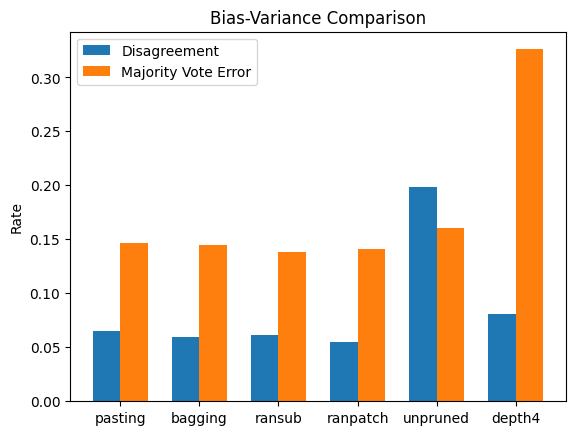

In [45]:
### part 2c plot the comparison - Joe
# https://www.geeksforgeeks.org/python/plotting-multiple-bar-charts-using-matplotlib-in-python/
fig, ax = plt.subplots()
x = np.arange(len(preds))
width = 0.35

ax.bar(x - width/2, disagrees, width, label="Disagreement")
ax.bar(x + width/2, errs, width, label="Majority Vote Error")

ax.set_xticks(x)
ax.set_xticklabels(list(preds.keys()))
ax.set_ylabel("Rate")
ax.set_title("Bias-Variance Comparison")
ax.legend()

plt.show()

In [46]:
### part 2d - run models - Joe
pastingValidationAccuracies = []
baggingValidationAccuracies = []
ranSubValidationAccuracies = []
ranPatchValidationAccuracies = []

pastingTrainAccuracies = []
baggingTrainAccuracies = []
ranSubTrainAccuracies = []
ranPatchTrainAccuracies = []

sweepRows = [0.1,0.3,0.5,0.7,1.0]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currPastingValidationAccuracies = []
    currBaggingValidationAccuracies = []
    currRanSubValidationAccuracies = []
    currRanPatchValidationAccuracies = []

    currPastingTrainAccuracies = []
    currBaggingTrainAccuracies = []
    currRanSubTrainAccuracies = []
    currRanPatchTrainAccuracies = []

    #pasting
    for frac in sweepRows:
        pasting = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        pasting.fit(xtrs[l], ytrs[l])

        preds = pasting.predict(xtrs[l])
        currPastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = pasting.predict(xvals[l])
        currPastingValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #bagging
    for frac in sweepRows:
        bagging = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=True,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        bagging.fit(xtrs[l], ytrs[l])

        preds = bagging.predict(xtrs[l])
        currBaggingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = bagging.predict(xvals[l])
        currBaggingValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #random subspaces
    for frac in sweepRows:
        ranSub = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=1.0,
            max_features=frac,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        ranSub.fit(xtrs[l], ytrs[l])
       
        preds = ranSub.predict(xtrs[l])
        currRanSubTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = ranSub.predict(xvals[l])
        currRanSubValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #random patches
    for colfrac in sweepRows:
        currColTrainAccuracies = []
        currColValidationAccuracies = []

        for rowfrac in sweepRows:
            ranPatch = BaggingClassifier(
                estimator=DecisionTreeClassifier(max_depth=4),
                n_estimators=100,
                max_samples=rowfrac,
                max_features=colfrac,
                bootstrap=False,
                bootstrap_features=False,
                random_state=RANDOM_SEEDS[l],
                n_jobs=-1
            )

            ranPatch.fit(xtrs[l], ytrs[l])

            preds = ranPatch.predict(xtrs[l])
            currColTrainAccuracies.append(accuracy_score(ytrs[l], preds))

            preds = ranPatch.predict(xvals[l])
            currColValidationAccuracies.append(accuracy_score(yvals[l], preds))

        currRanPatchTrainAccuracies.append(currColTrainAccuracies)
        currRanPatchValidationAccuracies.append(currColValidationAccuracies)

    pastingValidationAccuracies.append(currPastingValidationAccuracies)
    baggingValidationAccuracies.append(currBaggingValidationAccuracies)
    ranSubValidationAccuracies.append(currRanSubValidationAccuracies)
    ranPatchValidationAccuracies.append(currRanPatchValidationAccuracies)

    pastingTrainAccuracies.append(currPastingTrainAccuracies)
    baggingTrainAccuracies.append(currBaggingTrainAccuracies)
    ranSubTrainAccuracies.append(currRanSubTrainAccuracies)
    ranPatchTrainAccuracies.append(currRanPatchTrainAccuracies)
    

0
1
2
3
4


In [47]:
### part 2d - a - calc stats - Joe
pastingValidationAccuracyStats = calcStats(pastingValidationAccuracies, sweep=sweepRows)
baggingValidationAccuracyStats = calcStats(baggingValidationAccuracies, sweep=sweepRows)
ranSubValidationAccuracyStats = calcStats(ranSubValidationAccuracies, sweep=sweepRows)
ranPatchValidationAccuracyRowStats, ranPatchValidationAccuracyColStats = calcRanPatchStats(ranPatchValidationAccuracies)

pastingTrainAccuracyStats = calcStats(pastingTrainAccuracies, sweep=sweepRows)
baggingTrainAccuracyStats = calcStats(baggingTrainAccuracies, sweep=sweepRows)
ranSubTrainAccuracyStats = calcStats(ranSubTrainAccuracies, sweep=sweepRows)
ranPatchTrainAccuracyRowStats, ranPatchTrainAccuracyColStats = calcRanPatchStats(ranPatchTrainAccuracies)

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\3685541307.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [48]:
### part2d - show stats as table - Joe
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Train Accuracy' : combine(pastingTrainAccuracyStats),
    'Bagging Train Accuracy': combine(baggingTrainAccuracyStats),
    'Random Subspaces Train Accuracy': combine(ranSubTrainAccuracyStats),
    'Random Patches Train Accuracy (Averaged by Row)': combine(ranPatchTrainAccuracyRowStats),
    'Random Patches Train Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Sampling Based Ensembles Training Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2104979877.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [49]:
### part2d - show stats as table - Joe
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Validation Accuracy' : combine(pastingValidationAccuracyStats),
    'Bagging Validation Accuracy': combine(baggingValidationAccuracyStats),
    'Random Subspaces Validation Accuracy': combine(ranSubValidationAccuracyStats),
    'Random Patches Validation Accuracy (Averaged by Row)': combine(ranPatchValidationAccuracyRowStats),
    'Random Patches Validation Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Sampling Based Ensembles Training Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Random Patches')

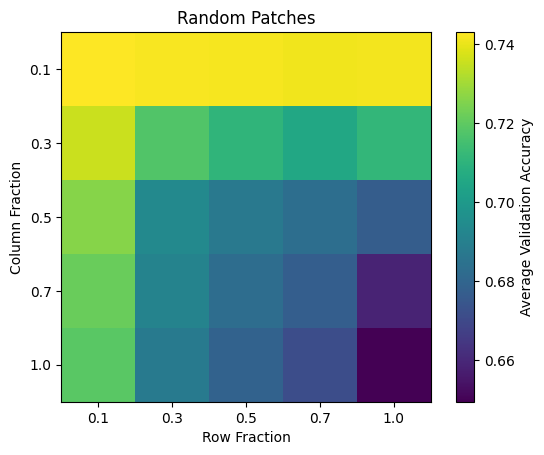

In [50]:
### part2d - show heatmap - Joe
hm = np.mean(ranPatchValidationAccuracies, axis = 0)

fig,ax = plt.subplots()
im = ax.imshow(hm, cmap="viridis")
fig.colorbar(im,ax=ax, label="Average Validation Accuracy")
ax.set_xticks(range(len(sweepRows)))
ax.set_yticks(range(len(sweepRows)))
ax.set_xticklabels(sweepRows)
ax.set_yticklabels(sweepRows)
ax.set_xlabel("Row Fraction")
ax.set_ylabel("Column Fraction")
ax.set_title("Random Patches")

### PART 3 - JOE

In [51]:
### part 3a - run models - Joe
ranForestEntropyValidationAccuracies = []
ranForestGiniValidationAccuracies = []

ranForestEntropyTrainingTimes = []
ranForestGiniTrainingTimes = []

extraEntropyValidationAccuracies = []
extraGiniValidationAccuracies = []

extraEntropyTrainingTimes = []
extraGiniTrainingTimes = []

p = 28*28 #fashionmnist feature size = image dims
maxFeatures = [1, round(math.sqrt(p)), round(math.log2(p)), round(0.1*p), round(0.3*p), p]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currRanForestEntropyValidationAccuracies = []
    currRanForestGiniValidationAccuracies = []

    currRanForestEntropyTrainingTimes = []
    currRanForestGiniTrainingTimes = []
    
    currExtraEntropyValidationAccuracies = []
    currExtraGiniValidationAccuracies = []

    currExtraEntropyTrainingTimes = []
    currExtraGiniTrainingTimes = []

    #entropy
    for mf in maxFeatures:
        st = time.time()
        rfEntropy = RandomForestClassifier(
            n_estimators=300,
            criterion='entropy',
            max_features=mf,
            bootstrap=True,
            max_depth=None,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        rfEntropy.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = rfEntropy.predict(xvals[l])
        currRanForestEntropyValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currRanForestEntropyTrainingTimes.append(end-st)

    print("entropy done")
    #gini
    for mf in maxFeatures:
        st = time.time()
        rfGini = RandomForestClassifier(
            n_estimators=300,
            criterion='gini',
            max_features=mf,
            bootstrap=True,
            max_depth=None,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        rfGini.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = rfGini.predict(xvals[l])
        currRanForestGiniValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currRanForestGiniTrainingTimes.append(end-st)
    print("gini done")
    #extra trees entropy
    for mf in maxFeatures:
        st = time.time()
        extraEntropy = ExtraTreesClassifier(
            n_estimators=300,
            criterion='entropy',
            max_features=mf,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        extraEntropy.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = extraEntropy.predict(xvals[l])
        currExtraEntropyValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currExtraEntropyTrainingTimes.append(end-st)

    print("entropy done")
    #extra trees gini
    for mf in maxFeatures:
        st = time.time()
        extraGini = ExtraTreesClassifier(
            n_estimators=300,
            criterion='gini',
            max_features=mf,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        extraGini.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = extraGini.predict(xvals[l])
        currExtraGiniValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currExtraGiniTrainingTimes.append(end-st)
    print("gini done")
    
    ranForestEntropyValidationAccuracies.append(currRanForestEntropyValidationAccuracies)
    ranForestGiniValidationAccuracies.append(currRanForestGiniValidationAccuracies)
    ranForestEntropyTrainingTimes.append(currRanForestEntropyTrainingTimes)
    ranForestGiniTrainingTimes.append(currRanForestGiniTrainingTimes)
    extraEntropyValidationAccuracies.append(currExtraEntropyValidationAccuracies)
    extraGiniValidationAccuracies.append(currExtraGiniValidationAccuracies)
    extraEntropyTrainingTimes.append(currExtraEntropyTrainingTimes)
    extraGiniTrainingTimes.append(currExtraGiniTrainingTimes)
    

0
entropy done
gini done
entropy done
gini done
1
entropy done
gini done
entropy done
gini done
2
entropy done
gini done
entropy done
gini done
3
entropy done
gini done
entropy done
gini done
4
entropy done
gini done
entropy done
gini done


In [52]:
### part 3 calc stats - Joe
ranForestEntropyValidationStats = calcStats(ranForestEntropyValidationAccuracies, sweep=maxFeatures)
ranForestGiniValidationStats = calcStats(ranForestGiniValidationAccuracies, sweep=maxFeatures)
ranForestEntropyTimeStats = calcStats(ranForestEntropyTrainingTimes, sweep=maxFeatures)
ranForestGiniTimeStats = calcStats(ranForestGiniTrainingTimes, sweep=maxFeatures)
extraEntropyValidationStats = calcStats(extraEntropyValidationAccuracies, sweep=maxFeatures)
extraGiniValidationStats = calcStats(extraGiniValidationAccuracies, sweep=maxFeatures)
extraEntropyTimeStats = calcStats(extraEntropyTrainingTimes, sweep=maxFeatures)
extraGiniTimeStats = calcStats(extraGiniTrainingTimes, sweep=maxFeatures)

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2063145770.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [53]:
### part3a - show stats as table - Joe
table = pd.DataFrame({
    'Max Features': maxFeatures,
    'Random Forest Entropy Validation Accuracy' : combine(ranForestEntropyValidationStats),
    'Random Forest Gini Validation Accuracy': combine(ranForestGiniValidationStats),
    'Random Forest Entropy Training Times': combine(ranForestEntropyTimeStats),
    'Random Forest Gini Training Times': combine(ranForestGiniTimeStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Random Forest Entropy vs Gini Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

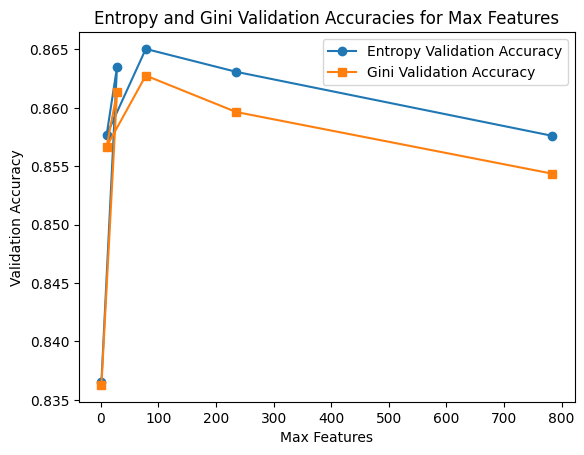

In [54]:
### part 3a - plot validation accuracy - Joe
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyValidationStats], marker='o', label='Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniValidationStats], marker='s', label="Gini Validation Accuracy")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Entropy and Gini Validation Accuracies for Max Features")
plt.legend()
plt.show()

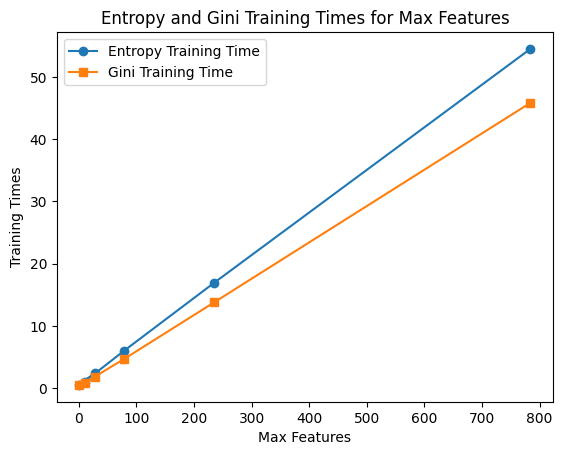

In [55]:
### part 3a - plot training times - Joe
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyTimeStats], marker='o', label='Entropy Training Time')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniTimeStats], marker='s', label="Gini Training Time")
ax.set_xlabel("Max Features")
ax.set_ylabel("Training Times")
ax.set_title("Entropy and Gini Training Times for Max Features")
plt.legend()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\690686711.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [56]:
### part3b - show stats as table - Joe
table = pd.DataFrame({
    'Max Features': maxFeatures,
    'Extra Trees Entropy Validation Accuracy' : combine(extraEntropyValidationStats),
    'Extra Trees Gini Validation Accuracy': combine(extraGiniValidationStats),
    'Extra Trees Entropy Training Times': combine(extraEntropyTimeStats),
    'Extra Trees Gini Training Times': combine(extraGiniTimeStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Extra Trees Entropy vs Gini Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(100)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

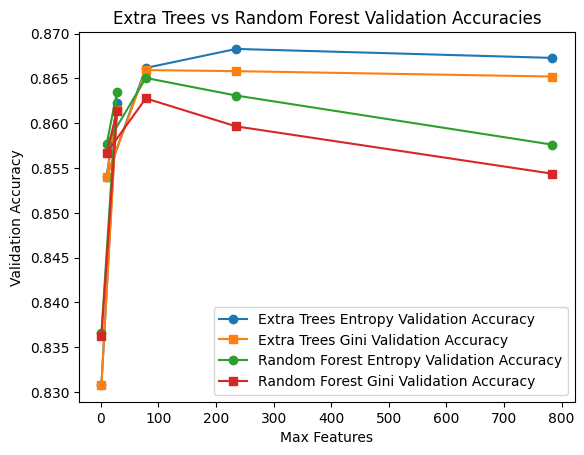

In [57]:
### part 3b - plot validation accuracy - Joe
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in extraEntropyValidationStats], marker='o', label='Extra Trees Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in extraGiniValidationStats], marker='s', label="Extra Trees Gini Validation Accuracy")
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyValidationStats], marker='o', label='Random Forest Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniValidationStats], marker='s', label="Random Forest Gini Validation Accuracy")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Extra Trees vs Random Forest Validation Accuracies")
plt.legend()
plt.show()

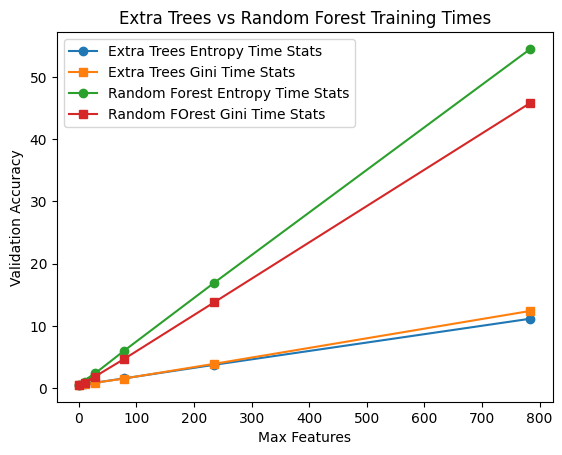

In [58]:
### part 3b - plot validation accuracy - Joe
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in extraEntropyTimeStats], marker='o', label='Extra Trees Entropy Time Stats')
ax.plot(maxFeatures, [i[0] for i in extraGiniTimeStats], marker='s', label="Extra Trees Gini Time Stats")
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyTimeStats], marker='o', label='Random Forest Entropy Time Stats')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniTimeStats], marker='s', label="Random FOrest Gini Time Stats")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Extra Trees vs Random Forest Training Times")
plt.legend()
plt.show()

In [59]:
### part 3c - feature importance - classification - Joe
#best model was extra trees with 200 max features and entropy
bestExtraEntropy = ExtraTreesClassifier(
    n_estimators=300,
    criterion='entropy',
    max_features=200,
    random_state=RANDOM_SEEDS[0],
    n_jobs=-1 # to compute faster
)
bestExtraEntropy.fit(xtrs[0], ytrs[0])

impureImports = bestExtraEntropy.feature_importances_
perm = permutation_importance(
    bestExtraEntropy,
    xvals[0],
    yvals[0],
    random_state=RANDOM_SEEDS[0],
    scoring='accuracy',
    n_jobs=-1
)
permImports = perm.importances_mean
impureReshape = impureImports.reshape(28, 28)
permReshape = permImports.reshape(28, 28)

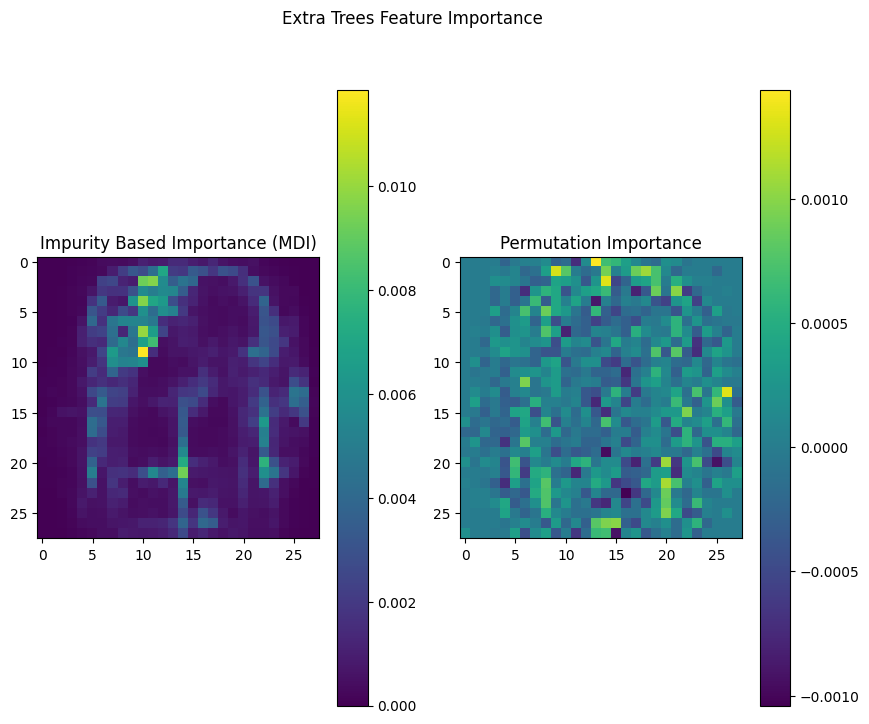

In [60]:
### part 3c - heatmap - classification - Joe
fig, axes = plt.subplots(1, 2, figsize=(10,8))

im1 = axes[0].imshow(impureReshape, cmap='viridis')
axes[0].set_title("Impurity Based Importance (MDI)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(permReshape, cmap='viridis')
axes[1].set_title("Permutation Importance")
fig.colorbar(im2, ax=axes[1])

plt.suptitle("Extra Trees Feature Importance")
plt.show()

In [61]:
### part 3c - feature importance - regression - Joe
#use extra trees with 200 max features
etRegressor = ExtraTreesRegressor(
    n_estimators=300,
    criterion='squared_error',#faster than absolute
    max_features=200,
    random_state=RANDOM_SEEDS[0],
    n_jobs=-1 # to compute faster
)
etRegressor.fit(regxtrs[0], regytrs[0])

regFI = etRegressor.feature_importances_
perm = permutation_importance(
    etRegressor,
    regxvals[0],
    regyvals[0],
    random_state=RANDOM_SEEDS[0],
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
regPI = perm.importances_mean

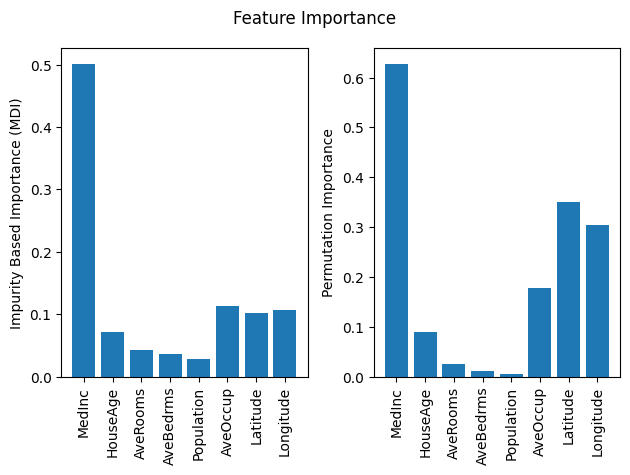

In [62]:
### part 3c - bar chart - Joe
features = californiaHousing.feature_names

fig, axes = plt.subplots(1, 2)

fig.suptitle("Feature Importance")
axes[0].bar(features, regFI)
axes[0].set_ylabel("Impurity Based Importance (MDI)")
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(features, regPI)
axes[1].set_ylabel("Permutation Importance")
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

### PART 4 - MAX

In [63]:
### Part 4 - Setup - Max

from joblib import Parallel, delayed
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from collections import Counter

ytrsI = [np.asarray(y).astype(int) for y in ytrs]
yvalsI = [np.asarray(y).astype(int) for y in yvals]
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
NUM_CLASSES = 10

def ms(v):
    return '{:.4f} ± {:.4f}'.format(np.mean(v), np.std(v, ddof=1))

ADA_DEPTHS = [1, 2, 4, 8]
ADA_LRS = [0.1, 0.5, 1.0]
ADA_ROUNDS = 500
QUICK = False          
if QUICK:
    ADA_ROUNDS = 100

In [64]:
### Part 4a.1 - First AdaBoost Run - Max

def run_adaboost(depth, lr, s, ytr=None, rounds=None):
    rounds = ADA_ROUNDS if rounds is None else rounds
    seed = RANDOM_SEEDS[s]
    ytr = ytrsI[s] if ytr is None else ytr          # ytr override is used for the label-noise experiment (4b)
    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=depth, random_state=seed),
        n_estimators=rounds,
        learning_rate=lr,
        random_state=seed
    )
    st = time.perf_counter()
    model.fit(xtrs[s], ytr)
    fitTime = time.perf_counter() - st

    # staged_predict gives the ensemble prediction after 1, 2, ..., T rounds
    trErr = [1 - accuracy_score(ytr, p) for p in model.staged_predict(xtrs[s])]
    vaErr = [1 - accuracy_score(yvalsI[s], p) for p in model.staged_predict(xvals[s])]
    nFit = len(trErr)

    trErr += [trErr[-1]] * (rounds - nFit)
    vaErr += [vaErr[-1]] * (rounds - nFit)
    return {'depth': depth, 'lr': lr, 'seed': s, 'trainErr': np.array(trErr), 'valErr': np.array(vaErr),
            'nFit': nFit, 'time': fitTime}

def firstZeroRound(trErr):
    z = np.where(np.asarray(trErr) == 0)[0]
    return int(z[0]) + 1 if len(z) else None

In [65]:
### Part 4a.2 - Grid - Max

adaConfigs = [(d, lr) for d in ADA_DEPTHS for lr in ADA_LRS]
adaGrid = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(d, lr, 0) for d, lr in adaConfigs)
adaGridDict = {(r['depth'], r['lr']): r for r in adaGrid}

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   4 out of  12 | elapsed:  7.9min remaining: 15.9min
[Parallel(n_jobs=-1)]: Done   7 out of  12 | elapsed: 13.3min remaining:  9.5min
[Parallel(n_jobs=-1)]: Done  10 out of  12 | elapsed: 24.2min remaining:  4.8min
[Parallel(n_jobs=-1)]: Done  12 out of  12 | elapsed: 24.3min finished


In [66]:
### Part 4a.3 - Summary Table - Max
rows = []
for (d, lr), r in adaGridDict.items():
    fz = firstZeroRound(r['trainErr'])
    rows.append({
        'Depth': d, 'LR': lr, 'Rounds fit': r['nFit'],
        'Final train err': round(r['trainErr'][-1], 4),
        'Final val err': round(r['valErr'][-1], 4),
        'Best val err': round(r['valErr'].min(), 4),
        'Best round': int(r['valErr'].argmin()) + 1,
        'First round train err = 0': fz,
        'Val err at that round': round(r['valErr'][fz-1], 4) if fz else None,
        'Fit time (s)': round(r['time'], 1),
    })
adaGridTable = pd.DataFrame(rows)
adaGridTable

,Depth,LR,Rounds fit,Final train err,Final val err,Best val err,Best round,First round train err = 0,Val err at that round,Fit time (s)
0,1,0.1,500,0.4865,0.4844,0.4816,497,NaN,NaN,255.1
1,1,0.5,500,0.4241,0.4182,0.4108,441,NaN,NaN,255.3
2,1,1.0,500,0.3818,0.3826,0.3668,215,NaN,NaN,255.2
3,2,0.1,500,0.3078,0.3098,0.2608,207,NaN,NaN,452.2
4,2,0.5,500,0.3179,0.3358,0.2652,41,NaN,NaN,452.9
5,2,1.0,500,0.2738,0.2946,0.2804,68,NaN,NaN,452.5
6,4,0.1,500,0.1235,0.1656,0.1588,182,NaN,NaN,782.4
7,4,0.5,500,0.1093,0.1732,0.1716,307,NaN,NaN,781.7
8,4,1.0,500,0.1107,0.1862,0.1814,477,NaN,NaN,784.2
9,8,0.1,500,0.0000,0.1264,0.1224,339,108.0,0.1304,1442.3


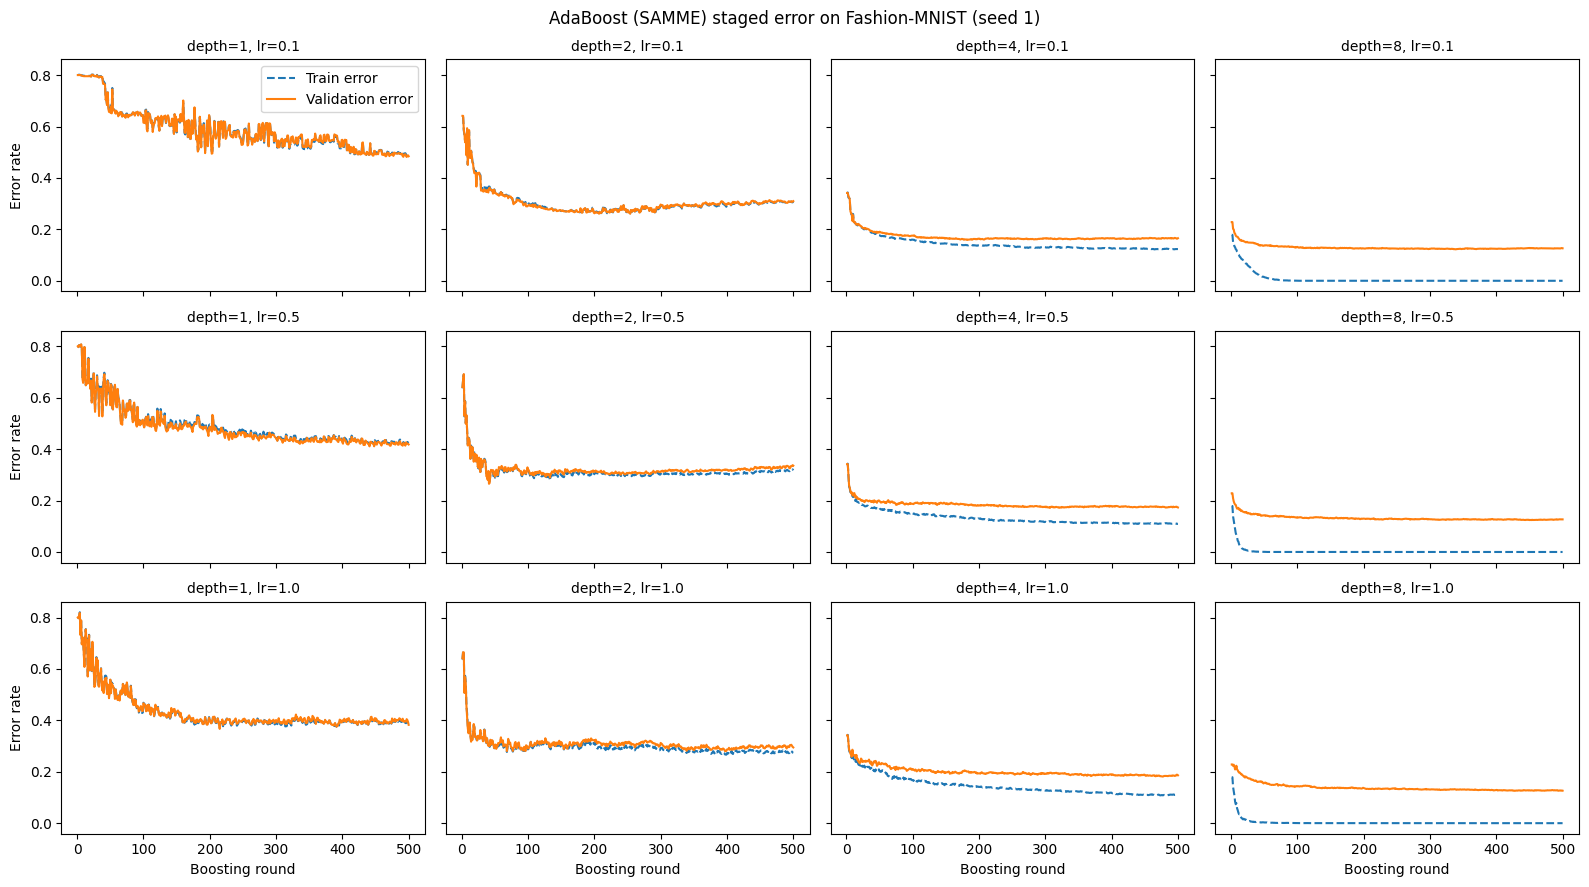

In [67]:
### Part 4a.4 - Plot Staged Errors - Max

fig, axes = plt.subplots(len(ADA_LRS), len(ADA_DEPTHS), figsize=(16, 9), sharex=True, sharey=True)
for i, lr in enumerate(ADA_LRS):
    for j, d in enumerate(ADA_DEPTHS):
        r = adaGridDict[(d, lr)]
        ax = axes[i][j]
        ax.plot(np.arange(1, len(r['trainErr']) + 1), r['trainErr'], linestyle='--', label='Train error')
        ax.plot(np.arange(1, len(r['valErr']) + 1), r['valErr'], label='Validation error')
        ax.set_title('depth={}, lr={}'.format(d, lr), fontsize=10)
        if i == len(ADA_LRS) - 1:
            ax.set_xlabel('Boosting round')
        if j == 0:
            ax.set_ylabel('Error rate')
axes[0][0].legend()
fig.suptitle('AdaBoost (SAMME) staged error on Fashion-MNIST (seed 1)')
plt.tight_layout()
plt.savefig('part4a_staged_error.png', dpi=150)
plt.show()

In [68]:
### Part 4a.5 - Analyze Best Models - Max

bestKey = min(adaGridDict, key=lambda k: adaGridDict[k]['valErr'].min())
bestStumpKey = min([k for k in adaGridDict if k[0] == 1], key=lambda k: adaGridDict[k]['valErr'].min())
bestRound = int(adaGridDict[bestKey]['valErr'].argmin()) + 1
print('Best overall (depth, lr):', bestKey, 'at round', bestRound)
print('Best stump   (depth, lr):', bestStumpKey)

adaSeeds = {}
for key in dict.fromkeys([bestKey, bestStumpKey]):
    others = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(key[0], key[1], s) for s in range(1, len(RANDOM_SEEDS)))
    adaSeeds[key] = [adaGridDict[key]] + others      # seed index 0 already computed in the grid

for key, runs in adaSeeds.items():
    va = np.array([r['valErr'] for r in runs]); tr = np.array([r['trainErr'] for r in runs])
    print('\n(depth, lr) = {}'.format(key))
    print('  val err  @ final round : {:.4f} ± {:.4f}'.format(va[:, -1].mean(), va[:, -1].std(ddof=1)))
    print('  val err  @ round {:>3}   : {:.4f} ± {:.4f}'.format(bestRound, va[:, bestRound-1].mean(), va[:, bestRound-1].std(ddof=1)))
    print('  train err@ final round : {:.4f} ± {:.4f}'.format(tr[:, -1].mean(), tr[:, -1].std(ddof=1)))
    print('  rounds actually fit    : {}'.format([r['nFit'] for r in runs]))

Best overall (depth, lr): (8, 0.1) at round 339
Best stump   (depth, lr): (1, 1.0)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   4 | elapsed: 19.7min remaining: 19.7min
[Parallel(n_jobs=-1)]: Done   4 out of   4 | elapsed: 19.8min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   4 | elapsed:  3.1min remaining:  3.1min



(depth, lr) = (8, 0.1)
  val err  @ final round : 0.1308 ± 0.0033
  val err  @ round 339   : 0.1304 ± 0.0054
  train err@ final round : 0.0000 ± 0.0000
  rounds actually fit    : [500, 500, 500, 500, 500]

(depth, lr) = (1, 1.0)
  val err  @ final round : 0.4057 ± 0.0218
  val err  @ round 339   : 0.4156 ± 0.0145
  train err@ final round : 0.3985 ± 0.0150
  rounds actually fit    : [500, 500, 500, 500, 500]


[Parallel(n_jobs=-1)]: Done   4 out of   4 | elapsed:  3.1min finished


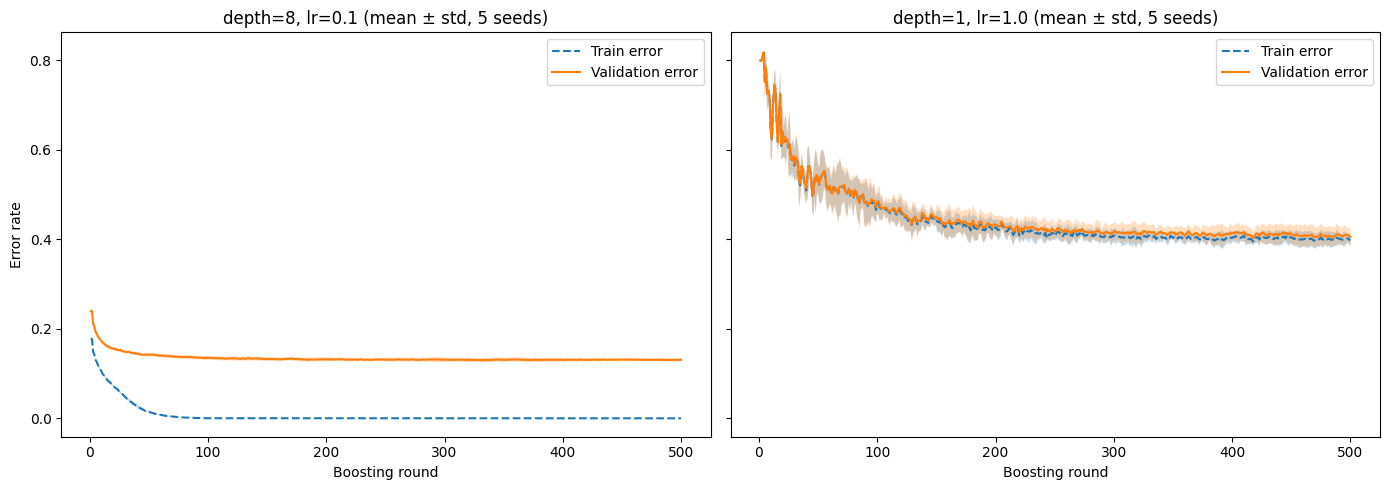

In [69]:
### Part 4a.6 - Plot Best Configurations - Max

fig, axes = plt.subplots(1, len(adaSeeds), figsize=(7 * len(adaSeeds), 5), sharey=True, squeeze=False)
for ax, (key, runs) in zip(axes[0], adaSeeds.items()):
    x = np.arange(1, ADA_ROUNDS + 1)
    for name, field, style in [('Train error', 'trainErr', '--'), ('Validation error', 'valErr', '-')]:
        arr = np.array([r[field] for r in runs])
        mu, sd = arr.mean(axis=0), arr.std(axis=0, ddof=1)
        ax.plot(x, mu, linestyle=style, label=name)
        ax.fill_between(x, mu - sd, mu + sd, alpha=0.25)
    ax.set_title('depth={}, lr={} (mean ± std, 5 seeds)'.format(*key))
    ax.set_xlabel('Boosting round')
    ax.legend()
axes[0][0].set_ylabel('Error rate')
plt.tight_layout()
plt.savefig('part4a_best_configs.png', dpi=150)
plt.show()

In [70]:
### Part 4b.1 - Sample Weights - Max

def adaboost_sample_weights(model, X, y):
    K = len(model.classes_)
    w = np.full(len(y), 1.0 / len(y))
    alphaRecomputed = []
    for est, a in zip(model.estimators_, model.estimator_weights_):
        incorrect = (est.predict(X) != y)
        err = np.sum(w * incorrect)
        alphaRecomputed.append(model.learning_rate * (np.log((1 - err) / err) + np.log(K - 1)))
        w = w * np.exp(a * incorrect)
        w = w / w.sum()
    n = min(len(alphaRecomputed), len(model.estimator_weights_))
    return w, np.max(np.abs(np.array(alphaRecomputed)[:n] - model.estimator_weights_[:n]))

bd, blr = bestKey
ada50 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[0]),
    n_estimators=50, learning_rate=blr, random_state=RANDOM_SEEDS[0]
)
ada50.fit(xtrs[0], ytrsI[0])
assert len(ada50.estimators_) == 50, len(ada50.estimators_)
w50, alphaDiff = adaboost_sample_weights(ada50, xtrs[0], ytrsI[0])
print('Rounds fit:', len(ada50.estimators_), '| max |alpha_replay - alpha_sklearn| = {:.2e}'.format(alphaDiff))

top = np.argsort(w50)[::-1][:20]
pred50 = ada50.predict(xtrs[0][top])
print('Share of total weight on the top 20 samples : {:.3f}'.format(w50[top].sum()))
print('Share of total weight on the top 1% samples : {:.3f}'.format(np.sort(w50)[::-1][:len(w50)//100].sum()))
print('Max weight / median weight                  : {:.1f}'.format(w50.max() / np.median(w50)))
print('Top-20 still misclassified by the 50-round ensemble: {}/20'.format(int(np.sum(pred50 != ytrsI[0][top]))))
print('True classes among top 20:', Counter(CLASS_NAMES[c] for c in ytrsI[0][top]))


Rounds fit: 50 | max |alpha_replay - alpha_sklearn| = 1.11e-16
Share of total weight on the top 20 samples : 0.042
Share of total weight on the top 1% samples : 0.148
Max weight / median weight                  : 155.5
Top-20 still misclassified by the 50-round ensemble: 12/20
True classes among top 20: Counter({'Shirt': 6, 'Pullover': 4, 'Dress': 3, 'Coat': 3, 'Trouser': 2, 'Bag': 1, 'T-shirt/top': 1})


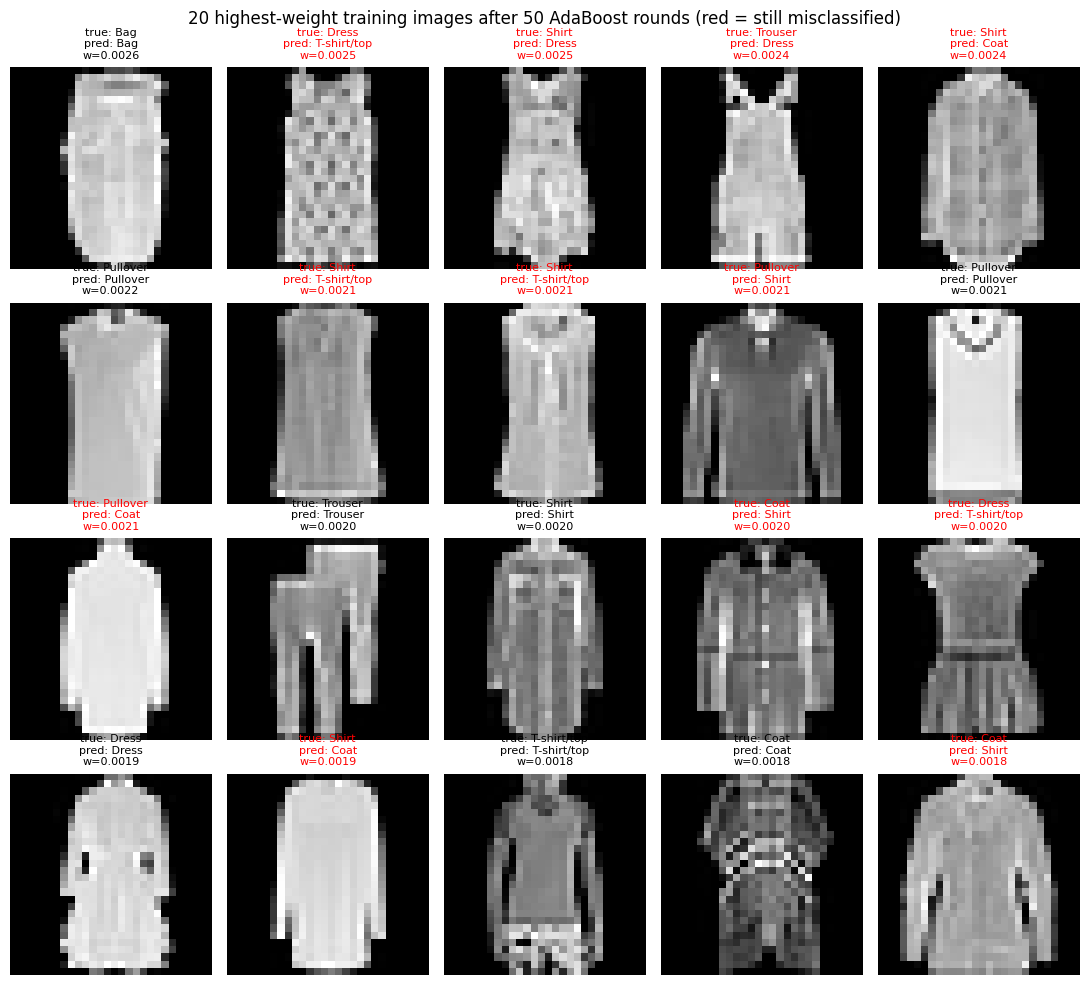

In [71]:
### Part 4b.2 - Visualize Top-Weight Samples - Max

fig, axes = plt.subplots(4, 5, figsize=(11, 10))
for ax, i, p in zip(axes.ravel(), top, pred50):
    ax.imshow(xtrs[0][i].reshape(28, 28), cmap='gray')
    wrong = (p != ytrsI[0][i])
    ax.set_title('true: {}\npred: {}\nw={:.4f}'.format(CLASS_NAMES[ytrsI[0][i]], CLASS_NAMES[p], w50[i]),
                 fontsize=8, color='red' if wrong else 'black')
    ax.axis('off')
    
fig.suptitle('20 highest-weight training images after 50 AdaBoost rounds (red = still misclassified)')
plt.tight_layout()
plt.savefig('part4b_top_weights.png', dpi=150)
plt.show()

In [72]:
### Part 4b.3 - Noise Robustness - Max

NOISE = 0.10
RF_PARAMS = dict(n_estimators=300, criterion='gini', max_features=28)

def flip_labels(y, frac, seed):
    rng = np.random.default_rng(seed)
    y2 = y.copy()
    idx = rng.choice(len(y), size=int(round(frac * len(y))), replace=False)
    y2[idx] = (y2[idx] + rng.integers(1, NUM_CLASSES, size=len(idx))) % NUM_CLASSES
    return y2, idx

noisyLabels, flippedIdx = [], []
for s in range(len(RANDOM_SEEDS)):
    yn, fi = flip_labels(ytrsI[s], NOISE, RANDOM_SEEDS[s])
    noisyLabels.append(yn); flippedIdx.append(fi)

adaNoisy = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(bd, blr, s, ytr=noisyLabels[s]) for s in range(len(RANDOM_SEEDS)))

def run_rf(s, ytr):
    rf = RandomForestClassifier(**RF_PARAMS, random_state=RANDOM_SEEDS[s], n_jobs=-1)
    rf.fit(xtrs[s], ytr)
    return accuracy_score(yvalsI[s], rf.predict(xvals[s]))
rfClean = [run_rf(s, ytrsI[s]) for s in range(len(RANDOM_SEEDS))]
rfNoisy = [run_rf(s, noisyLabels[s]) for s in range(len(RANDOM_SEEDS))]

adaCleanRuns = adaSeeds[bestKey]
adaCleanAcc = [1 - r['valErr'][bestRound - 1] for r in adaCleanRuns]
adaNoisyAcc = [1 - r['valErr'][bestRound - 1] for r in adaNoisy]
adaCleanFinal = [1 - r['valErr'][-1] for r in adaCleanRuns]
adaNoisyFinal = [1 - r['valErr'][-1] for r in adaNoisy]
noisyBestRound = int(np.mean([r['valErr'] for r in adaNoisy], axis=0).argmin()) + 1
adaNoisyBest = [1 - r['valErr'][noisyBestRound - 1] for r in adaNoisy]

noiseTable = pd.DataFrame({
    'Model': ['AdaBoost (depth={}, lr={}) @ round {}'.format(bd, blr, bestRound),
              'AdaBoost @ round {}'.format(ADA_ROUNDS),
              'AdaBoost @ own best round (clean {}, noisy {})'.format(bestRound, noisyBestRound),
              'Random forest'],
    'Clean val acc': [ms(adaCleanAcc), ms(adaCleanFinal), ms(adaCleanAcc), ms(rfClean)],
    '10% noisy val acc': [ms(adaNoisyAcc), ms(adaNoisyFinal), ms(adaNoisyBest), ms(rfNoisy)],
    'Drop (pts)': [ms(100*(np.array(adaCleanAcc)-np.array(adaNoisyAcc))),
                   ms(100*(np.array(adaCleanFinal)-np.array(adaNoisyFinal))),
                   ms(100*(np.array(adaCleanAcc)-np.array(adaNoisyBest))),
                   ms(100*(np.array(rfClean)-np.array(rfNoisy)))],
})
noiseTable

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed: 22.8min remaining: 34.2min
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed: 23.2min finished


,Model,Clean val acc,10% noisy val acc,Drop (pts)
0,"AdaBoost (depth=8, lr=0.1) @ round 339",0.8696 ± 0.0054,0.8524 ± 0.0050,1.7160 ± 0.4642
1,AdaBoost @ round 500,0.8692 ± 0.0033,0.8539 ± 0.0053,1.5320 ± 0.4187
2,"AdaBoost @ own best round (clean 339, noisy 488)",0.8696 ± 0.0054,0.8546 ± 0.0051,1.4960 ± 0.3474
3,Random forest,0.8613 ± 0.0043,0.8588 ± 0.0038,0.2560 ± 0.2504


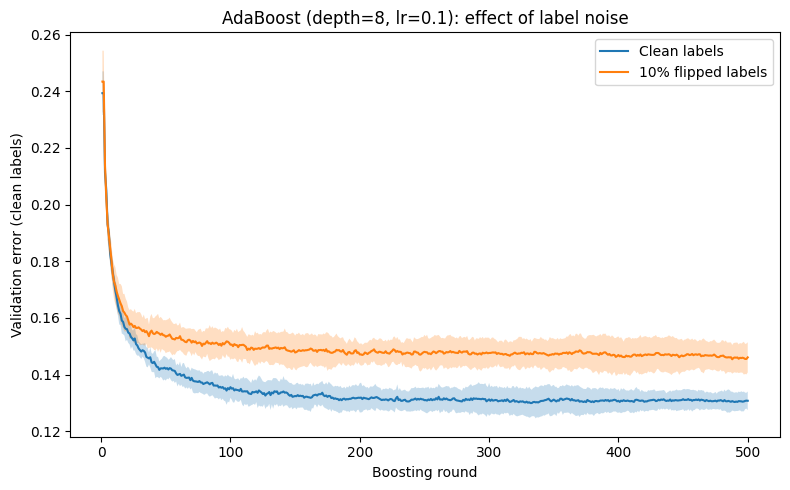

Flipped labels are 10% of the training set but 98% of the 100 highest-weight samples.
Share of total weight held by flipped samples: 0.52


In [73]:
### Part 4b.4 - Plot Noise Robustness - Max

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(1, ADA_ROUNDS + 1)
for name, runs in [('Clean labels', adaCleanRuns), ('10% flipped labels', adaNoisy)]:
    arr = np.array([r['valErr'] for r in runs])
    mu, sd = arr.mean(axis=0), arr.std(axis=0, ddof=1)
    ax.plot(x, mu, label=name)
    ax.fill_between(x, mu - sd, mu + sd, alpha=0.25)
ax.set_xlabel('Boosting round')
ax.set_ylabel('Validation error (clean labels)')
ax.set_title('AdaBoost (depth={}, lr={}): effect of label noise'.format(bd, blr))
ax.legend()
plt.tight_layout()
plt.savefig('part4b_noise_curves.png', dpi=150)
plt.show()

### where does the weight go when labels are noisy? (seed index 0, 50 rounds)
ada50n = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[0]),
    n_estimators=50, learning_rate=blr, random_state=RANDOM_SEEDS[0]
)
ada50n.fit(xtrs[0], noisyLabels[0])
w50n, _ = adaboost_sample_weights(ada50n, xtrs[0], noisyLabels[0])
isFlipped = np.zeros(len(w50n), dtype=bool); isFlipped[flippedIdx[0]] = True
top100 = np.argsort(w50n)[::-1][:100]
print('Flipped labels are {:.0%} of the training set but {:.0%} of the 100 highest-weight samples.'.format(
    isFlipped.mean(), isFlipped[top100].mean()))
print('Share of total weight held by flipped samples: {:.2f}'.format(w50n[isFlipped].sum()))

In [74]:
### Part 4c.1 - HistGradientBoostingClassifier - Max

HGB_LRS = [0.03, 0.1, 0.3]
HGB_DEPTHS = [2, 4, 8]
HGB_MAX_ITER = 500

def run_hgb(lr, depth, s):
    seed = RANDOM_SEEDS[s]
    m = HistGradientBoostingClassifier(
        learning_rate=lr, max_depth=depth, max_leaf_nodes=None,     # let depth (not the default 31-leaf cap) control size
        max_iter=HGB_MAX_ITER, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, scoring='loss', random_state=seed
    )
    st = time.perf_counter()
    m.fit(xtrs[s], ytrsI[s])
    fitTime = time.perf_counter() - st
    curve = [accuracy_score(yvalsI[s], p) for p in m.staged_predict(xvals[s])]
    return {'lr': lr, 'depth': depth, 'seed': s, 'nIter': m.n_iter_, 'time': fitTime, 'valAccCurve': np.array(curve),
            'valAcc': curve[-1], 'valF1': f1_score(yvalsI[s], m.predict(xvals[s]), average='macro'),
            'trainAcc': m.score(xtrs[s], ytrsI[s])}

hgbGrid = {}
for d in HGB_DEPTHS:
    for lr in HGB_LRS:
        hgbGrid[(lr, d)] = run_hgb(lr, d, 0)
        print('lr={}, depth={}: stopped at {} rounds, val acc {:.4f}, {:.1f}s'.format(
            lr, d, hgbGrid[(lr, d)]['nIter'], hgbGrid[(lr, d)]['valAcc'], hgbGrid[(lr, d)]['time']))

hgbTable = pd.DataFrame([{'LR': k[0], 'Depth': k[1], 'Rounds (early stop, incl. 20 patience)': r['nIter'], 'Train acc': round(r['trainAcc'], 4),
                          'Val acc': round(r['valAcc'], 4), 'Val macro-F1': round(r['valF1'], 4), 'Fit time (s, under parallel load)': round(r['time'], 1)}
                         for k, r in hgbGrid.items()])
hgbTable

lr=0.03, depth=2: stopped at 500 rounds, val acc 0.8676, 38.9s
lr=0.1, depth=2: stopped at 237 rounds, val acc 0.8698, 17.9s
lr=0.3, depth=2: stopped at 109 rounds, val acc 0.8686, 8.4s
lr=0.03, depth=4: stopped at 336 rounds, val acc 0.8784, 66.2s
lr=0.1, depth=4: stopped at 136 rounds, val acc 0.8798, 26.2s
lr=0.3, depth=4: stopped at 46 rounds, val acc 0.8702, 9.3s
lr=0.03, depth=8: stopped at 169 rounds, val acc 0.8744, 131.4s
lr=0.1, depth=8: stopped at 67 rounds, val acc 0.8748, 35.2s
lr=0.3, depth=8: stopped at 35 rounds, val acc 0.8762, 18.5s


,LR,Depth,"Rounds (early stop, incl. 20 patience)",Train acc,Val acc,Val macro-F1,"Fit time (s, under parallel load)"
0,0.03,2,500,0.9416,0.8676,0.8666,38.9
1,0.10,2,237,0.9683,0.8698,0.8691,17.9
2,0.30,2,109,0.9811,0.8686,0.8681,8.4
3,0.03,4,336,0.9871,0.8784,0.8776,66.2
4,0.10,4,136,0.9880,0.8798,0.8792,26.2
5,0.30,4,46,0.9851,0.8702,0.8698,9.3
6,0.03,8,169,0.9881,0.8744,0.8730,131.4
7,0.10,8,67,0.9878,0.8748,0.8736,35.2
8,0.30,8,35,0.9880,0.8762,0.8752,18.5


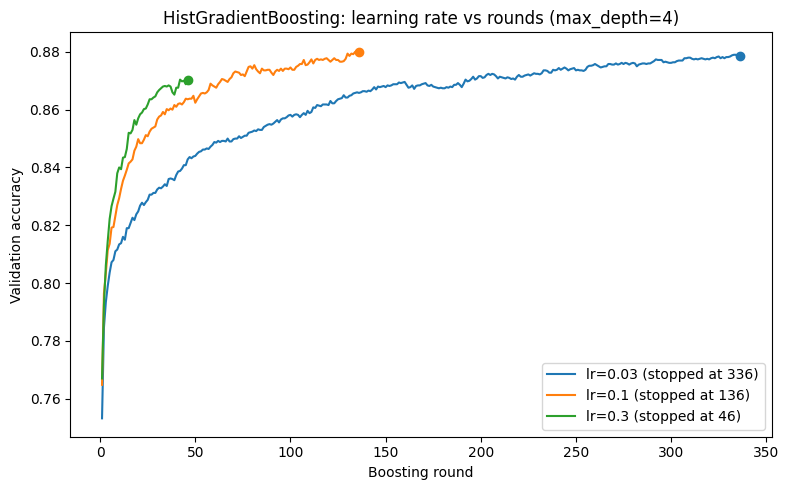

Best HGB (lr, depth) = (0.1, 4)
  val acc  : 0.8746 ± 0.0035
  val F1   : 0.8744 ± 0.0031
  rounds   : 131.0000 ± 9.2195
  fit time : 17.0997 ± 5.1480


In [75]:
### Part 4c.2 - Plot Learning Rate vs Rounds - Max

hgbBestKey = max(hgbGrid, key=lambda k: hgbGrid[k]['valAcc'])
hgbBestDepth = hgbBestKey[1]
fig, ax = plt.subplots(figsize=(8, 5))
for lr in HGB_LRS:
    r = hgbGrid[(lr, hgbBestDepth)]
    line, = ax.plot(np.arange(1, len(r['valAccCurve']) + 1), r['valAccCurve'], label='lr={} (stopped at {})'.format(lr, r['nIter']))
    ax.plot(r['nIter'], r['valAccCurve'][-1], 'o', color=line.get_color())
ax.set_xlabel('Boosting round')
ax.set_ylabel('Validation accuracy')
ax.set_title('HistGradientBoosting: learning rate vs rounds (max_depth={})'.format(hgbBestDepth))
ax.legend()
plt.tight_layout()
plt.savefig('part4c_hgb_lr_rounds.png', dpi=150)
plt.show()

hgbRuns = [hgbGrid[hgbBestKey]] + [run_hgb(hgbBestKey[0], hgbBestKey[1], s) for s in range(1, len(RANDOM_SEEDS))]
print('Best HGB (lr, depth) =', hgbBestKey)
print('  val acc  : ' + ms([r['valAcc'] for r in hgbRuns]))
print('  val F1   : ' + ms([r['valF1'] for r in hgbRuns]))
print('  rounds   : ' + ms([r['nIter'] for r in hgbRuns]))
print('  fit time : ' + ms([r['time'] for r in hgbRuns]))

In [76]:
### Part 4c.3 - Gradient Boosting Regressor - Max

GBR_LRS = [0.03, 0.1, 0.3]
GBR_DEPTHS = [2, 3, 4, 6]
GBR_MAX_EST = 2000

def run_gbr(lr, depth, s):
    seed = RANDOM_SEEDS[s]
    m = GradientBoostingRegressor(
        learning_rate=lr, max_depth=depth, n_estimators=GBR_MAX_EST,
        validation_fraction=0.1, n_iter_no_change=20, tol=1e-4, random_state=seed   # early stopping on an internal split of the training data
    )
    st = time.perf_counter()
    m.fit(regxtrs[s], regytrs[s])
    fitTime = time.perf_counter() - st
    rmse, mae = [], []
    for p in m.staged_predict(regxvals[s]):
        rmse.append(root_mean_squared_error(regyvals[s], p)); mae.append(mean_absolute_error(regyvals[s], p))
    return {'lr': lr, 'depth': depth, 'seed': s, 'nEst': m.n_estimators_, 'time': fitTime,
            'rmseCurve': np.array(rmse), 'maeCurve': np.array(mae), 'rmse': rmse[-1], 'mae': mae[-1]}

gbrGrid = {}
for d in GBR_DEPTHS:
    for lr in GBR_LRS:
        gbrGrid[(lr, d)] = run_gbr(lr, d, 0)
        print('lr={}, depth={}: {} trees, val RMSE {:.4f}'.format(lr, d, gbrGrid[(lr, d)]['nEst'], gbrGrid[(lr, d)]['rmse']))

gbrTable = pd.DataFrame([{'LR': k[0], 'Depth': k[1], 'Trees (early stop, incl. 20 patience)': r['nEst'], 'Val RMSE': round(r['rmse'], 4),
                          'Val MAE': round(r['mae'], 4), 'Fit time (s, under parallel load)': round(r['time'], 1)} for k, r in gbrGrid.items()])
gbrTable

lr=0.03, depth=2: 1747 trees, val RMSE 0.5082
lr=0.1, depth=2: 461 trees, val RMSE 0.5108
lr=0.3, depth=2: 252 trees, val RMSE 0.5026
lr=0.03, depth=3: 972 trees, val RMSE 0.4915
lr=0.1, depth=3: 493 trees, val RMSE 0.4801
lr=0.3, depth=3: 289 trees, val RMSE 0.4763
lr=0.03, depth=4: 783 trees, val RMSE 0.4735
lr=0.1, depth=4: 427 trees, val RMSE 0.4672
lr=0.3, depth=4: 159 trees, val RMSE 0.4795
lr=0.03, depth=6: 558 trees, val RMSE 0.4663
lr=0.1, depth=6: 147 trees, val RMSE 0.4702
lr=0.3, depth=6: 95 trees, val RMSE 0.4820


,LR,Depth,"Trees (early stop, incl. 20 patience)",Val RMSE,Val MAE,"Fit time (s, under parallel load)"
0,0.03,2,1747,0.5082,0.3525,25.0
1,0.10,2,461,0.5108,0.3545,6.7
2,0.30,2,252,0.5026,0.3472,3.7
3,0.03,3,972,0.4915,0.3395,21.4
4,0.10,3,493,0.4801,0.3295,11.4
5,0.30,3,289,0.4763,0.3261,8.1
6,0.03,4,783,0.4735,0.3241,27.2
7,0.10,4,427,0.4672,0.3175,14.6
8,0.30,4,159,0.4795,0.3292,5.3
9,0.03,6,558,0.4663,0.3170,27.1


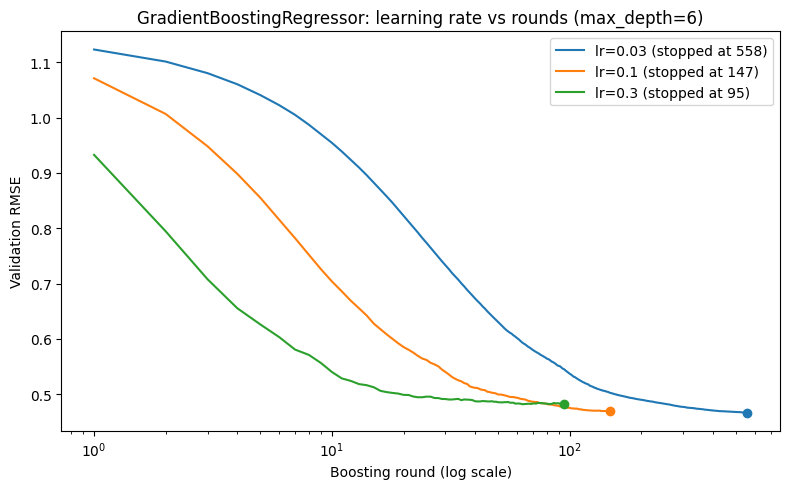

In [77]:
### Part 4c.4 - Plot Learning Rate vs Rounds - Max

gbrBestKey = min(gbrGrid, key=lambda k: gbrGrid[k]['rmse'])
gbrBestDepth = gbrBestKey[1]
fig, ax = plt.subplots(figsize=(8, 5))
for lr in GBR_LRS:
    r = gbrGrid[(lr, gbrBestDepth)]
    line, = ax.plot(np.arange(1, len(r['rmseCurve']) + 1), r['rmseCurve'], label='lr={} (stopped at {})'.format(lr, r['nEst']))
    ax.plot(r['nEst'], r['rmseCurve'][-1], 'o', color=line.get_color())
ax.set_xscale('log')
ax.set_xlabel('Boosting round (log scale)')
ax.set_ylabel('Validation RMSE')
ax.set_title('GradientBoostingRegressor: learning rate vs rounds (max_depth={})'.format(gbrBestDepth))
ax.legend()
plt.tight_layout()
plt.savefig('part4c_gbr_lr_rounds.png', dpi=150)
plt.show()

In [78]:
### Part 4c.5 - AdaBoost.R2 - Max

ADAR_DEPTHS = [3, 5, 8]
ADAR_LRS = [0.1, 0.5, 1.0]
ADAR_LOSSES = ['linear', 'square', 'exponential']
ADAR_ROUNDS = 200

def run_adar2(depth, lr, loss, s):
    seed = RANDOM_SEEDS[s]
    m = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=depth, random_state=seed),
        n_estimators=ADAR_ROUNDS, learning_rate=lr, loss=loss, random_state=seed
    )
    m.fit(regxtrs[s], regytrs[s])
    rmse, mae = [], []
    for p in m.staged_predict(regxvals[s]):
        rmse.append(root_mean_squared_error(regyvals[s], p)); mae.append(mean_absolute_error(regyvals[s], p))
    nFit = len(rmse)
    rmse += [rmse[-1]] * (ADAR_ROUNDS - nFit); mae += [mae[-1]] * (ADAR_ROUNDS - nFit)   # pad if it stopped early
    return {'depth': depth, 'lr': lr, 'loss': loss, 'seed': s, 'nFit': nFit,
            'rmseCurve': np.array(rmse), 'maeCurve': np.array(mae)}

adarConfigs = [(d, lr, ls) for d in ADAR_DEPTHS for lr in ADAR_LRS for ls in ADAR_LOSSES]
adarGrid = Parallel(n_jobs=-1, verbose=5)(delayed(run_adar2)(d, lr, ls, 0) for d, lr, ls in adarConfigs)
adarGridDict = {(r['depth'], r['lr'], r['loss']): r for r in adarGrid}
adarBestKey = min(adarGridDict, key=lambda k: adarGridDict[k]['rmseCurve'].min())
adarBestRound = int(adarGridDict[adarBestKey]['rmseCurve'].argmin()) + 1
print('Best AdaBoost.R2 (depth, lr, loss):', adarBestKey, 'at round', adarBestRound)

print('At grid edge? depth:', adarBestKey[0] == max(ADAR_DEPTHS),
    '| lr:', adarBestKey[1] == max(ADAR_LRS),
    '| round:', adarBestRound >= ADAR_ROUNDS - 5)

adarTable = pd.DataFrame([{'Depth': k[0], 'LR': k[1], 'Loss': k[2], 'Best val RMSE': round(r['rmseCurve'].min(), 4),
                           'Best round': int(r['rmseCurve'].argmin()) + 1} for k, r in adarGridDict.items()]).sort_values('Best val RMSE')
adarTable.head(10)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   4 out of  27 | elapsed:   17.2s remaining:  1.7min
[Parallel(n_jobs=-1)]: Done  10 out of  27 | elapsed:   20.3s remaining:   34.6s
[Parallel(n_jobs=-1)]: Done  16 out of  27 | elapsed:   23.6s remaining:   16.2s
[Parallel(n_jobs=-1)]: Done  22 out of  27 | elapsed:   26.8s remaining:    6.0s


Best AdaBoost.R2 (depth, lr, loss): (8, 0.5, 'square') at round 63
At grid edge? depth: True | lr: False | round: False


[Parallel(n_jobs=-1)]: Done  27 out of  27 | elapsed:   30.2s finished


,Depth,LR,Loss,Best val RMSE,Best round
22,8,0.5,square,0.5338,63
25,8,1.0,square,0.5418,78
19,8,0.1,square,0.5446,200
18,8,0.1,linear,0.5450,183
21,8,0.5,linear,0.5451,48
20,8,0.1,exponential,0.5456,179
23,8,0.5,exponential,0.5469,62
26,8,1.0,exponential,0.5490,27
24,8,1.0,linear,0.5516,26
17,5,1.0,exponential,0.6439,8


In [79]:
### Part 4c.6 - Compare Regression Models - Max

gbrRuns = [gbrGrid[gbrBestKey]] + [run_gbr(gbrBestKey[0], gbrBestKey[1], s) for s in range(1, len(RANDOM_SEEDS))]
adarRuns = [adarGridDict[adarBestKey]] + [run_adar2(*adarBestKey, s) for s in range(1, len(RANDOM_SEEDS))]

# baseline: best single regression tree per seed (depth chosen on validation)
treeRmse, treeMae = [], []
for s in range(len(RANDOM_SEEDS)):
    best = None
    for d in [4, 6, 8, 10]:
        t = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s])
        p = t.predict(regxvals[s]); e = root_mean_squared_error(regyvals[s], p)
        if best is None or e < best[0]:
            best = (e, mean_absolute_error(regyvals[s], p))
    treeRmse.append(best[0]); treeMae.append(best[1])

regCompare = pd.DataFrame({
    'Model': ['Single tree (best depth)',
              'GradientBoosting (lr={}, depth={})'.format(*gbrBestKey),
              'AdaBoost.R2 (depth={}, lr={}, loss={}, {} rounds)'.format(*adarBestKey, adarBestRound)],
    'Val RMSE': [ms(treeRmse), ms([r['rmse'] for r in gbrRuns]), ms([r['rmseCurve'][adarBestRound-1] for r in adarRuns])],
    'Val MAE':  [ms(treeMae),  ms([r['mae'] for r in gbrRuns]),  ms([r['maeCurve'][adarBestRound-1] for r in adarRuns])],
})
regCompare

,Model,Val RMSE,Val MAE
0,Single tree (best depth),0.6448 ± 0.0142,0.4262 ± 0.0090
1,"GradientBoosting (lr=0.03, depth=6)",0.4643 ± 0.0045,0.3090 ± 0.0046
2,"AdaBoost.R2 (depth=8, lr=0.5, loss=square, 63 ...",0.5454 ± 0.0121,0.4184 ± 0.0140


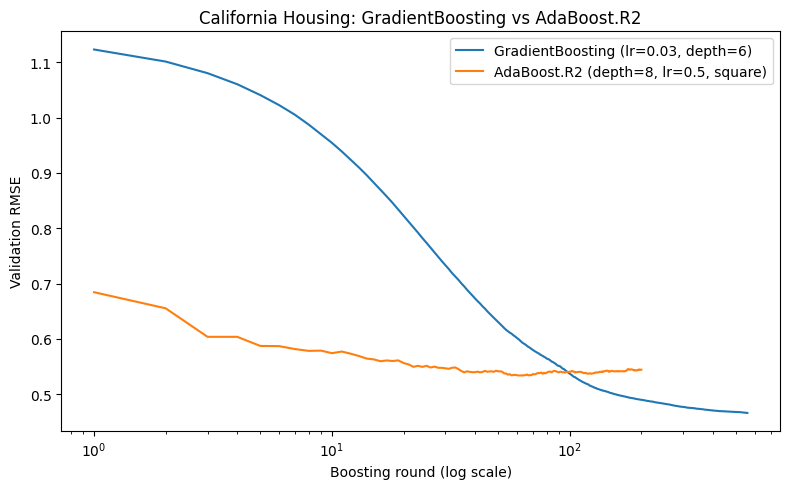

In [80]:
### Part 4c - Plot Regression Curves - Max

fig, ax = plt.subplots(figsize=(8, 5))
rg = gbrRuns[0]; ra = adarRuns[0]
ax.plot(np.arange(1, len(rg['rmseCurve']) + 1), rg['rmseCurve'], label='GradientBoosting (lr={}, depth={})'.format(*gbrBestKey))
ax.plot(np.arange(1, len(ra['rmseCurve']) + 1), ra['rmseCurve'], label='AdaBoost.R2 (depth={}, lr={}, {})'.format(*adarBestKey))
ax.set_xscale('log')
ax.set_xlabel('Boosting round (log scale)')
ax.set_ylabel('Validation RMSE')
ax.set_title('California Housing: GradientBoosting vs AdaBoost.R2')
ax.legend()
plt.tight_layout()
plt.savefig('part4c_reg_compare.png', dpi=150)
plt.show()

In [81]:
### Part 4 - Summary Table - Max

part4Summary = pd.DataFrame({
    'Model': ['AdaBoost (Fashion-MNIST)', 'HistGradientBoosting (Fashion-MNIST)', 'GradientBoostingRegressor (CA Housing)', 'AdaBoost.R2 (CA Housing)'],
    'Best hyperparameters': ['depth={}, lr={}, rounds={}'.format(bd, blr, bestRound),
                             'lr={}, max_depth={}, early-stopped'.format(*hgbBestKey),
                             'lr={}, max_depth={}, early-stopped'.format(*gbrBestKey),
                             'depth={}, lr={}, loss={}, rounds={}'.format(*adarBestKey, adarBestRound)],
    'Validation score (mean ± std, 5 seeds)': [
        'acc ' + ms(adaCleanAcc), 'acc ' + ms([r['valAcc'] for r in hgbRuns]),
        'RMSE ' + ms([r['rmse'] for r in gbrRuns]), 'RMSE ' + ms([r['rmseCurve'][adarBestRound-1] for r in adarRuns])],
})
part4Summary.to_csv('part4_results.csv', index=False)
noiseTable.to_csv('part4b_noise_results.csv', index=False)
part4Summary

,Model,Best hyperparameters,"Validation score (mean ± std, 5 seeds)"
0,AdaBoost (Fashion-MNIST),"depth=8, lr=0.1, rounds=339",acc 0.8696 ± 0.0054
1,HistGradientBoosting (Fashion-MNIST),"lr=0.1, max_depth=4, early-stopped",acc 0.8746 ± 0.0035
2,GradientBoostingRegressor (CA Housing),"lr=0.03, max_depth=6, early-stopped",RMSE 0.4643 ± 0.0045
3,AdaBoost.R2 (CA Housing),"depth=8, lr=0.5, loss=square, rounds=63",RMSE 0.5454 ± 0.0121


In [82]:
### Part 4 - Test-set Evluation - Max

ytesI = [np.asarray(y).astype(int) for y in ytes]
S = range(len(RANDOM_SEEDS))

# AdaBoost classifier at the chosen depth, lr and round
def test_ada(s):
    m = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[s]),
        n_estimators=bestRound, learning_rate=blr, 
        random_state=RANDOM_SEEDS[s]
    ).fit(xtrs[s], ytrsI[s])
    return accuracy_score(ytesI[s], m.predict(xtes[s]))
adaTest = Parallel(n_jobs=-1)(delayed(test_ada)(s) for s in S)

# HistGradientBoosting
def test_hgb(s):
    m = HistGradientBoostingClassifier(
        learning_rate=hgbBestKey[0], max_depth=hgbBestKey[1], max_leaf_nodes=None,
        max_iter=HGB_MAX_ITER, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, scoring='loss', random_state=RANDOM_SEEDS[s]
    ).fit(xtrs[s], ytrsI[s])
    return accuracy_score(ytesI[s], m.predict(xtes[s]))
hgbTest = [test_hgb(s) for s in S]

# GradientBoostingRegressor
def test_gbr(s):
    m = GradientBoostingRegressor(
        learning_rate=gbrBestKey[0], max_depth=gbrBestKey[1], n_estimators=GBR_MAX_EST,
        validation_fraction=0.1, n_iter_no_change=20, tol=1e-4, random_state=RANDOM_SEEDS[s]
    ).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], m.predict(regxtes[s]))
gbrTest = [test_gbr(s) for s in S]

# AdaBoost.R2 at the chosen round
def test_adar(s):
    d, lr, ls = adarBestKey
    m = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]),
        n_estimators=adarBestRound, learning_rate=lr, loss=ls, random_state=RANDOM_SEEDS[s]
    ).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], m.predict(regxtes[s]))
adarTest = [test_adar(s) for s in S]

# Single-tree baseline: pick depth on val, report on test
def test_tree(s):
    best = min([4, 6, 8, 10], key=lambda d: root_mean_squared_error(
        regyvals[s], DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s]).predict(regxvals[s])))
    t = DecisionTreeRegressor(max_depth=best, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], t.predict(regxtes[s]))
treeTest = [test_tree(s) for s in S]

testTable = pd.DataFrame({
    'Model': ['AdaBoost (Fashion-MNIST)', 'HistGradientBoosting (Fashion-MNIST)',
              'Single tree (CA Housing)', 'GradientBoostingRegressor (CA Housing)', 'AdaBoost.R2 (CA Housing)'],
    'Test score (mean ± std, 5 seeds)': ['acc ' + ms(adaTest), 'acc ' + ms(hgbTest),
                                         'RMSE ' + ms(treeTest), 'RMSE ' + ms(gbrTest), 'RMSE ' + ms(adarTest)],
})
testTable.to_csv('part4_test_results.csv', index=False)
testTable

,Model,"Test score (mean ± std, 5 seeds)"
0,AdaBoost (Fashion-MNIST),acc 0.8612 ± 0.0040
1,HistGradientBoosting (Fashion-MNIST),acc 0.8648 ± 0.0018
2,Single tree (CA Housing),RMSE 0.6503 ± 0.0041
3,GradientBoostingRegressor (CA Housing),RMSE 0.4663 ± 0.0097
4,AdaBoost.R2 (CA Housing),RMSE 0.5453 ± 0.0082


### PART 5 - MAX

In [83]:
### Part 5.1 - Stacking - Max

s = 0
seed = RANDOM_SEEDS[s]
Xtr, ytr, Xva, yva = xtrs[s], ytrsI[s], xvals[s], yvalsI[s]

members = {
    'Tree': DecisionTreeClassifier(criterion='gini', ccp_alpha=0.0006, min_samples_leaf=20, random_state=seed),
    'Random forest': RandomForestClassifier(**RF_PARAMS, random_state=seed, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=bd, random_state=seed),
                                   n_estimators=bestRound, learning_rate=blr, random_state=seed),
    'Grad boosting': HistGradientBoostingClassifier(learning_rate=hgbBestKey[0], max_depth=hgbBestKey[1],
                                                    max_leaf_nodes=None, max_iter=HGB_MAX_ITER,
                                                    early_stopping=True, validation_fraction=0.1,
                                                    n_iter_no_change=20, scoring='loss', random_state=seed),
}

proba, pred = {}, {}
for name, m in members.items():
    st = time.perf_counter()
    m.fit(Xtr, ytr)
    print('{:<14} fit in {:.1f}s'.format(name, time.perf_counter() - st))
    proba[name] = m.predict_proba(Xva)      # classes are 0..9, so argmax == label
    pred[name] = proba[name].argmax(axis=1)

Tree           fit in 2.1s
Random forest  fit in 1.9s
AdaBoost       fit in 585.5s
Grad boosting  fit in 12.8s


In [84]:
### Part 5.2 - Voting and Stacking - Max
names = list(members)
P = np.stack([pred[n] for n in names])               

hard = np.array([np.bincount(P[:, j], minlength=NUM_CLASSES).argmax() for j in range(P.shape[1])])

soft = np.mean([proba[n] for n in names], axis=0).argmax(axis=1)

Z = np.hstack([proba[n] for n in names])        
meta = LogisticRegression(max_iter=2000)
stack = cross_val_predict(meta, Z, yva, cv=StratifiedKFold(5, shuffle=True, random_state=seed))

results = {n: accuracy_score(yva, pred[n]) for n in names}
results.update({'Hard voting': accuracy_score(yva, hard),
                'Soft voting': accuracy_score(yva, soft),
                'Stacking (LogReg)': accuracy_score(yva, stack)})
res = pd.DataFrame({'Val accuracy': results})
res['Macro-F1'] = [f1_score(yva, {**pred, 'Hard voting': hard, 'Soft voting': soft, 'Stacking (LogReg)': stack}[k], average='macro')
                   for k in res.index]
bestMember = max(names, key=lambda n: results[n])
res['Δ vs best member'] = res['Val accuracy'] - results[bestMember]
print('Best single member:', bestMember)
res.round(4)

Best single member: Grad boosting


,Val accuracy,Macro-F1,Δ vs best member
Tree,0.7768,0.7756,-0.1030
Random forest,0.8664,0.8642,-0.0134
AdaBoost,0.8776,0.8771,-0.0022
Grad boosting,0.8798,0.8792,0.0000
Hard voting,0.8772,0.8754,-0.0026
Soft voting,0.8702,0.8688,-0.0096
Stacking (LogReg),0.8794,0.8792,-0.0004


                Tree  Random forest  AdaBoost  Grad boosting
Tree           1.000          0.495     0.486          0.455
Random forest  0.495          1.000     0.696          0.674
AdaBoost       0.486          0.696     1.000          0.682
Grad boosting  0.455          0.674     0.682          1.000
Mean pairwise error correlation: 0.581
All 4 members wrong      : 0.062
At least 1 member right  : 0.938  (oracle upper bound)
Wrong only for one member: 0.124


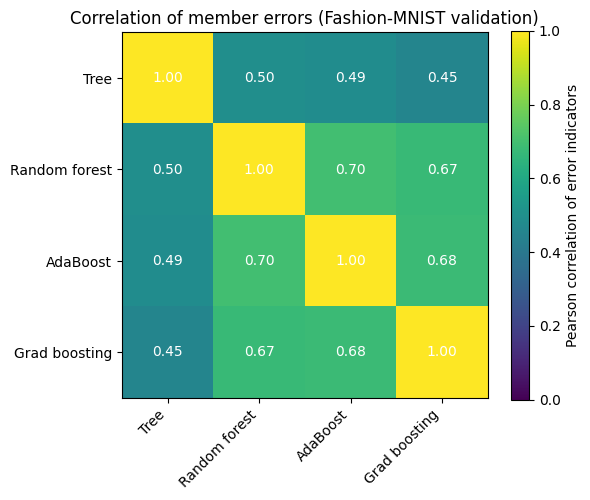

In [85]:
### Part 5.3 - Error correlation - Max
E = (P != yva).astype(float)                           # (4, n_val); 1 = member is wrong
corr = np.corrcoef(E)

print(pd.DataFrame(corr, index=names, columns=names).round(3))
off = corr[np.triu_indices(len(names), k=1)]
print('Mean pairwise error correlation: {:.3f}'.format(off.mean()))

nWrong = E.sum(axis=0)
print('All 4 members wrong      : {:.3f}'.format(np.mean(nWrong == 4)))
print('At least 1 member right  : {:.3f}  (oracle upper bound)'.format(np.mean(nWrong < 4)))
print('Wrong only for one member: {:.3f}'.format(np.mean(nWrong == 1)))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, '{:.2f}'.format(corr[i, j]), ha='center', va='center', color='white')
fig.colorbar(im, ax=ax, label='Pearson correlation of error indicators')
ax.set_title('Correlation of member errors (Fashion-MNIST validation)')
plt.tight_layout()
plt.savefig('part5_error_corr.png', dpi=150)
plt.show()

res.round(4).to_csv('part5_results.csv')

### PART 6

In [86]:
### function to get node count for ensemble - Joe
def getEnsembleNodes(ensemble):
    return sum(tree.tree_.node_count for tree in ensemble.estimators_)

In [87]:
### Part 6 - best tree classification (Gini) hyperparameters - Joe
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeGiniTestAccs = []
treeGiniF1s = []
treeGiniTrainTimes = []
treeGiniPredictTimes = []
treeGiniModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    giniTree = DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    giniTree.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    treeGiniTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = giniTree.predict(xtes[l])
    treeGiniTestAccs.append(accuracy_score(ytes[l], preds))
    treeGiniF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    treeGiniPredictTimes.append((end-st) * 1000000 / len(xtes[l]))
    treeGiniModelSizes.append(giniTree.tree_.node_count)
    print(treeGiniTestAccs)

0
[0.766]
1
[0.766, 0.7543]
2
[0.766, 0.7543, 0.774]
3
[0.766, 0.7543, 0.774, 0.7613]
4
[0.766, 0.7543, 0.774, 0.7613, 0.7598]


In [88]:
### Part 6 - best tree classification (Entropy) hyperparameters - Joe
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeEntropyTestAccs = []
treeEntropyF1s = []
treeEntropyTrainTimes = []
treeEntropyPredictTimes = []
treeEntropyModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    entropyTree = DecisionTreeClassifier(
        criterion="entropy",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    entropyTree.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    treeEntropyTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = entropyTree.predict(xtes[l])
    treeEntropyTestAccs.append(accuracy_score(ytes[l], preds))
    treeEntropyF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    treeEntropyPredictTimes.append((end-st) * 1000000 / len(xtes[l]))
    treeEntropyModelSizes.append(entropyTree.tree_.node_count)
    print(treeEntropyTestAccs)

0
[0.7716]
1
[0.7716, 0.7689]
2
[0.7716, 0.7689, 0.7687]
3
[0.7716, 0.7689, 0.7687, 0.7584]
4
[0.7716, 0.7689, 0.7687, 0.7584, 0.7686]


In [89]:
### Part 6 - best tree regression (RMSE) hyperparameters - Joe
treeRegRMSETestRmses = []
treeRegRMSETestMaes= []
treeRegRMSETrainTimes = []
treeRegRMSEPredictTimes = []
treeRegRMSEModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regRMSETree = DecisionTreeRegressor(
        criterion="squared_error",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    regRMSETree.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    treeRegRMSETrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regRMSETree.predict(regxtes[l])
    treeRegRMSETestRmses.append(root_mean_squared_error(regytes[l], preds))
    treeRegRMSETestMaes.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    treeRegRMSEPredictTimes.append((end-st) * 1000000 / len(regxtes[l]))
    treeRegRMSEModelSizes.append(regRMSETree.tree_.node_count)
    print(treeRegRMSETestRmses)

0
[0.6103784359013414]
1
[0.6103784359013414, 0.6423001068770358]
2
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597]
3
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597, 0.6171507200321468]
4
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597, 0.6171507200321468, 0.6315322841894897]


In [90]:
### Part 6 - best tree regression (RMSE) hyperparameters - Joe
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeRegMAETestRmses = []
treeRegMAETestMaes= []
treeRegMAETrainTimes = []
treeRegMAEPredictTimes = []
treeRegMAEModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regMAETree = DecisionTreeRegressor(
        criterion="absolute_error",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    regMAETree.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    treeRegMAETrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regMAETree.predict(regxtes[l])
    treeRegMAETestRmses.append(root_mean_squared_error(regytes[l], preds))
    treeRegMAETestMaes.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    treeRegMAEPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) #performance counter is for seconds, 1,000,000/ len(testdata) gives us ms/1k
    treeRegMAEModelSizes.append(regMAETree.tree_.node_count)
    print(treeRegMAETestRmses)

0
[0.6429203941023062]
1
[0.6429203941023062, 0.6392492419887662]
2
[0.6429203941023062, 0.6392492419887662, 0.6293343411889145]
3
[0.6429203941023062, 0.6392492419887662, 0.6293343411889145, 0.6380390651360275]
4
[0.6429203941023062, 0.6392492419887662, 0.6293343411889145, 0.6380390651360275, 0.647052211882518]


In [91]:
### Part 6 - best Pasting hyperparameters - Joe
pastingTestAccs = []
pastingF1s = []
pastingTrainTimes = []
pastingPredictTimes = []
pastingModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    pasting = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=300,
        max_samples=0.1,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    pasting.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    pastingTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = pasting.predict(xtes[l])
    pastingTestAccs.append(accuracy_score(ytes[l], preds))
    pastingF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    pastingPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    pastingModelSizes.append(getEnsembleNodes(pasting))
    print(pastingTestAccs)

0
[0.8239]
1
[0.8239, 0.8192]
2
[0.8239, 0.8192, 0.8206]
3
[0.8239, 0.8192, 0.8206, 0.8197]
4
[0.8239, 0.8192, 0.8206, 0.8197, 0.8201]


In [114]:
### Part 6 - best bagging hyperparameters - Joe
baggingTestAccs = []
baggingF1s = []
baggingTrainTimes = []
baggingPredictTimes = []
baggingModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=300,
        max_samples=1.0,
        max_features=0.1,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    bagging.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    baggingTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = bagging.predict(xtes[l])
    baggingTestAccs.append(accuracy_score(ytes[l], preds))
    baggingF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    baggingPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    baggingModelSizes.append(getEnsembleNodes(bagging))
    print(baggingTestAccs)

0
[0.8523]
1
[0.8523, 0.8519]
2
[0.8523, 0.8519, 0.8534]
3
[0.8523, 0.8519, 0.8534, 0.8552]
4
[0.8523, 0.8519, 0.8534, 0.8552, 0.8522]


In [93]:
### Part 6 - best pasting hyperparameters - regression - Joe
regPastingTestRMSEs = []
regPastingTestMAEs = []
regPastingTrainTimes = []
regPastingPredictTimes = []
regPastingModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regPasting = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=300,
        max_samples=0.1,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regPasting.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regPastingTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regPasting.predict(regxtes[l])
    regPastingTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regPastingTestMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regPastingPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regPastingModelSizes.append(getEnsembleNodes(regPasting))
    print(regPastingTestRMSEs)

0
[0.5625859626664274]
1
[0.5625859626664274, 0.5649310817548245]
2
[0.5625859626664274, 0.5649310817548245, 0.5466837768617089]
3
[0.5625859626664274, 0.5649310817548245, 0.5466837768617089, 0.5604347969811692]
4
[0.5625859626664274, 0.5649310817548245, 0.5466837768617089, 0.5604347969811692, 0.5532872488178395]


In [94]:
### Part 6 - best bagging hyperparameters - regression - Joe
regBaggingTestRMSEs = []
regBaggingTestMAEs = []
regBaggingTrainTimes = []
regBaggingPredictTimes = []
regBaggingModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regBagging = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=300,
        max_samples=1.0,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regBagging.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regBaggingTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regBagging.predict(regxtes[l])
    regBaggingTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regBaggingTestMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regBaggingPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regBaggingModelSizes.append(getEnsembleNodes(regBagging))
    print(regBaggingTestRMSEs)

0
[0.5135519929622802]
1
[0.5135519929622802, 0.5247910412856072]
2
[0.5135519929622802, 0.5247910412856072, 0.49755566957369735]
3
[0.5135519929622802, 0.5247910412856072, 0.49755566957369735, 0.5150075704983941]
4
[0.5135519929622802, 0.5247910412856072, 0.49755566957369735, 0.5150075704983941, 0.5028345753156175]


In [95]:
### Part 6 - best random subspaces hyperparameters - Joe
ranSubTestAccs = []
ranSubF1s = []
ranSubTrainTimes = []
ranSubPredictTimes = []
ranSubModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    ranSub = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=300,
        max_samples=1.0,
        max_features=0.1,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    ranSub.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    ranSubTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = ranSub.predict(xtes[l])
    ranSubTestAccs.append(accuracy_score(ytes[l], preds))
    ranSubF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    ranSubPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    ranSubModelSizes.append(getEnsembleNodes(ranSub))
    print(ranSubTestAccs)

0
[0.8578]
1
[0.8578, 0.8571]
2
[0.8578, 0.8571, 0.8576]
3
[0.8578, 0.8571, 0.8576, 0.8595]
4
[0.8578, 0.8571, 0.8576, 0.8595, 0.858]


In [96]:
### Part 6 - best random patches hyperparameters - Joe
ranPatchTestAccs = []
ranPatchF1s = []
ranPatchTrainTimes = []
ranPatchPredictTimes = []
ranPatchModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    ranPatch = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=300,
        max_samples=0.1,
        max_features=0.1,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    ranPatch.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    ranPatchTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = ranPatch.predict(xtes[l])
    ranPatchTestAccs.append(accuracy_score(ytes[l], preds))
    ranPatchF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    ranPatchPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    ranPatchModelSizes.append(getEnsembleNodes(ranPatch))
    print(ranPatchTestAccs)

0
[0.8238]
1
[0.8238, 0.8228]
2
[0.8238, 0.8228, 0.8223]
3
[0.8238, 0.8228, 0.8223, 0.8229]
4
[0.8238, 0.8228, 0.8223, 0.8229, 0.8268]


In [97]:
### Part 6 - best random subspaces hyperparameters - regression - Joe
regRanSubTestRMSEs = []
regRanSubMAEs = []
regRanSubTrainTimes = []
regRanSubPredictTimes = []
regRanSubModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regRanSub = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=300,
        max_samples=1.0,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regRanSub.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regRanSubTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regRanSub.predict(regxtes[l])
    regRanSubTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regRanSubMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regRanSubPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regRanSubModelSizes.append(getEnsembleNodes(regRanSub))
    print(regRanSubTestRMSEs)

0
[0.545441628420286]
1
[0.545441628420286, 0.5565582596284256]
2
[0.545441628420286, 0.5565582596284256, 0.5529936106178859]
3
[0.545441628420286, 0.5565582596284256, 0.5529936106178859, 0.5367620524784452]
4
[0.545441628420286, 0.5565582596284256, 0.5529936106178859, 0.5367620524784452, 0.547864058256195]


In [98]:
### Part 6 - best random patches hyperparameters - regression - Joe
regRanPatchTestRMSEs = []
regRanPatchMAEs = []
regRanPatchTrainTimes = []
regRanPatchPredictTimes = []
regRanPatchModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regRanPatch = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=300,
        max_samples=0.5,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regRanPatch.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regRanPatchTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regRanPatch.predict(regxtes[l])
    regRanPatchTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regRanPatchMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regRanPatchPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regRanPatchModelSizes.append(getEnsembleNodes(regRanPatch))
    print(regRanPatchTestRMSEs)

0
[0.5494606302293931]
1
[0.5494606302293931, 0.5568771007106639]
2
[0.5494606302293931, 0.5568771007106639, 0.5586024398712301]
3
[0.5494606302293931, 0.5568771007106639, 0.5586024398712301, 0.5426644712612099]
4
[0.5494606302293931, 0.5568771007106639, 0.5586024398712301, 0.5426644712612099, 0.5549682756759957]


In [99]:
### Part 6 - best ranForest hyperparameters - Joe
ranForestTestAccs = []
ranForestF1s = []
ranForestTrainTimes = []
ranForestPredictTimes = []
ranForestModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    ranForest = RandomForestClassifier(
        n_estimators=300,
        criterion='entropy',
        max_features=100,
        bootstrap=True,
        max_depth=None,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    ranForest.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    ranForestTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = ranForest.predict(xtes[l])
    ranForestTestAccs.append(accuracy_score(ytes[l], preds))
    ranForestF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    ranForestPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    ranForestModelSizes.append(getEnsembleNodes(ranForest))
    print(ranForestTestAccs)

0
[0.8582]
1
[0.8582, 0.8591]
2
[0.8582, 0.8591, 0.8555]
3
[0.8582, 0.8591, 0.8555, 0.8578]
4
[0.8582, 0.8591, 0.8555, 0.8578, 0.8568]


In [100]:
### Part 6 - best extra hyperparameters - Joe
extraTestAccs = []
extraF1s = []
extraTrainTimes = []
extraPredictTimes = []
extraModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    extra = ExtraTreesClassifier(
        n_estimators=300,
        criterion='entropy',
        max_features=100,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    extra.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    extraTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = extra.predict(xtes[l])
    extraTestAccs.append(accuracy_score(ytes[l], preds))
    extraF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    extraPredictTimes.append((end-st) * 1000000 / len(xtes[l])) 
    extraModelSizes.append(getEnsembleNodes(extra))
    print(extraTestAccs)

0
[0.858]
1
[0.858, 0.8605]
2
[0.858, 0.8605, 0.8576]
3
[0.858, 0.8605, 0.8576, 0.8588]
4
[0.858, 0.8605, 0.8576, 0.8588, 0.8589]


In [101]:
# Part 6 - best regRanForest hyperparameters - Joe
regRanForestTestRMSEs = []
regRanForestMAEs = []
regRanForestTrainTimes = []
regRanForestPredictTimes = []
regRanForestModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regRanForest = RandomForestRegressor(
        n_estimators=300,
        criterion='absolute_error',
        max_features=100,
        bootstrap=True,
        max_depth=None,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regRanForest.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regRanForestTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regRanForest.predict(regxtes[l])
    regRanForestTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regRanForestMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regRanForestPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regRanForestModelSizes.append(getEnsembleNodes(regRanForest))
    print(regRanForestTestRMSEs)

0
[0.508901841445135]
1
[0.508901841445135, 0.5169048408090909]
2
[0.508901841445135, 0.5169048408090909, 0.4918545335446201]
3
[0.508901841445135, 0.5169048408090909, 0.4918545335446201, 0.5080078039296823]
4
[0.508901841445135, 0.5169048408090909, 0.4918545335446201, 0.5080078039296823, 0.5015060749039689]


In [102]:
### Part 6 - best regExtra hyperparameters - Joe
regExtraTestRMSEs = []
regExtraMAEs = []
regExtraTrainTimes = []
regExtraPredictTimes = []
regExtraModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regExtra = ExtraTreesRegressor(
        n_estimators=300,
        criterion='absolute_error',
        max_features=100,
        bootstrap=True,
        max_depth=None,
        random_state=RANDOM_SEEDS[l],
        n_jobs=-1 # to compute faster
    )
    regExtra.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    regExtraTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regExtra.predict(regxtes[l])
    regExtraTestRMSEs.append(root_mean_squared_error(regytes[l], preds))
    regExtraMAEs.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    regExtraPredictTimes.append((end-st) * 1000000 / len(regxtes[l])) 
    regExtraModelSizes.append(getEnsembleNodes(regExtra))
    print(regExtraTestRMSEs)

0
[0.5111533987969038]
1
[0.5111533987969038, 0.517246159460347]
2
[0.5111533987969038, 0.517246159460347, 0.4977833298774118]
3
[0.5111533987969038, 0.517246159460347, 0.4977833298774118, 0.5027614315368271]
4
[0.5111533987969038, 0.517246159460347, 0.4977833298774118, 0.5027614315368271, 0.500108312770313]


In [103]:
### Part 6 - adaboost - classification - Joe
def runAda(l):
    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=bd,
            random_state=RANDOM_SEEDS[l]
        ),
        n_estimators=bestRound,
        learning_rate=blr,
        random_state=RANDOM_SEEDS[l]
    )

    st = time.perf_counter()
    model.fit(xtrs[l], ytrsI[l])
    end = time.perf_counter()
    trainTime = end - st

    st = time.perf_counter()
    preds = model.predict(xtes[l])
    testAcc = accuracy_score(ytesI[l], preds)
    f1 = f1_score(ytesI[l], preds, average="macro")
    end = time.perf_counter()

    predictTime = (end - st) * 1000000 / len(xtes[l])
    modelSize = sum(est.tree_.node_count for est in model.estimators_)

    return testAcc, f1, trainTime, predictTime, modelSize


# run in parallel
results = Parallel(n_jobs=-1)(
    delayed(runAda)(l) for l in range(len(RANDOM_SEEDS))
)

# compile
adaTestAccs = []
adaF1s = []
adaTrainTimes = []
adaPredictTimes = []
adaModelSizes = []

for result in results:
    adaTestAccs.append(result[0])
    adaF1s.append(result[1])
    adaTrainTimes.append(result[2])
    adaPredictTimes.append(result[3])
    adaModelSizes.append(result[4])

print(adaTestAccs)

[0.8632, 0.8624, 0.8604, 0.8653, 0.8549]


In [104]:
### Part 6 - HistGradientBoosting - classification - Joe
def runHgd(l):
    model = HistGradientBoostingClassifier(
        learning_rate=hgbBestKey[0],
        max_depth=hgbBestKey[1],
        max_leaf_nodes=None,
        max_iter=HGB_MAX_ITER,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        scoring='loss',
        random_state=RANDOM_SEEDS[l]
    )

    st = time.perf_counter()
    model.fit(xtrs[l], ytrsI[l])
    end = time.perf_counter()
    trainTime = end - st

    st = time.perf_counter()
    preds = model.predict(xtes[l])
    testAcc = accuracy_score(ytesI[l], preds)
    f1 = f1_score(ytesI[l], preds, average="macro")
    end = time.perf_counter()

    predictTime = (end - st) * 1000000 / len(xtes[l])
    modelSize = sum(
        len(predictor.nodes)
        for iteration in model._predictors
        for predictor in iteration
    )

    return testAcc, f1, trainTime, predictTime, modelSize


# run in parallel
results = Parallel(n_jobs=-1)(
    delayed(runHgd)(l) for l in range(len(RANDOM_SEEDS))
)

# compile
hgdTestAccs = []
hgdF1s = []
hgdTrainTimes = []
hgdPredictTimes = []
hgdModelSizes = []

for result in results:
    hgdTestAccs.append(result[0])
    hgdF1s.append(result[1])
    hgdTrainTimes.append(result[2])
    hgdPredictTimes.append(result[3])
    hgdModelSizes.append(result[4])

print(hgdTestAccs)

[0.8654, 0.8671, 0.8642, 0.865, 0.8623]


In [105]:
### Part 6 - gradient boosting - regression - Joe
def runGbr(l):
    model = GradientBoostingRegressor(
        learning_rate=gbrBestKey[0],
        max_depth=gbrBestKey[1],
        n_estimators=GBR_MAX_EST,
        validation_fraction=0.1,
        n_iter_no_change=20,
        tol=1e-4,
        random_state=RANDOM_SEEDS[l]
    )

    st = time.perf_counter()
    model.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    trainTime = end - st

    st = time.perf_counter()
    preds = model.predict(regxtes[l])
    testRMSE = root_mean_squared_error(regytes[l], preds)
    testMAE = mean_absolute_error(regytes[l], preds)
    end = time.perf_counter()

    predictTime = (end - st) * 1000000 / len(regxtes[l])
    modelSize = sum(
        tree.tree_.node_count for tree in model.estimators_.ravel()
    )

    return testRMSE, testMAE, trainTime, predictTime, modelSize


# run in parallel
results = Parallel(n_jobs=-1)(
    delayed(runGbr)(l) for l in range(len(RANDOM_SEEDS))
)

# compile
regGbrTestRMSEs = []
regGbrTestMAEs = []
regGbrTrainTimes = []
regGbrPredictTimes = []
regGbrModelSizes = []

for result in results:
    regGbrTestRMSEs.append(result[0])
    regGbrTestMAEs.append(result[1])
    regGbrTrainTimes.append(result[2])
    regGbrPredictTimes.append(result[3])
    regGbrModelSizes.append(result[4])

print(regGbrTestRMSEs)

[0.47310513018479766, 0.47303383287601475, 0.4514527772124015, 0.46134106399728253, 0.472566864140855]


In [106]:
### Part 6 - adaboost - regression - Joe
def runRegAda(l):
    model = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=adarBestKey[0],
            random_state=RANDOM_SEEDS[l]
        ),
        n_estimators=adarBestRound,
        learning_rate=adarBestKey[1],
        loss=adarBestKey[2],
        random_state=RANDOM_SEEDS[l]
    )

    st = time.perf_counter()
    model.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    trainTime = end - st

    st = time.perf_counter()
    preds = model.predict(regxtes[l])
    testRMSE = root_mean_squared_error(regytes[l], preds)
    testMAE = mean_absolute_error(regytes[l], preds)
    end = time.perf_counter()

    predictTime = (end - st) * 1000000 / len(regxtes[l])
    modelSize = sum(
        est.tree_.node_count for est in model.estimators_
    )

    return testRMSE, testMAE, trainTime, predictTime, modelSize


# run in parallel
results = Parallel(n_jobs=-1)(
    delayed(runRegAda)(l) for l in range(len(RANDOM_SEEDS))
)

# compile
regAdaTestRMSEs = []
regAdaTestMAEs = []
regAdaTrainTimes = []
regAdaPredictTimes = []
regAdaModelSizes = []

for result in results:
    regAdaTestRMSEs.append(result[0])
    regAdaTestMAEs.append(result[1])
    regAdaTrainTimes.append(result[2])
    regAdaPredictTimes.append(result[3])
    regAdaModelSizes.append(result[4])

print(regAdaTestRMSEs)

[0.5417108571094991, 0.5508704034635865, 0.5323585111604006, 0.551604162780161, 0.5498128484460726]


In [124]:
### Part 6 - voting and stacking - classification - Joe
# Parallelize over seeds
# Fit base models on training - fit LogReg on validation probabilities, reusing part 5

#saving stackPreds for confusion matrix later
stackPreds = None
def runVotingStacking(l):
    seed = RANDOM_SEEDS[l]
    members = {
        'Tree': DecisionTreeClassifier(criterion='gini', ccp_alpha=0.0006,
                                       min_samples_leaf=20, random_state=seed),
        'Random forest': RandomForestClassifier(**RF_PARAMS, random_state=seed, n_jobs=1),
        'AdaBoost': AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=bd, random_state=seed),
            n_estimators=bestRound, learning_rate=blr, random_state=seed
        ),
        'Grad boosting': HistGradientBoostingClassifier(
            learning_rate=hgbBestKey[0], max_depth=hgbBestKey[1],
            max_leaf_nodes=None, max_iter=HGB_MAX_ITER,
            early_stopping=True, validation_fraction=0.1,
            n_iter_no_change=20, scoring='loss', random_state=seed
        )
    }

    st = time.perf_counter()
    for model in members.values():
        model.fit(xtrs[l], ytrsI[l])
    baseTrainTime = time.perf_counter() - st

    st = time.perf_counter()
    Zval = np.hstack([model.predict_proba(xvals[l]) for model in members.values()])
    meta = LogisticRegression(max_iter=2000)
    meta.fit(Zval, yvalsI[l])
    stackTrainTime = baseTrainTime + time.perf_counter() - st

    # Test probabilities computed once and reused across all three ensembles
    st = time.perf_counter()
    testProbabilities = [model.predict_proba(xtes[l]) for model in members.values()]
    basePredictTime = time.perf_counter() - st

    st = time.perf_counter()
    P = np.stack([p.argmax(axis=1) for p in testProbabilities])
    hardPreds = np.array([
        np.bincount(P[:, j], minlength=NUM_CLASSES).argmax() for j in range(P.shape[1])
    ])
    hardPredictTime = basePredictTime + time.perf_counter() - st

    st = time.perf_counter()
    softPreds = np.mean(testProbabilities, axis=0).argmax(axis=1)
    softPredictTime = basePredictTime + time.perf_counter() - st

    st = time.perf_counter()
    Ztest = np.hstack(testProbabilities)
    stackPreds = meta.predict(Ztest)
    stackPredictTime = basePredictTime + time.perf_counter() - st

    modelNodes = (
        members['Tree'].tree_.node_count
        + sum(tree.tree_.node_count for tree in members['Random forest'].estimators_)
        + sum(tree.tree_.node_count for tree in members['AdaBoost'].estimators_)
        + sum(len(predictor.nodes) for iteration in members['Grad boosting']._predictors
              for predictor in iteration)
    )
    scale = 1000000/len(xtes[l])  # 1k/ms
    return (
        (accuracy_score(ytesI[l], hardPreds), f1_score(ytesI[l], hardPreds, average='macro'),
         baseTrainTime, hardPredictTime * scale, modelNodes),
        (accuracy_score(ytesI[l], softPreds), f1_score(ytesI[l], softPreds, average='macro'),
         baseTrainTime, softPredictTime * scale, modelNodes),
        (accuracy_score(ytesI[l], stackPreds), f1_score(ytesI[l], stackPreds, average='macro'),
         stackTrainTime, stackPredictTime * scale, modelNodes)
    )

# parallelize
results = Parallel(n_jobs=-1, verbose=5)(
    delayed(runVotingStacking)(l) for l in range(len(RANDOM_SEEDS))
)

hardVotingTestAccs, hardVotingF1s, hardVotingTrainTimes, hardVotingPredictTimes, hardVotingModelSizes = [], [], [], [], []
softVotingTestAccs, softVotingF1s, softVotingTrainTimes, softVotingPredictTimes, softVotingModelSizes = [], [], [], [], []
stackingTestAccs, stackingF1s, stackingTrainTimes, stackingPredictTimes, stackingModelSizes = [], [], [], [], []

for hard, soft, stack in results:
    hardVotingTestAccs.append(hard[0]); hardVotingF1s.append(hard[1]); hardVotingTrainTimes.append(hard[2])
    hardVotingPredictTimes.append(hard[3]); hardVotingModelSizes.append(hard[4])
    softVotingTestAccs.append(soft[0]); softVotingF1s.append(soft[1]); softVotingTrainTimes.append(soft[2])
    softVotingPredictTimes.append(soft[3]); softVotingModelSizes.append(soft[4])
    stackingTestAccs.append(stack[0]); stackingF1s.append(stack[1]); stackingTrainTimes.append(stack[2])
    stackingPredictTimes.append(stack[3]); stackingModelSizes.append(stack[4])

print(hardVotingTestAccs, softVotingTestAccs, stackingTestAccs)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed: 11.7min remaining: 17.5min


[0.8645, 0.863, 0.8624, 0.8628, 0.863] [0.8583, 0.8551, 0.8577, 0.8578, 0.8554] [0.8673, 0.8669, 0.867, 0.8671, 0.8652]


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed: 11.8min finished


In [108]:
### Part 6 - voting and stacking - regression - Joe
from sklearn.linear_model import Ridge

def runRegVotingStacking(l):
    seed = RANDOM_SEEDS[l]
    members = {
        'Tree': DecisionTreeRegressor(
            criterion='squared_error', ccp_alpha=0.0006,
            min_samples_leaf=20, max_depth=None, random_state=seed
        ),
        'Random forest': RandomForestRegressor(
            n_estimators=300, criterion='absolute_error',
            max_features=min(100, regxtrs[l].shape[1]), bootstrap=True,
            max_depth=None, random_state=seed, n_jobs=1
        ),
        'AdaBoost': AdaBoostRegressor(
            estimator=DecisionTreeRegressor(max_depth=adarBestKey[0], random_state=seed),
            n_estimators=adarBestRound, learning_rate=adarBestKey[1],
            loss=adarBestKey[2], random_state=seed
        ),
        'Grad boosting': GradientBoostingRegressor(
            learning_rate=gbrBestKey[0], max_depth=gbrBestKey[1],
            n_estimators=GBR_MAX_EST, validation_fraction=0.1,
            n_iter_no_change=20, tol=1e-4, random_state=seed
        )
    }

    st = time.perf_counter()
    for model in members.values():
        model.fit(regxtrs[l], regytrs[l])
    baseTrainTime = time.perf_counter() - st

    # holdout stacking
    st = time.perf_counter()
    Zval = np.column_stack([model.predict(regxvals[l]) for model in members.values()])
    meta = Ridge(alpha=1.0)
    meta.fit(Zval, regyvals[l])
    stackTrainTime = baseTrainTime + time.perf_counter() - st

    # include each model's pred time
    st = time.perf_counter()
    Ztest = np.column_stack([model.predict(regxtes[l]) for model in members.values()])
    basePredictTime = time.perf_counter() - st

    st = time.perf_counter()
    votePreds = Ztest.mean(axis=1)
    votePredictTime = basePredictTime + time.perf_counter() - st

    st = time.perf_counter()
    stackPreds = meta.predict(Ztest)
    stackPredictTime = basePredictTime + time.perf_counter() - st

    # model sizes sums predictor size
    modelNodes = (
        members['Tree'].tree_.node_count
        + sum(tree.tree_.node_count for tree in members['Random forest'].estimators_)
        + sum(tree.tree_.node_count for tree in members['AdaBoost'].estimators_)
        + sum(tree.tree_.node_count for tree in members['Grad boosting'].estimators_.ravel())
    )
    scale = 1000000 / len(regxtes[l])  # 1k/ms
    return (
        (root_mean_squared_error(regytes[l], votePreds),
         mean_absolute_error(regytes[l], votePreds),
         baseTrainTime, votePredictTime * scale, modelNodes),
        (root_mean_squared_error(regytes[l], stackPreds),
         mean_absolute_error(regytes[l], stackPreds),
         stackTrainTime, stackPredictTime * scale, modelNodes)
    )

results = Parallel(n_jobs=-1, verbose=5)(
    delayed(runRegVotingStacking)(l) for l in range(len(RANDOM_SEEDS))
)

regVotingTestRMSEs, regVotingTestMAEs, regVotingTrainTimes, regVotingPredictTimes, regVotingModelSizes = [], [], [], [], []
regStackingTestRMSEs, regStackingTestMAEs, regStackingTrainTimes, regStackingPredictTimes, regStackingModelSizes = [], [], [], [], []

for vote, stack in results:
    regVotingTestRMSEs.append(vote[0]); regVotingTestMAEs.append(vote[1]); regVotingTrainTimes.append(vote[2])
    regVotingPredictTimes.append(vote[3]); regVotingModelSizes.append(vote[4])
    regStackingTestRMSEs.append(stack[0]); regStackingTestMAEs.append(stack[1]); regStackingTrainTimes.append(stack[2])
    regStackingPredictTimes.append(stack[3]); regStackingModelSizes.append(stack[4])

print(regVotingTestRMSEs, regStackingTestRMSEs)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed: 12.1min remaining: 18.2min


[0.500185727746135, 0.5110271291203604, 0.4873348510872121, 0.49783664118592363, 0.5022767752248218] [0.47211331813042, 0.4713652034696592, 0.4473084358811598, 0.46052892722417443, 0.4677873276535375]


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed: 12.4min finished


In [115]:
### Part 6 compile results - classification - Joe
treeGiniTestAccStats = (np.mean(treeGiniTestAccs), np.std(treeGiniTestAccs))
treeGiniF1Stats = (np.mean(treeGiniF1s), np.std(treeGiniF1s))
treeGiniTrainTimeStats = (np.mean(treeGiniTrainTimes), np.std(treeGiniTrainTimes))
treeGiniPredictTimeStats = (np.mean(treeGiniPredictTimes), np.std(treeGiniPredictTimes))
treeGiniModelSizeStats = (np.mean(treeGiniModelSizes), np.std(treeGiniModelSizes))

treeEntropyTestAccStats = (np.mean(treeEntropyTestAccs), np.std(treeEntropyTestAccs))
treeEntropyF1Stats = (np.mean(treeEntropyF1s), np.std(treeEntropyF1s))
treeEntropyTrainTimeStats = (np.mean(treeEntropyTrainTimes), np.std(treeEntropyTrainTimes))
treeEntropyPredictTimeStats = (np.mean(treeEntropyPredictTimes), np.std(treeEntropyPredictTimes))
treeEntropyModelSizeStats = (np.mean(treeEntropyModelSizes), np.std(treeEntropyModelSizes))

pastingTestAccStats = (np.mean(pastingTestAccs), np.std(pastingTestAccs))
pastingF1Stats = (np.mean(pastingF1s), np.std(pastingF1s))
pastingTrainTimeStats = (np.mean(pastingTrainTimes), np.std(pastingTrainTimes))
pastingPredictTimeStats = (np.mean(pastingPredictTimes), np.std(pastingPredictTimes))
pastingModelSizeStats = (np.mean(pastingModelSizes), np.std(pastingModelSizes))

baggingTestAccStats = (np.mean(baggingTestAccs), np.std(baggingTestAccs))
baggingF1Stats = (np.mean(baggingF1s), np.std(baggingF1s))
baggingTrainTimeStats = (np.mean(baggingTrainTimes), np.std(baggingTrainTimes))
baggingPredictTimeStats = (np.mean(baggingPredictTimes), np.std(baggingPredictTimes))
baggingModelSizeStats = (np.mean(baggingModelSizes), np.std(baggingModelSizes))

ranSubTestAccStats = (np.mean(ranSubTestAccs), np.std(ranSubTestAccs))
ranSubF1Stats = (np.mean(ranSubF1s), np.std(ranSubF1s))
ranSubTrainTimeStats = (np.mean(ranSubTrainTimes), np.std(ranSubTrainTimes))
ranSubPredictTimeStats = (np.mean(ranSubPredictTimes), np.std(ranSubPredictTimes))
ranSubModelSizeStats = (np.mean(ranSubModelSizes), np.std(ranSubModelSizes))

ranPatchTestAccStats = (np.mean(ranPatchTestAccs), np.std(ranPatchTestAccs))
ranPatchF1Stats = (np.mean(ranPatchF1s), np.std(ranPatchF1s))
ranPatchTrainTimeStats = (np.mean(ranPatchTrainTimes), np.std(ranPatchTrainTimes))
ranPatchPredictTimeStats = (np.mean(ranPatchPredictTimes), np.std(ranPatchPredictTimes))
ranPatchModelSizeStats = (np.mean(ranPatchModelSizes), np.std(ranPatchModelSizes))

ranForestTestAccStats = (np.mean(ranForestTestAccs), np.std(ranForestTestAccs))
ranForestF1Stats = (np.mean(ranForestF1s), np.std(ranForestF1s))
ranForestTrainTimeStats = (np.mean(ranForestTrainTimes), np.std(ranForestTrainTimes))
ranForestPredictTimeStats = (np.mean(ranForestPredictTimes), np.std(ranForestPredictTimes))
ranForestModelSizeStats = (np.mean(ranForestModelSizes), np.std(ranForestModelSizes))

extraTestAccStats = (np.mean(extraTestAccs), np.std(extraTestAccs))
extraF1Stats = (np.mean(extraF1s), np.std(extraF1s))
extraTrainTimeStats = (np.mean(extraTrainTimes), np.std(extraTrainTimes))
extraPredictTimeStats = (np.mean(extraPredictTimes), np.std(extraPredictTimes))
extraModelSizeStats = (np.mean(extraModelSizes), np.std(extraModelSizes))

adaTestAccStats = (np.mean(adaTestAccs), np.std(adaTestAccs))
adaF1Stats = (np.mean(adaF1s), np.std(adaF1s))
adaTrainTimeStats = (np.mean(adaTrainTimes), np.std(adaTrainTimes))
adaPredictTimeStats = (np.mean(adaPredictTimes), np.std(adaPredictTimes))
adaModelSizeStats = (np.mean(adaModelSizes), np.std(adaModelSizes))

hgdTestAccStats = (np.mean(hgdTestAccs), np.std(hgdTestAccs))
hgdF1Stats = (np.mean(hgdF1s), np.std(hgdF1s))
hgdTrainTimeStats = (np.mean(hgdTrainTimes), np.std(hgdTrainTimes))
hgdPredictTimeStats = (np.mean(hgdPredictTimes), np.std(hgdPredictTimes))
hgdModelSizeStats = (np.mean(hgdModelSizes), np.std(hgdModelSizes))

hardVotingTestAccStats = (np.mean(hardVotingTestAccs), np.std(hardVotingTestAccs))
hardVotingF1Stats = (np.mean(hardVotingF1s), np.std(hardVotingF1s))
hardVotingTrainTimeStats = (np.mean(hardVotingTrainTimes), np.std(hardVotingTrainTimes))
hardVotingPredictTimeStats = (np.mean(hardVotingPredictTimes), np.std(hardVotingPredictTimes))
hardVotingModelSizeStats = (np.mean(hardVotingModelSizes), np.std(hardVotingModelSizes))

softVotingTestAccStats = (np.mean(softVotingTestAccs), np.std(softVotingTestAccs))
softVotingF1Stats = (np.mean(softVotingF1s), np.std(softVotingF1s))
softVotingTrainTimeStats = (np.mean(softVotingTrainTimes), np.std(softVotingTrainTimes))
softVotingPredictTimeStats = (np.mean(softVotingPredictTimes), np.std(softVotingPredictTimes))
softVotingModelSizeStats = (np.mean(softVotingModelSizes), np.std(softVotingModelSizes))

stackingTestAccStats = (np.mean(stackingTestAccs), np.std(stackingTestAccs))
stackingF1Stats = (np.mean(stackingF1s), np.std(stackingF1s))
stackingTrainTimeStats = (np.mean(stackingTrainTimes), np.std(stackingTrainTimes))
stackingPredictTimeStats = (np.mean(stackingPredictTimes), np.std(stackingPredictTimes))
stackingModelSizeStats = (np.mean(stackingModelSizes), np.std(stackingModelSizes))

In [116]:
### Part 6 helper function for output - Joe
def combineMean_Std(vals):
    return "{:.3f} ± {:.3f} ".format(vals[0], vals[1])

In [117]:
### Part 6 create a table for classification results - JOe
methods = ["Tree (Gini)", "Tree (Entropy)", "Pasting", "Bagging", "Random Subspaces", "Random Patches", "Random Forest","Extra Trees", "AdaBoost", "Gradient Boosting", "Hard voting", "Soft voting", "Stacking (LogReg)"]

bestHyperparameters = [
    "ccp_alpha=0.0006, min_samples_leaf=20, max_depth=None",
    "ccp_alpha=0.0006, min_samples_leaf=20, max_depth=None",
    "n_estimators=300, max_samples=0.1, max_features=1.0, bootstrap=False",
    "n_estimators=300, max_samples=1.0, max_features=0.1, bootstrap=False",
    "n_estimators=300, max_samples=1.0, max_features=0.1, bootstrap=False",
    "n_estimators=300, max_samples=0.1, max_features=0.1, bootstrap=False",
    "n_estimators=300, criterion=entropy, max_features=100, bootstrap=True",
    "n_estimators=300, criterion=entropy, max_features=100",
    "max_depth=8, n_estimators=339, learning_rate=0.1",
    "max_depth=4, max_iter=500, learning_rate=0.1, early_stopping=True",
    "4 Part 5 members, hard voting",
    "4 Part 5 members, soft voting",
    "4 Part 5 members + LogReg(max_iter=2000)"
]

testAccuracies = [
    combineMean_Std(treeGiniTestAccStats), 
    combineMean_Std(treeEntropyTestAccStats), 
    combineMean_Std(pastingTestAccStats), 
    combineMean_Std(baggingTestAccStats), 
    combineMean_Std(ranSubTestAccStats),
    combineMean_Std(ranPatchTestAccStats), 
    combineMean_Std(ranForestTestAccStats), 
    combineMean_Std(extraTestAccStats),
    combineMean_Std(adaTestAccStats),
    combineMean_Std(hgdTestAccStats),
    combineMean_Std(hardVotingTestAccStats),
    combineMean_Std(softVotingTestAccStats),
    combineMean_Std(stackingTestAccStats)
]
macroF1s = [
    combineMean_Std(treeGiniF1Stats), 
    combineMean_Std(treeEntropyF1Stats), 
    combineMean_Std(pastingF1Stats), 
    combineMean_Std(baggingF1Stats), 
    combineMean_Std(ranSubF1Stats),
    combineMean_Std(ranPatchF1Stats), 
    combineMean_Std(ranForestF1Stats), 
    combineMean_Std(extraF1Stats),
    combineMean_Std(adaF1Stats),
    combineMean_Std(hgdF1Stats),
    combineMean_Std(hardVotingF1Stats),
    combineMean_Std(softVotingF1Stats),
    combineMean_Std(stackingF1Stats)
]
trainTimes = [
    combineMean_Std(treeGiniTrainTimeStats), 
    combineMean_Std(treeEntropyTrainTimeStats), 
    combineMean_Std(pastingTrainTimeStats), 
    combineMean_Std(baggingTrainTimeStats), 
    combineMean_Std(ranSubTrainTimeStats),
    combineMean_Std(ranPatchTrainTimeStats), 
    combineMean_Std(ranForestTrainTimeStats), 
    combineMean_Std(extraTrainTimeStats),
    combineMean_Std(adaTrainTimeStats),
    combineMean_Std(hgdTrainTimeStats),
    combineMean_Std(hardVotingTrainTimeStats),
    combineMean_Std(softVotingTrainTimeStats),
    combineMean_Std(stackingTrainTimeStats)
]
predictTimes = [
    combineMean_Std(treeGiniPredictTimeStats), 
    combineMean_Std(treeEntropyPredictTimeStats), 
    combineMean_Std(pastingPredictTimeStats), 
    combineMean_Std(baggingPredictTimeStats), 
    combineMean_Std(ranSubPredictTimeStats),
    combineMean_Std(ranPatchPredictTimeStats), 
    combineMean_Std(ranForestPredictTimeStats), 
    combineMean_Std(extraPredictTimeStats),
    combineMean_Std(adaPredictTimeStats),
    combineMean_Std(hgdPredictTimeStats),
    combineMean_Std(hardVotingPredictTimeStats),
    combineMean_Std(softVotingPredictTimeStats),
    combineMean_Std(stackingPredictTimeStats)
]
modelSizes = [
    combineMean_Std(treeGiniModelSizeStats), 
    combineMean_Std(treeEntropyModelSizeStats), 
    combineMean_Std(pastingModelSizeStats), 
    combineMean_Std(baggingModelSizeStats), 
    combineMean_Std(ranSubModelSizeStats),
    combineMean_Std(ranPatchModelSizeStats), 
    combineMean_Std(ranForestModelSizeStats), 
    combineMean_Std(extraModelSizeStats),
    combineMean_Std(adaModelSizeStats),
    combineMean_Std(hgdModelSizeStats),
    combineMean_Std(hardVotingModelSizeStats),
    combineMean_Std(softVotingModelSizeStats),
    combineMean_Std(stackingModelSizeStats)
]
table = pd.DataFrame({
    'Method': methods,
    'Best Hyperparameters' : bestHyperparameters,
    'Test Accuracy (%)': testAccuracies,
    'Macro-F1': macroF1s,
    'Train Time(s)': trainTimes,
    'Predict Time (ms / 1k images)': predictTimes,
    'Model Size (nodes)': modelSizes
})
fig, ax = plt.subplots(figsize=(30,30))
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(120)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\2763758840.py:110: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


In [118]:
### Part 6 compile results - regression - Joe
treeRegRMSETestRMSEStats = (np.mean(treeRegRMSETestRmses), np.std(treeRegRMSETestRmses))
treeRegRMSETestMAEStats = (np.mean(treeRegRMSETestMaes), np.std(treeRegRMSETestMaes))
treeRegRMSETrainTimeStats = (np.mean(treeRegRMSETrainTimes), np.std(treeRegRMSETrainTimes))
treeRegRMSEPredictTimeStats = (np.mean(treeRegRMSEPredictTimes), np.std(treeRegRMSEPredictTimes))
treeRegRMSEModelSizeStats = (np.mean(treeRegRMSEModelSizes), np.std(treeRegRMSEModelSizes))

treeRegMAETestRMSEStats = (np.mean(treeRegMAETestRmses), np.std(treeRegMAETestRmses))
treeRegMAETestMAEStats = (np.mean(treeRegMAETestMaes), np.std(treeRegMAETestMaes))
treeRegMAETrainTimeStats = (np.mean(treeRegMAETrainTimes), np.std(treeRegMAETrainTimes))
treeRegMAEPredictTimeStats = (np.mean(treeRegMAEPredictTimes), np.std(treeRegMAEPredictTimes))
treeRegMAEModelSizeStats = (np.mean(treeRegMAEModelSizes), np.std(treeRegMAEModelSizes))

regPastingTestRMSEStats = (np.mean(regPastingTestRMSEs), np.std(regPastingTestRMSEs))
regPastingTestMAEStats= (np.mean(regPastingTestMAEs), np.std(regPastingTestMAEs))
regPastingTrainTimeStats = (np.mean(regPastingTrainTimes), np.std(regPastingTrainTimes))
regPastingPredictTimeStats = (np.mean(regPastingPredictTimes), np.std(regPastingPredictTimes))
regPastingModelSizeStats = (np.mean(regPastingModelSizes), np.std(regPastingModelSizes))

regBaggingTestRMSEStats = (np.mean(regBaggingTestRMSEs), np.std(regBaggingTestRMSEs))
regBaggingTestMAEStats = (np.mean(regBaggingTestMAEs), np.std(regBaggingTestMAEs))
regBaggingTrainTimeStats = (np.mean(regBaggingTrainTimes), np.std(regBaggingTrainTimes))
regBaggingPredictTimeStats = (np.mean(regBaggingPredictTimes), np.std(regBaggingPredictTimes))
regBaggingModelSizeStats = (np.mean(regBaggingModelSizes), np.std(regBaggingModelSizes))

regRanSubTestRMSEStats = (np.mean(regRanSubTestRMSEs), np.std(regRanSubTestRMSEs))
regRanSubTestMAEStats = (np.mean(regRanSubMAEs), np.std(regRanSubMAEs))
regRanSubTrainTimeStats = (np.mean(regRanSubTrainTimes), np.std(regRanSubTrainTimes))
regRanSubPredictTimeStats = (np.mean(regRanSubPredictTimes), np.std(regRanSubPredictTimes))
regRanSubModelSizeStats = (np.mean(regRanSubModelSizes), np.std(regRanSubModelSizes))

regRanPatchTestRMSEStats = (np.mean(regRanPatchTestRMSEs), np.std(regRanPatchTestRMSEs))
regRanPatchTestMAEStats = (np.mean(regRanPatchMAEs), np.std(regRanPatchMAEs))
regRanPatchTrainTimeStats = (np.mean(regRanPatchTrainTimes), np.std(regRanPatchTrainTimes))
regRanPatchPredictTimeStats = (np.mean(regRanPatchPredictTimes), np.std(regRanPatchPredictTimes))
regRanPatchModelSizeStats = (np.mean(regRanPatchModelSizes), np.std(regRanPatchModelSizes))

regRanForestTestRMSEStats = (np.mean(regRanForestTestRMSEs), np.std(regRanForestTestRMSEs))
regRanForestTestMAEStats = (np.mean(regRanForestMAEs), np.std(regRanForestMAEs))
regRanForestTrainTimeStats = (np.mean(regRanForestTrainTimes), np.std(regRanForestTrainTimes))
regRanForestPredictTimeStats = (np.mean(regRanForestPredictTimes), np.std(regRanForestPredictTimes))
regRanForestModelSizeStats = (np.mean(regRanForestModelSizes), np.std(regRanForestModelSizes))

regExtraTestRMSEStats = (np.mean(regExtraTestRMSEs), np.std(regExtraTestRMSEs))
regExtraTestMAEStats = (np.mean(regExtraMAEs), np.std(regExtraMAEs))
regExtraTrainTimeStats = (np.mean(regExtraTrainTimes), np.std(regExtraTrainTimes))
regExtraPredictTimeStats = (np.mean(regExtraPredictTimes), np.std(regExtraPredictTimes))
regExtraModelSizeStats = (np.mean(regExtraModelSizes), np.std(regExtraModelSizes))

regGbrTestRMSEStats = (np.mean(regGbrTestRMSEs), np.std(regGbrTestRMSEs))
regGbrTestMAEStats = (np.mean(regGbrTestMAEs), np.std(regGbrTestMAEs))
regGbrTrainTimeStats = (np.mean(regGbrTrainTimes), np.std(regGbrTrainTimes))
regGbrPredictTimeStats = (np.mean(regGbrPredictTimes), np.std(regGbrPredictTimes))
regGbrModelSizeStats = (np.mean(regGbrModelSizes), np.std(regGbrModelSizes))

regAdaTestRMSEStats = (np.mean(regAdaTestRMSEs), np.std(regAdaTestRMSEs))
regAdaTestMAEStats = (np.mean(regAdaTestMAEs), np.std(regAdaTestMAEs))
regAdaTrainTimeStats = (np.mean(regAdaTrainTimes), np.std(regAdaTrainTimes))
regAdaPredictTimeStats = (np.mean(regAdaPredictTimes), np.std(regAdaPredictTimes))
regAdaModelSizeStats = (np.mean(regAdaModelSizes), np.std(regAdaModelSizes))

regVotingTestRMSEStats = (np.mean(regVotingTestRMSEs), np.std(regVotingTestRMSEs))
regVotingTestMAEStats = (np.mean(regVotingTestMAEs), np.std(regVotingTestMAEs))
regVotingTrainTimeStats = (np.mean(regVotingTrainTimes), np.std(regVotingTrainTimes))
regVotingPredictTimeStats = (np.mean(regVotingPredictTimes), np.std(regVotingPredictTimes))
regVotingModelSizeStats = (np.mean(regVotingModelSizes), np.std(regVotingModelSizes))

regStackingTestRMSEStats = (np.mean(regStackingTestRMSEs), np.std(regStackingTestRMSEs))
regStackingTestMAEStats = (np.mean(regStackingTestMAEs), np.std(regStackingTestMAEs))
regStackingTrainTimeStats = (np.mean(regStackingTrainTimes), np.std(regStackingTrainTimes))
regStackingPredictTimeStats = (np.mean(regStackingPredictTimes), np.std(regStackingPredictTimes))
regStackingModelSizeStats = (np.mean(regStackingModelSizes), np.std(regStackingModelSizes))

In [ ]:
### Part 6 create a table for regression results - Joe
regMethods = ["Tree (RMSE)", "Tree (MAE)", "Pasting", "Bagging", "Random Subspaces",
              "Random Patches", "Random Forest", "Extra Trees", "AdaBoost", "Gradient Boosting",
              "Mean voting", "Stacking (Ridge)"]
regBestHyperparameters = [
    "criterion=squared_error, ccp_alpha=0.0006, min_samples_leaf=20",
    "criterion=absolute_error, ccp_alpha=0.0006, min_samples_leaf=20",
    "n_estimators=300, max_samples=0.1, max_features=1.0, bootstrap=False",
    "n_estimators=300, max_samples=1.0, max_features=1.0, bootstrap=True",
    "n_estimators=300, max_samples=1.0, max_features=0.5, bootstrap=False",
    "n_estimators=300, max_samples=0.5, max_features=0.5, bootstrap=False",
    "n_estimators=300, criterion=absolute_error, max_features=all available (8), bootstrap=True",
    "n_estimators=300, criterion=absolute_error, max_features=all available (8), bootstrap=True",
    f"depth={adarBestKey[0]}, rounds={adarBestRound}, lr={adarBestKey[1]}, loss={adarBestKey[2]}",
    f"depth={gbrBestKey[1]}, n_estimators={GBR_MAX_EST}, lr={gbrBestKey[0]}, early-stopping",
    "4 regression members, mean predictions",
    "4 regression members + Ridge where alpha=1.0"
]
regTestRMSEAccuracies = [
    combineMean_Std(treeRegRMSETestRMSEStats), 
    combineMean_Std(treeRegMAETestRMSEStats), 
    combineMean_Std(regPastingTestRMSEStats), 
    combineMean_Std(regBaggingTestRMSEStats), 
    combineMean_Std(regRanSubTestRMSEStats),
    combineMean_Std(regRanPatchTestRMSEStats), 
    combineMean_Std(regRanForestTestRMSEStats), 
    combineMean_Std(regExtraTestRMSEStats),
    combineMean_Std(regAdaTestRMSEStats),
    combineMean_Std(regGbrTestRMSEStats),
    combineMean_Std(regVotingTestRMSEStats),
    combineMean_Std(regStackingTestRMSEStats)
]
regTestMAEAccuracies = [
    combineMean_Std(treeRegRMSETestMAEStats), 
    combineMean_Std(treeRegMAETestMAEStats), 
    combineMean_Std(regPastingTestMAEStats), 
    combineMean_Std(regBaggingTestMAEStats), 
    combineMean_Std(regRanSubTestMAEStats),
    combineMean_Std(regRanPatchTestMAEStats), 
    combineMean_Std(regRanForestTestMAEStats), 
    combineMean_Std(regExtraTestMAEStats),
    combineMean_Std(regAdaTestMAEStats),
    combineMean_Std(regGbrTestMAEStats),
    combineMean_Std(regVotingTestMAEStats),
    combineMean_Std(regStackingTestMAEStats)
]
regTrainTimes = [
    combineMean_Std(treeRegRMSETrainTimeStats), 
    combineMean_Std(treeRegMAETrainTimeStats), 
    combineMean_Std(regPastingTrainTimeStats), 
    combineMean_Std(regBaggingTrainTimeStats), 
    combineMean_Std(regRanSubTrainTimeStats),
    combineMean_Std(regRanPatchTrainTimeStats), 
    combineMean_Std(regRanForestTrainTimeStats), 
    combineMean_Std(regExtraTrainTimeStats),
    combineMean_Std(regAdaTrainTimeStats),
    combineMean_Std(regGbrTrainTimeStats),
    combineMean_Std(regVotingTrainTimeStats),
    combineMean_Std(regStackingTrainTimeStats)
]
regPredictTimes = [
    combineMean_Std(treeRegRMSEPredictTimeStats), 
    combineMean_Std(treeRegMAEPredictTimeStats), 
    combineMean_Std(regPastingPredictTimeStats), 
    combineMean_Std(regBaggingPredictTimeStats), 
    combineMean_Std(regRanSubPredictTimeStats),
    combineMean_Std(regRanPatchPredictTimeStats), 
    combineMean_Std(regRanForestPredictTimeStats), 
    combineMean_Std(regExtraPredictTimeStats),
    combineMean_Std(regAdaPredictTimeStats),
    combineMean_Std(regGbrModelSizeStats),
    combineMean_Std(regVotingModelSizeStats),
    combineMean_Std(regStackingModelSizeStats)
]
regModelSizes = [
    combineMean_Std(treeRegRMSEModelSizeStats), 
    combineMean_Std(treeRegMAEModelSizeStats), 
    combineMean_Std(regPastingModelSizeStats), 
    combineMean_Std(regBaggingModelSizeStats), 
    combineMean_Std(regRanSubModelSizeStats),
    combineMean_Std(regRanPatchModelSizeStats), 
    combineMean_Std(regRanForestModelSizeStats), 
    combineMean_Std(regExtraModelSizeStats),
    combineMean_Std(regAdaModelSizeStats),
    combineMean_Std(regGbrModelSizeStats),
    combineMean_Std(regVotingModelSizeStats),
    combineMean_Std(regStackingModelSizeStats)
]
regTable = pd.DataFrame({
    'Method': regMethods,
    'Best Hyperparameters' : regBestHyperparameters,
    'Test RMSE': regTestRMSEAccuracies,
    'Test MAE': regTestMAEAccuracies,
    'Train Time(s)': regTrainTimes,
    'Predict Time (ms / 1k samples)': regPredictTimes,
    'Model Size (nodes)': regModelSizes
})
fig, ax = plt.subplots(figsize=(30,30))
ax.axis('off')
axtable = ax.table(cellText=regTable.values, colLabels=regTable.columns, loc='center', cellLoc='center')
axtable.set_fontsize(120)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_13084\3554841015.py:104: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


In [ ]:
l=0
seed = RANDOM_SEEDS[l]
members = {
    'Tree': DecisionTreeClassifier(criterion='gini', ccp_alpha=0.0006,
                                    min_samples_leaf=20, random_state=seed),
    'Random forest': RandomForestClassifier(**RF_PARAMS, random_state=seed, n_jobs=1),
    'AdaBoost': AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=bd, random_state=seed),
        n_estimators=bestRound, learning_rate=blr, random_state=seed
    ),
    'Grad boosting': HistGradientBoostingClassifier(
        learning_rate=hgbBestKey[0], max_depth=hgbBestKey[1],
        max_leaf_nodes=None, max_iter=HGB_MAX_ITER,
        early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, scoring='loss', random_state=seed
    )
}

for model in members.values():
    model.fit(xtrs[l], ytrsI[l])
baseTrainTime = time.perf_counter() - st

Zval = np.hstack([model.predict_proba(xvals[l]) for model in members.values()])
meta = LogisticRegression(max_iter=2000)
meta.fit(Zval, yvalsI[l])

# Test probabilities computed once and reused across all three ensembles
st = time.perf_counter()
testProbabilities = [model.predict_proba(xtes[l]) for model in members.values()]
basePredictTime = time.perf_counter() - st

st = time.perf_counter()
P = np.stack([p.argmax(axis=1) for p in testProbabilities])
hardPreds = np.array([
    np.bincount(P[:, j], minlength=NUM_CLASSES).argmax() for j in range(P.shape[1])
])
hardPredictTime = basePredictTime + time.perf_counter() - st

softPreds = np.mean(testProbabilities, axis=0).argmax(axis=1)
softPredictTime = basePredictTime + time.perf_counter() - st

Ztest = np.hstack(testProbabilities)
stackPreds = meta.predict(Ztest)
cm = confusion_matrix(ytesI[l], stackPreds)
stackPredictTime = basePredictTime + time.perf_counter() - st


InvalidParameterError: The 'y_pred' parameter of confusion_matrix must be an array-like. Got None instead.